# **Problem Statement**

## Business Context

A sales forecast is a prediction of future sales revenue based on historical data, industry trends, and the status of the current sales pipeline. Businesses use the sales forecast to estimate weekly, monthly, quarterly, and annual sales totals. A company needs to make an accurate sales forecast as it adds value across an organization and helps the different verticals to chalk out their future course of action.

Forecasting helps an organization plan its sales operations by region and provides valuable insights to the supply chain team regarding the procurement of goods and materials. An accurate sales forecast process has many benefits which include improved decision-making about the future and reduction of sales pipeline and forecast risks. Moreover, it helps to reduce the time spent in planning territory coverage and establish benchmarks that can be used to assess trends in the future.

## Objective

SuperKart is a retail chain operating supermarkets and food marts across various tier cities, offering a wide range of products. To optimize its inventory management and make informed decisions around regional sales strategies, SuperKart wants to accurately forecast the sales revenue of its outlets for the upcoming quarter.

To operationalize these insights at scale, the company has partnered with a data science firm—not just to build a predictive model based on historical sales data, but to develop and deploy a robust forecasting solution that can be integrated into SuperKart’s decision-making systems and used across its network of stores.

## Data Description

The data contains the different attributes of the various products and stores.The detailed data dictionary is given below.

- **Product_Id** - unique identifier of each product, each identifier having two letters at the beginning followed by a number.
- **Product_Weight** - weight of each product
- **Product_Sugar_Content** - sugar content of each product like low sugar, regular and no sugar
- **Product_Allocated_Area** - ratio of the allocated display area of each product to the total display area of all the products in a store
- **Product_Type** - broad category for each product like meat, snack foods, hard drinks, dairy, canned, soft drinks, health and hygiene, baking goods, bread, breakfast, frozen foods, fruits and vegetables, household, seafood, starchy foods, others
- **Product_MRP** - maximum retail price of each product
- **Store_Id** - unique identifier of each store
- **Store_Establishment_Year** - year in which the store was established
- **Store_Size** - size of the store depending on sq. feet like high, medium and low
- **Store_Location_City_Type** - type of city in which the store is located like Tier 1, Tier 2 and Tier 3. Tier 1 consists of cities where the standard of living is comparatively higher than its Tier 2 and Tier 3 counterparts.
- **Store_Type** - type of store depending on the products that are being sold there like Departmental Store, Supermarket Type 1, Supermarket Type 2 and Food Mart
- **Product_Store_Sales_Total** - total revenue generated by the sale of that particular product in that particular store


# **Installing and Importing the necessary libraries**

In [ ]:
#Installing the libraries with the specified versions
!pip install numpy==2.0.2 pandas==2.2.2 scikit-learn==1.6.1 matplotlib==3.10.0 seaborn==0.13.2 joblib==1.4.2 xgboost==2.1.4 requests==2.32.4 huggingface_hub==0.34.0 -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 301.8/301.8 kB 8.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 223.6/223.6 MB 5.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 558.7/558.7 kB 7.4 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
transformers 5.0.0 requires huggingface-hub<2.0,>=1.3.0, but you have huggingface-hub 0.34.0 which is incompatible.


**Note:**

- After running the above cell, kindly restart the notebook kernel (for Jupyter Notebook) or runtime (for Google Colab) and run all cells sequentially from the next cell.

- On executing the above line of code, you might see a warning regarding package dependencies. This error message can be ignored as the above code ensures that all necessary libraries and their dependencies are maintained to successfully execute the code in this notebook.

In [ ]:
import warnings
warnings.filterwarnings("ignore")

# Libraries to help with reading and manipulating data
import numpy as np
import pandas as pd

# For splitting the dataset
from sklearn.model_selection import train_test_split

# Libaries to help with data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Removes the limit for the number of displayed columns
pd.set_option("display.max_columns", None)
# Sets the limit for the number of displayed rows
pd.set_option("display.max_rows", 100)


# Libraries different ensemble classifiers
from sklearn.ensemble import (
    BaggingRegressor,
    RandomForestRegressor,
    AdaBoostRegressor,
    GradientBoostingRegressor,
)
from xgboost import XGBRegressor
from sklearn.tree import DecisionTreeRegressor

# Libraries to get different metric scores
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    mean_squared_error,
    mean_absolute_error,
    r2_score,
    mean_absolute_percentage_error
)

# To create the pipeline
from sklearn.compose import make_column_transformer
from sklearn.pipeline import make_pipeline,Pipeline

# To tune different models and standardize
from sklearn.model_selection import GridSearchCV
from sklearn.preprocessing import StandardScaler,OneHotEncoder

# To serialize the model
import joblib

# os related functionalities
import os

# API request
import requests

# for hugging face space authentication to upload files
from huggingface_hub import login, HfApi

# **Loading the dataset**

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

# Load the labels file of the dataset
kart = pd.read_csv('/content/drive/My Drive/AIML/SuperKart.csv')

kart

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


,Product_Id,Product_Weight,Product_Sugar_Content,Product_Allocated_Area,Product_Type,Product_MRP,Store_Id,Store_Establishment_Year,Store_Size,Store_Location_City_Type,Store_Type,Product_Store_Sales_Total
0,FD6114,12.66,Low Sugar,0.027,Frozen Foods,117.08,OUT004,2009,Medium,Tier 2,Supermarket Type2,2842.40
1,FD7839,16.54,Low Sugar,0.144,Dairy,171.43,OUT003,1999,Medium,Tier 1,Departmental Store,4830.02
2,FD5075,14.28,Regular,0.031,Canned,162.08,OUT001,1987,High,Tier 2,Supermarket Type1,4130.16
3,FD8233,12.10,Low Sugar,0.112,Baking Goods,186.31,OUT001,1987,High,Tier 2,Supermarket Type1,4132.18
4,NC1180,9.57,No Sugar,0.010,Health and Hygiene,123.67,OUT002,1998,Small,Tier 3,Food Mart,2279.36
...,...,...,...,...,...,...,...,...,...,...,...,...
8758,NC7546,14.80,No Sugar,0.016,Health and Hygiene,140.53,OUT004,2009,Medium,Tier 2,Supermarket Type2,3806.53
8759,NC584,14.06,No Sugar,0.142,Household,144.51,OUT004,2009,Medium,Tier 2,Supermarket Type2,5020.74
8760,NC2471,13.48,No Sugar,0.017,Health and Hygiene,88.58,OUT001,1987,High,Tier 2,Supermarket Type1,2443.42
8761,NC7187,13.89,No Sugar,0.193,Household,168.44,OUT001,1987,High,Tier 2,Supermarket Type1,4171.82


In [ ]:
data = kart.copy()

In [ ]:
print("Dataset Shape:", data.shape)

Dataset Shape: (8763, 12)


### Loading the dataset - Observations

- The dataset was successfully loaded into a pandas DataFrame without any errors.
- The structure of the dataset appears consistent, with rows representing product-store combinations.
- The dataset preview (`head()`) confirms that features include both product-level and store-level information.
- The target variable `Product_Store_Sales_Total` is present in the dataset.
- The dataset is ready for further exploration and preprocessing.

# **Data Overview**

## View the first and last 5 rows of the dataset

In [ ]:
data.head()

,Product_Id,Product_Weight,Product_Sugar_Content,Product_Allocated_Area,Product_Type,Product_MRP,Store_Id,Store_Establishment_Year,Store_Size,Store_Location_City_Type,Store_Type,Product_Store_Sales_Total
0,FD6114,12.66,Low Sugar,0.027,Frozen Foods,117.08,OUT004,2009,Medium,Tier 2,Supermarket Type2,2842.40
1,FD7839,16.54,Low Sugar,0.144,Dairy,171.43,OUT003,1999,Medium,Tier 1,Departmental Store,4830.02
2,FD5075,14.28,Regular,0.031,Canned,162.08,OUT001,1987,High,Tier 2,Supermarket Type1,4130.16
3,FD8233,12.10,Low Sugar,0.112,Baking Goods,186.31,OUT001,1987,High,Tier 2,Supermarket Type1,4132.18
4,NC1180,9.57,No Sugar,0.010,Health and Hygiene,123.67,OUT002,1998,Small,Tier 3,Food Mart,2279.36


In [ ]:
data.tail()

,Product_Id,Product_Weight,Product_Sugar_Content,Product_Allocated_Area,Product_Type,Product_MRP,Store_Id,Store_Establishment_Year,Store_Size,Store_Location_City_Type,Store_Type,Product_Store_Sales_Total
8758,NC7546,14.80,No Sugar,0.016,Health and Hygiene,140.53,OUT004,2009,Medium,Tier 2,Supermarket Type2,3806.53
8759,NC584,14.06,No Sugar,0.142,Household,144.51,OUT004,2009,Medium,Tier 2,Supermarket Type2,5020.74
8760,NC2471,13.48,No Sugar,0.017,Health and Hygiene,88.58,OUT001,1987,High,Tier 2,Supermarket Type1,2443.42
8761,NC7187,13.89,No Sugar,0.193,Household,168.44,OUT001,1987,High,Tier 2,Supermarket Type1,4171.82
8762,FD306,14.73,Low Sugar,0.177,Snack Foods,224.93,OUT002,1998,Small,Tier 3,Food Mart,2186.08


### Observations

- The dataset preview shows that each row represents a product-store combination with associated sales values.
- The dataset includes a mix of product-related features (e.g., Product_Type, Product_MRP) and store-related features (e.g., Store_Size, Store_Type).
- The target variable `Product_Store_Sales_Total` is present and appears to be continuous, indicating a regression problem.
- Both categorical (e.g., Product_Type, Store_Type) and numerical features (e.g., Product_Weight, Product_MRP) are present in the dataset.
- The data appears structured and consistent across rows, with no visible formatting issues in the sample records.

## Dataset Shape

In [ ]:
print(f"There are {data.shape[0]} rows and {data.shape[1]} columns.")

There are 8763 rows and 12 columns.


### Data Shape - Observations
- The dataset contains 8763 observations and 12 features, indicating a moderately sized dataset suitable for building machine learning models.
- The number of features is manageable, allowing for effective analysis without high dimensionality complexity.

## Data Types

In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8763 entries, 0 to 8762
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Product_Id                 8763 non-null   object 
 1   Product_Weight             8763 non-null   float64
 2   Product_Sugar_Content      8763 non-null   object 
 3   Product_Allocated_Area     8763 non-null   float64
 4   Product_Type               8763 non-null   object 
 5   Product_MRP                8763 non-null   float64
 6   Store_Id                   8763 non-null   object 
 7   Store_Establishment_Year   8763 non-null   int64  
 8   Store_Size                 8763 non-null   object 
 9   Store_Location_City_Type   8763 non-null   object 
 10  Store_Type                 8763 non-null   object 
 11  Product_Store_Sales_Total  8763 non-null   float64
dtypes: float64(4), int64(1), object(7)
memory usage: 821.7+ KB


### Data Types - Observations

- The dataset contains a mix of numerical (`float64`, `int64`) and categorical (`object`) features, indicating the need for different preprocessing techniques.
- There are **7 categorical** and **5 numerical** variables, suggesting that encoding will play a key role in model preparation.
- All columns have **8763 non-null values**, confirming that there are no missing values in the dataset.
- Identifier-like columns such as `Product_Id` and `Store_Id` are present and may not contribute directly to prediction, requiring careful handling or removal.
- `Store_Establishment_Year` is stored as an integer but may be more meaningful if transformed into store age during feature engineering.
- The target variable `Product_Store_Sales_Total` is continuous (`float64`), confirming that this is a regression problem.
- Several categorical variables (e.g., `Product_Type`, `Store_Type`, `Store_Location_City_Type`) may have multiple categories and will require encoding.
- The dataset structure appears consistent across all columns, with no datatype inconsistencies or anomalies observed.

## Statistical summary

In [ ]:
data.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Product_Id,8763,8763,FD306,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Product_Weight,8763.0,NaN,NaN,NaN,12.653792,2.21732,4.0,11.15,12.66,14.18,22.0
Product_Sugar_Content,8763,4,Low Sugar,4885,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Product_Allocated_Area,8763.0,NaN,NaN,NaN,0.068786,0.048204,0.004,0.031,0.056,0.096,0.298
Product_Type,8763,16,Fruits and Vegetables,1249,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Product_MRP,8763.0,NaN,NaN,NaN,147.032539,30.69411,31.0,126.16,146.74,167.585,266.0
Store_Id,8763,4,OUT004,4676,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Store_Establishment_Year,8763.0,NaN,NaN,NaN,2002.032751,8.388381,1987.0,1998.0,2009.0,2009.0,2009.0
Store_Size,8763,3,Medium,6025,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Store_Location_City_Type,8763,3,Tier 2,6262,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Statistical summary - Observations

- `Product_MRP` shows a wide range (31 to 266) with a fairly symmetric distribution around the median (~146), indicating the presence of both low-cost and premium products that can significantly influence sales.

- `Product_Store_Sales_Total` has a large spread (33 to 8000) with high standard deviation, suggesting significant variability in sales across different product-store combinations.

- `Product_Allocated_Area` is skewed towards lower values, indicating that most products occupy a small portion of display space, with a few products having significantly higher allocation.

- `Product_Weight` is relatively concentrated around the mean (~12.65), showing limited variability and suggesting it may have a weaker impact on sales compared to other features.

- `Store_Establishment_Year` is concentrated around recent years (median = 2009), indicating that many stores are relatively newer, and converting this into store age may provide better insights.

- Categorical features such as `Product_Type`, `Store_Type`, and `Store_Location_City_Type` show dominant categories (e.g., Fruits and Vegetables, Tier 2 cities), which may introduce bias and should be carefully handled during modeling.

- `Product_Id` has unique values for each row, confirming that it acts as an identifier rather than a predictive feature.

- The overall distribution of key numerical features suggests the presence of variability and potential skewness, making this dataset suitable for machine learning models that can capture complex relationships.

## Duplicate Records

In [ ]:
data.duplicated().sum()

np.int64(0)

### Duplicate Records - Observations

- No duplicate records are present in the dataset (0 duplicates found).
- This indicates that each row represents a unique product-store combination.
- No duplicate removal or data cleaning is required at this stage.

## Missing Values

In [ ]:
data.isnull().sum()

,0
Product_Id,0
Product_Weight,0
Product_Sugar_Content,0
Product_Allocated_Area,0
Product_Type,0
Product_MRP,0
Store_Id,0
Store_Establishment_Year,0
Store_Size,0
Store_Location_City_Type,0


### Missing Values - Observations

- No missing values are present in any of the columns, indicating a complete dataset.
- Since there are no missing values, no imputation or data cleaning is required for this dataset.
- The absence of missing data ensures that all features can be directly used for analysis and model building without loss of information.
- This improves model reliability, as there is no risk of bias introduced through imputation techniques.

## Unique Values

In [ ]:
data.nunique()

,0
Product_Id,8763
Product_Weight,1113
Product_Sugar_Content,4
Product_Allocated_Area,228
Product_Type,16
Product_MRP,6100
Store_Id,4
Store_Establishment_Year,4
Store_Size,3
Store_Location_City_Type,3


### Unique Values - Observations

- `Product_Id` has 8763 unique values, confirming that each row represents a unique product-store combination and it acts as an identifier.
- Numerical features like `Product_MRP` (6100 unique values) and `Product_Store_Sales_Total` (8668 unique values) have high cardinality, indicating continuous distributions suitable for regression modeling.
- Categorical features such as `Product_Type` (16), `Store_Type` (4), and `Store_Location_City_Type` (3) have low to moderate cardinality, making them suitable for encoding techniques.
- `Store_Id` and `Store_Establishment_Year` have very few unique values (4 each), indicating limited store-level variation in the dataset.
- Features like `Store_Size` (3) and `Product_Sugar_Content` (4) have very low cardinality, suggesting distinct categories that may have clear impact on sales.
- Overall, the dataset contains a balanced mix of high-cardinality numerical features and low-cardinality categorical features, which is well-suited for machine learning models.

### Data Overview - Observations

- The dataset contains **8763 rows and 12 columns**, providing sufficient data for reliable analysis and model development.

- Each row represents the **sales of a specific product in a specific store**, combining both product-level and store-level attributes.

- The dataset includes a mix of:
  - **Numerical features**: Product_Weight, Product_Allocated_Area, Product_MRP, Store_Establishment_Year, Product_Store_Sales_Total  
  - **Categorical features**: Product_Id, Product_Sugar_Content, Product_Type, Store_Id, Store_Size, Store_Location_City_Type, Store_Type  

- The dataset is **complete and clean**, with no missing values or duplicate records, reducing the need for extensive preprocessing.

- Statistical analysis indicates:
  - `Product_MRP` has a wide range, suggesting significant pricing variation across products  
  - `Product_Store_Sales_Total` shows high variability, indicating that multiple factors influence sales performance  
  - `Product_Allocated_Area` is skewed towards lower values, suggesting most products have limited display space  

- Unique value analysis reveals:
  - `Product_Id` acts as an identifier and is not directly useful for modeling  
  - Only **4 stores** are present, indicating limited store-level diversity  
  - `Product_Type` has **16 categories**, reflecting a diverse product portfolio  
  - Store-related categorical features have low cardinality, making them suitable for encoding  

- Overall, the dataset is **well-structured, diverse, and suitable for machine learning**, with a good balance of numerical and categorical features and clear potential for feature engineering and predictive modeling.


# **Exploratory Data Analysis (EDA)**

## Univariate Analysis

In [ ]:
# function to plot a boxplot and a histogram along the same scale.

def histogram_boxplot(data, feature, figsize=(12, 7), kde=False, bins=None):
    """
    Boxplot and histogram combined

    data: dataframe
    feature: dataframe column
    figsize: size of figure (default (12,7))
    kde: whether to the show density curve (default False)
    bins: number of bins for histogram (default None)
    """
    f2, (ax_box2, ax_hist2) = plt.subplots(
        nrows=2,  # Number of rows of the subplot grid= 2
        sharex=True,  # x-axis will be shared among all subplots
        gridspec_kw={"height_ratios": (0.25, 0.75)},
        figsize=figsize,
    )  # creating the 2 subplots
    sns.boxplot(
        data=data, x=feature, ax=ax_box2, showmeans=True, color="violet"
    )  # boxplot will be created and a star will indicate the mean value of the column
    sns.histplot(
        data=data, x=feature, kde=kde, ax=ax_hist2, bins=bins, palette="winter"
    ) if bins else sns.histplot(
        data=data, x=feature, kde=kde, ax=ax_hist2
    )  # For histogram
    ax_hist2.axvline(
        data[feature].mean(), color="green", linestyle="--"
    )  # Add mean to the histogram
    ax_hist2.axvline(
        data[feature].median(), color="black", linestyle="-"
    )  # Add median to the histogram

### Product_Weight

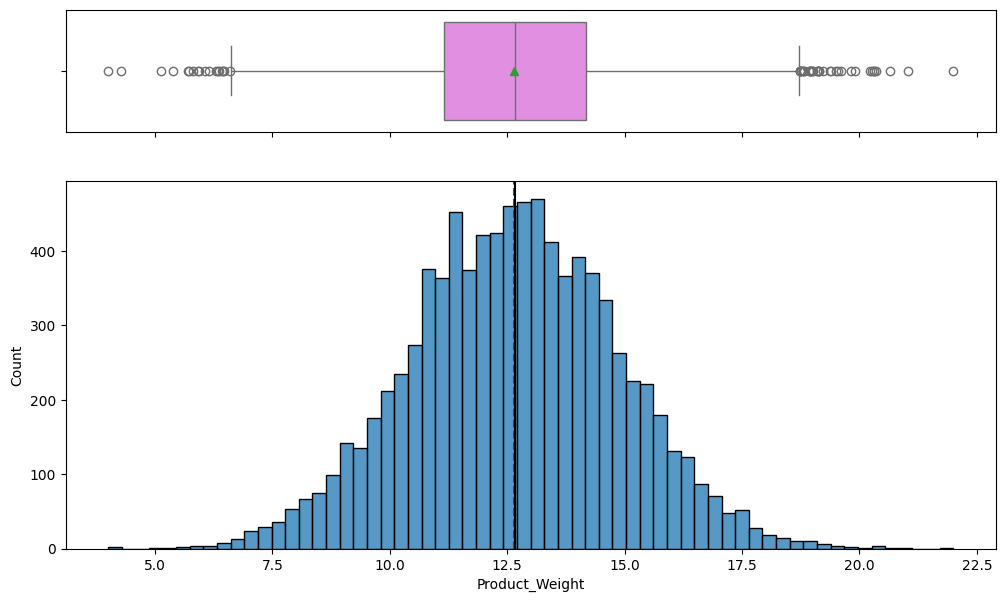

In [ ]:
histogram_boxplot(data, "Product_Weight")

### Univariate Analysis - Product_Weight

- The distribution of `Product_Weight` is approximately bell-shaped, centered around ~12.5, indicating a near-normal distribution.

- Most products fall within the range of 10 to 15 units, suggesting a relatively consistent weight range across the majority of items.

- A few outliers are observed on both ends:
  - Lower range (~4–6)
  - Higher range (~18–22)  
  These likely correspond to lightweight packaged items and bulk/heavy products.

- The mean and median are close, indicating minimal skewness and a fairly symmetric distribution.

- The feature shows moderate variability without extreme skewness, making it suitable for modeling without requiring significant transformation.

### Product_Allocated_Area

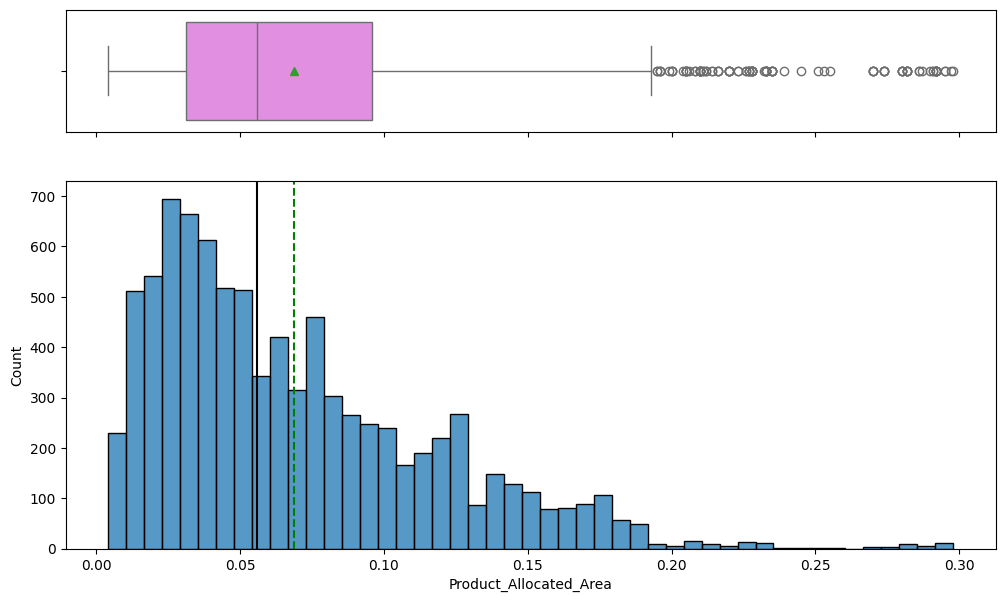

In [ ]:
histogram_boxplot(data, "Product_Allocated_Area")

### Univariate Analysis - Product_Allocated_Area

- The distribution of `Product_Allocated_Area` is right-skewed, with most values concentrated at lower levels.

- The majority of products have allocated area between approximately 0.02 and 0.08, indicating limited display space for most items.

- A small number of products have significantly higher allocation, resulting in a long right tail and presence of high-value outliers.

- This suggests that certain products are prioritized for greater visibility, while most products receive minimal shelf space.

- The uneven distribution of display space indicates potential influence on product visibility and, consequently, sales performance.

- Due to the skewness and presence of outliers, this feature may benefit from transformation (e.g., log scaling) depending on the modeling approach.

### Product_MRP

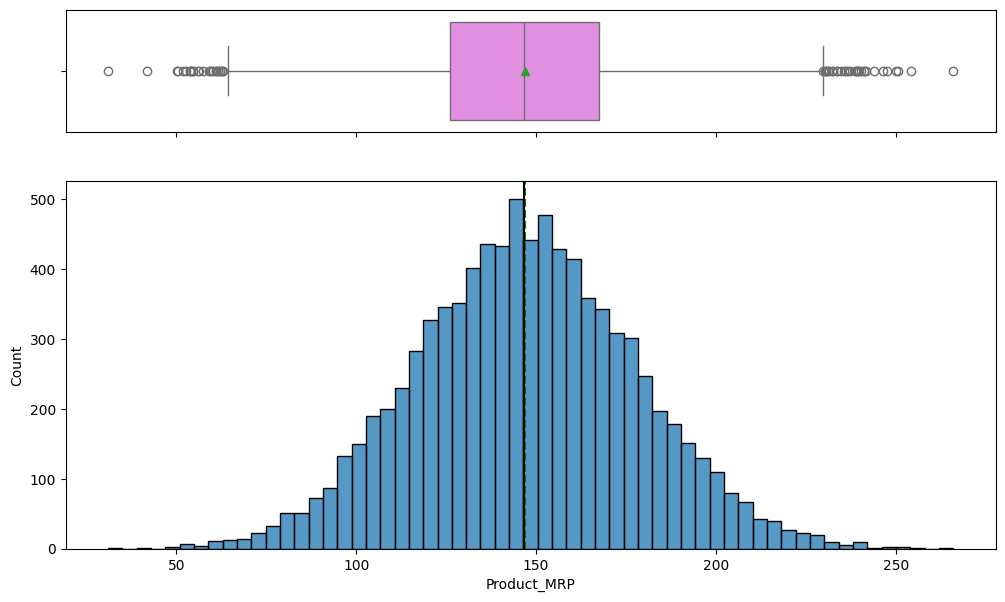

In [ ]:
histogram_boxplot(data, "Product_MRP")

### Univariate Analysis - Product_MRP

- The distribution of `Product_MRP` is approximately bell-shaped, centered around ~150, indicating a near-normal distribution.

- Most product prices fall within the range of 120 to 180, suggesting a relatively consistent pricing band across the majority of products.

- The distribution shows a broad spread from ~30 to ~266, reflecting the presence of both low-cost and premium-priced products.

- The mean and median are close, indicating minimal skewness and a fairly symmetric pricing distribution.

- The wide variability in pricing suggests that `Product_MRP` is likely to be a key driver of sales performance.

- Since the feature is well-distributed without extreme skewness, it is suitable for modeling without requiring significant transformation.

### Product_Store_Sales_Total

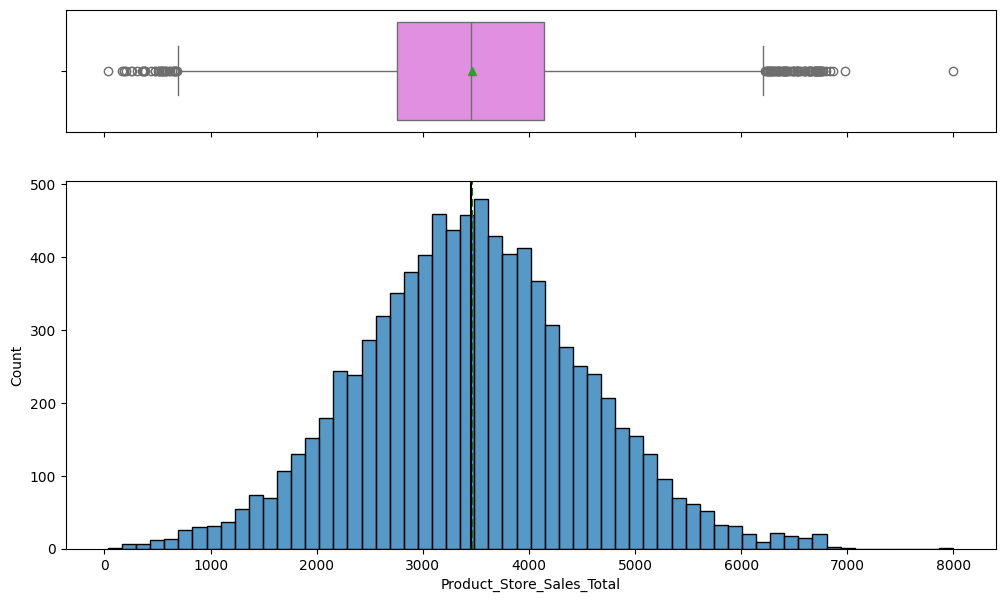

In [ ]:
histogram_boxplot(data, "Product_Store_Sales_Total")

#### Univariate Analysis - Product_Store_Sales_Total

- The distribution of `Product_Store_Sales_Total` is approximately bell-shaped, centered around ~3400, indicating a near-normal distribution.

- Most sales values fall within the range of 2500 to 4500, representing the typical performance band for the majority of product-store combinations.

- The distribution spans a wide range (from ~33 to ~8000), indicating the presence of both low-performing and high-performing products.

- The mean and median are close, suggesting minimal skewness and a fairly symmetric distribution.

- The variability in sales indicates that product performance differs significantly across products and stores.

- As the target variable, this distribution is suitable for regression modeling without requiring major transformation.

### Function to create labeled barplots

In [ ]:
def labeled_barplot(data, feature, perc=False, n=None):
    """
    Barplot with count/percentage labels + table of counts

    data: dataframe
    feature: column name
    perc: display percentages (default False)
    n: top n categories (default None = all)
    """

    total = len(data[feature])

    # Get counts
    count_df = data[feature].value_counts().reset_index()
    count_df.columns = [feature, "Count"]

    # Limit top n if needed
    if n is not None:
        count_df = count_df.head(n)

    # Add percentage column
    count_df["Percentage"] = (count_df["Count"] / total) * 100

    # ---- Plot ----
    plt.figure(figsize=(len(count_df) + 1, 5))

    ax = sns.countplot(
        data=data,
        x=feature,
        palette="Paired",
        order=count_df[feature]
    )

    plt.xticks(rotation=90, fontsize=12)

    for p in ax.patches:
        if perc:
            label = "{:.1f}%".format(100 * p.get_height() / total)
        else:
            label = int(p.get_height())

        x = p.get_x() + p.get_width() / 2
        y = p.get_height()

        ax.annotate(
            label,
            (x, y),
            ha="center",
            va="bottom",
            size=11,
            xytext=(0, 5),
            textcoords="offset points",
        )

    plt.title(f"Distribution of {feature}")
    plt.show()

    # ---- Table Output ----
    print(f"\nValue Counts for {feature}:")
    display(count_df)

### Product_Sugar_Content

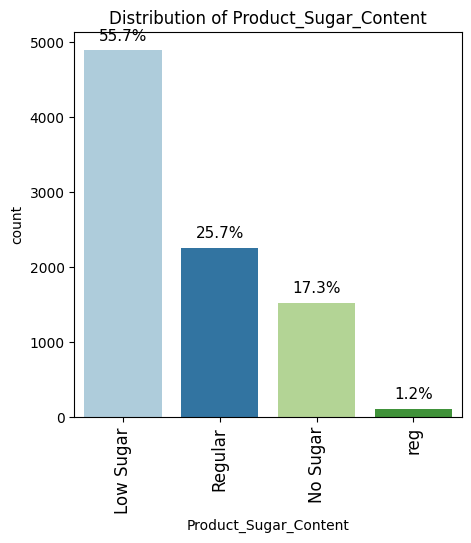


Value Counts for Product_Sugar_Content:


,Product_Sugar_Content,Count,Percentage
0,Low Sugar,4885,55.745749
1,Regular,2251,25.687550
2,No Sugar,1519,17.334246
3,reg,108,1.232455


In [ ]:
labeled_barplot(data, "Product_Sugar_Content", perc=True)

#### Univariate Analysis - Product_Sugar_Content

- The majority of products fall under the **Low Sugar** category (~56%), making it the dominant segment.

- **Regular** sugar products (~26%) represent the second largest group, followed by **No Sugar** products (~17%), indicating a diverse distribution of sugar content across products.

- A small proportion (~1%) is labeled as **"reg"**, which appears to be a data inconsistency likely referring to "Regular".

- This inconsistency indicates a need for **data cleaning**, where similar categories should be standardized before modeling.

- Overall, the distribution is skewed towards Low Sugar products, suggesting potential customer preference trends and making this feature relevant for segmentation and analysis.

### Product_Type

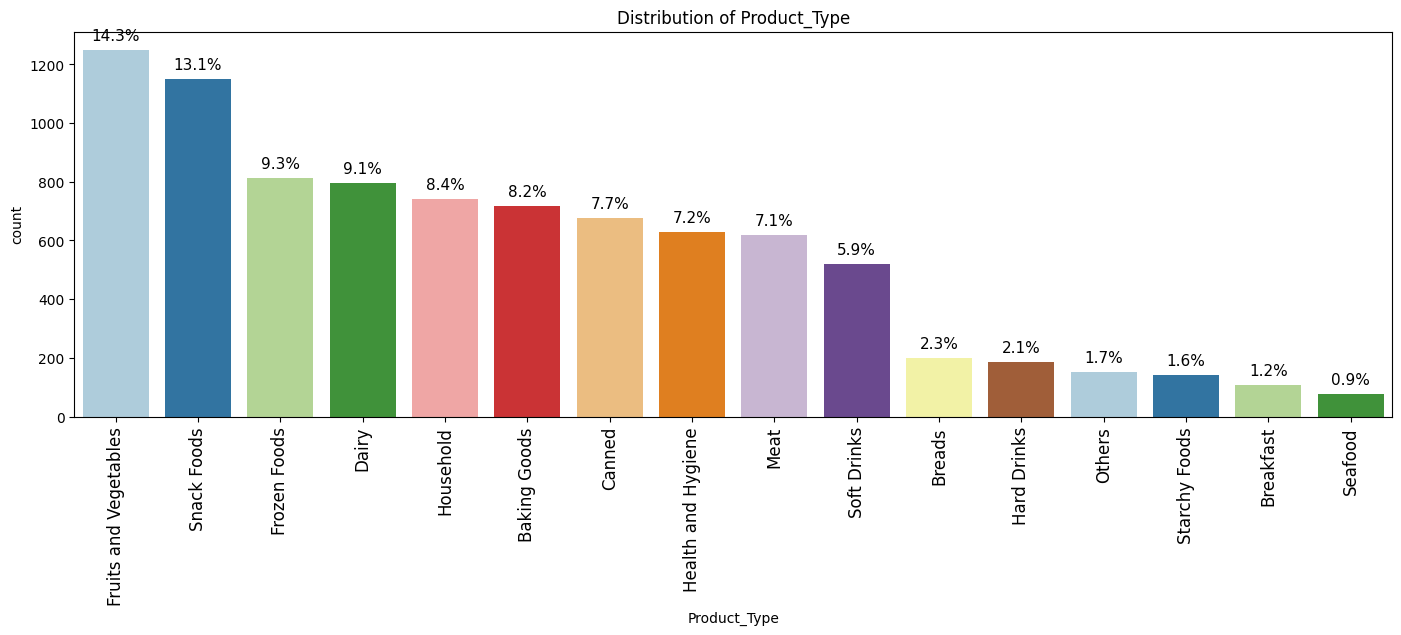


Value Counts for Product_Type:


,Product_Type,Count,Percentage
0,Fruits and Vegetables,1249,14.253110
1,Snack Foods,1149,13.111948
2,Frozen Foods,811,9.254821
3,Dairy,796,9.083647
4,Household,740,8.444597
5,Baking Goods,716,8.170718
6,Canned,677,7.725665
7,Health and Hygiene,628,7.166495
8,Meat,618,7.052379
9,Soft Drinks,519,5.922629


In [ ]:
labeled_barplot(data, "Product_Type", perc=True)

#### Univariate Analysis - Product_Type

- The dataset includes **16 product categories**, indicating a diverse product portfolio.

- **Fruits and Vegetables (~14%)** and **Snack Foods (~13%)** are the most frequent categories, representing a significant portion of the dataset.

- Mid-frequency categories such as **Frozen Foods, Dairy, and Household (~7–9%)** show relatively balanced representation across multiple product types.

- Several categories, including **Seafood, Breakfast, and Starchy Foods (<2%)**, have very low representation, indicating sparse data for these segments.

- Overall, the distribution is **moderately imbalanced**, with a few dominant categories and several low-frequency ones, which may influence model learning and require careful encoding.

### Store_Id

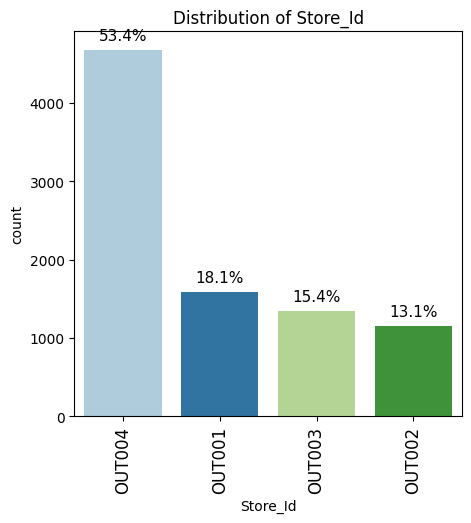


Value Counts for Store_Id:


,Store_Id,Count,Percentage
0,OUT004,4676,53.360721
1,OUT001,1586,18.098825
2,OUT003,1349,15.394271
3,OUT002,1152,13.146183


In [ ]:
labeled_barplot(data, "Store_Id", perc=True)

#### Univariate Analysis - Store_Id

- The dataset contains data from **4 stores**, indicating limited store-level diversity.

- **OUT004 (~53%)** contributes more than half of the observations, making it the most dominant store in the dataset.

- The remaining stores (**OUT001, OUT003, OUT002**) each contribute between **13% to 18%**, showing relatively balanced representation among them.

- The distribution is **significantly imbalanced**, with one store heavily dominating the dataset.

- This imbalance may bias the model toward patterns associated with the dominant store, and should be considered during model evaluation and validation.

### Store_Size

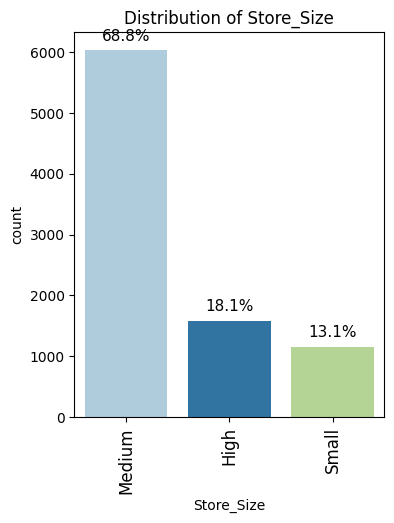


Value Counts for Store_Size:


,Store_Size,Count,Percentage
0,Medium,6025,68.754993
1,High,1586,18.098825
2,Small,1152,13.146183


In [ ]:
labeled_barplot(data, "Store_Size", perc=True)

#### Univariate Analysis - Store_Size

- The majority of stores are **Medium-sized (~69%)**, making it the most dominant category.

- **High-sized (~18%)** and **Small-sized (~13%)** stores are less represented in the dataset.

- The distribution is **heavily imbalanced**, with a strong concentration of medium-sized stores.

- This imbalance may cause the model to learn patterns that are more representative of medium-sized stores compared to other store types.

- Overall, the data suggests that a significant portion of sales activity is driven by medium-sized store operations.

### Store_Location_City_Type

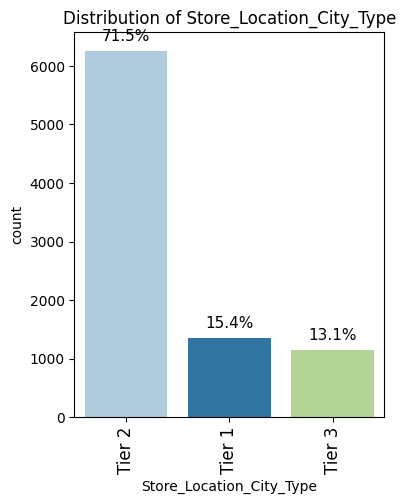


Value Counts for Store_Location_City_Type:


,Store_Location_City_Type,Count,Percentage
0,Tier 2,6262,71.459546
1,Tier 1,1349,15.394271
2,Tier 3,1152,13.146183


In [ ]:
labeled_barplot(data, "Store_Location_City_Type", perc=True)

#### Univariate Analysis - Store_Location_City_Type

- The majority of stores are located in **Tier 2 cities (~71%)**, making it the most dominant category.

- **Tier 1 (~15%)** and **Tier 3 (~13%)** cities have significantly lower representation in the dataset.

- The distribution is **highly imbalanced**, with a strong concentration in Tier 2 locations.

- This imbalance may cause the model to learn patterns that are more representative of Tier 2 markets compared to other city types.

- Overall, the dataset suggests a stronger operational presence in mid-tier (Tier 2) cities, which may influence observed sales patterns.

### Store_Type

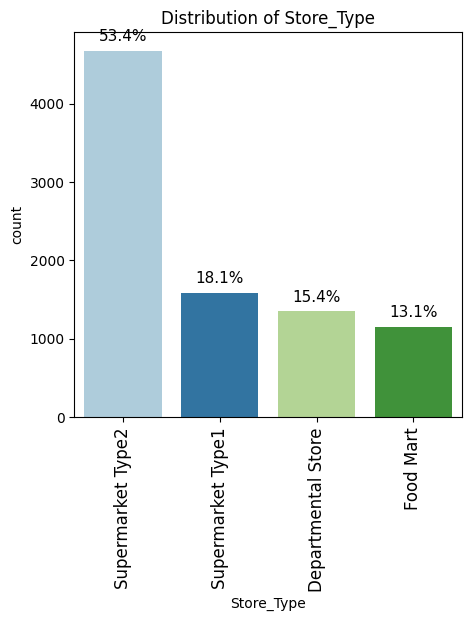


Value Counts for Store_Type:


,Store_Type,Count,Percentage
0,Supermarket Type2,4676,53.360721
1,Supermarket Type1,1586,18.098825
2,Departmental Store,1349,15.394271
3,Food Mart,1152,13.146183


In [ ]:
labeled_barplot(data, "Store_Type", perc=True)

#### Univariate Analysis - Store_Type

- **Supermarket Type2 (~53%)** is the most dominant store format, contributing over half of the observations.

- **Supermarket Type1 (~18%)** and **Departmental Store (~15%)** show moderate representation in the dataset.

- **Food Mart (~13%)** is the least represented store type.

- The distribution is **imbalanced**, with a strong dominance of supermarket formats, particularly Supermarket Type2.

- This imbalance may cause the model to learn patterns that are more representative of Supermarket Type2 stores compared to other store formats.

### Overall Observation - Univariate Analysis

- The dataset contains a mix of well-distributed numerical features (e.g., `Product_Weight`, `Product_MRP`) and skewed features (e.g., `Product_Allocated_Area`), with some presence of outliers.

- The variability in numerical features such as price and sales indicates that product performance is influenced by multiple factors, making the dataset suitable for predictive modeling.

- Categorical variables exhibit noticeable imbalance, with certain categories (e.g., Medium store size, Tier 2 locations, Supermarket Type2) dominating the dataset.

- This imbalance suggests that a significant portion of sales activity is driven by specific store types and locations, which may influence overall sales patterns and model predictions.

- A minor data quality issue is observed in `Product_Sugar_Content` (e.g., "reg" vs "Regular"), indicating the need for category standardization during preprocessing.

- From a business perspective, the dominance of certain product categories, store sizes, and city tiers suggests underlying operational or customer preference patterns that may impact sales performance.

- Overall, the dataset is clean and well-structured; however, skewness in certain features and imbalance in categorical variables should be carefully handled during preprocessing and model evaluation to ensure robust performance.

## Bivariate Analysis

### Correlation matrix

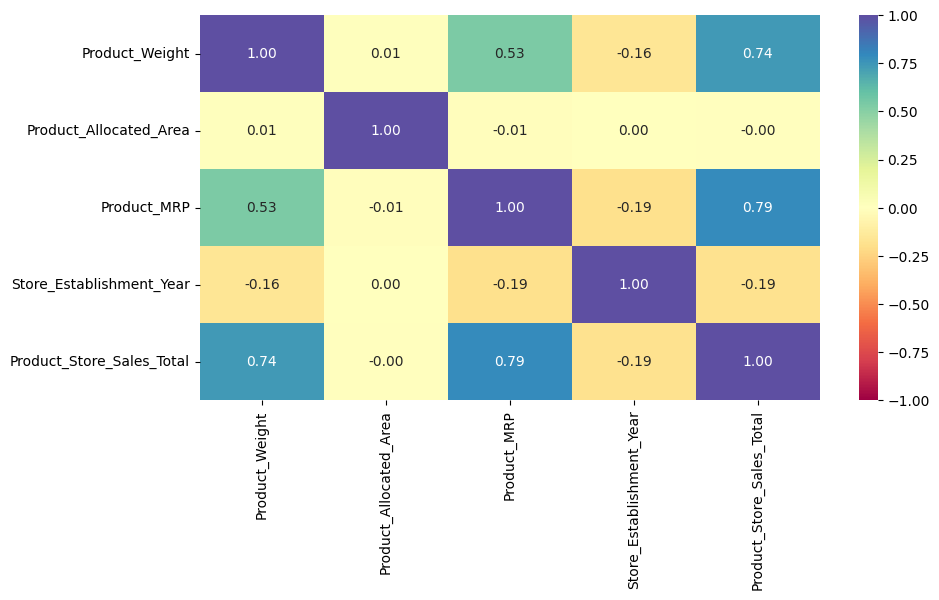

In [ ]:
cols_list = data.select_dtypes(include=np.number).columns.tolist()

plt.figure(figsize=(10, 5))
sns.heatmap(
    data[cols_list].corr(), annot=True, vmin=-1, vmax=1, fmt=".2f", cmap="Spectral"
)
plt.show()

#### Bivariate Analysis - Correlation Matrix

- `Product_MRP` shows a strong positive correlation with `Product_Store_Sales_Total`, indicating that higher-priced products tend to generate higher revenue.

- `Product_Weight` shows a positive correlation with sales, suggesting that heavier products may be associated with higher sales, though this relationship may be indirect.

- `Product_MRP` and `Product_Weight` have a moderate positive correlation, indicating that heavier products are often priced higher.

- `Product_Allocated_Area` shows negligible correlation with sales, suggesting that display space alone may not directly influence revenue.

- `Store_Establishment_Year` has a weak negative correlation with sales, indicating minimal linear impact of store age on product-level revenue.

- Overall, `Product_MRP` emerges as the most influential numerical feature, while other variables show weaker linear relationships with sales.

### Product_Store_Sales_Total with other numeric columns

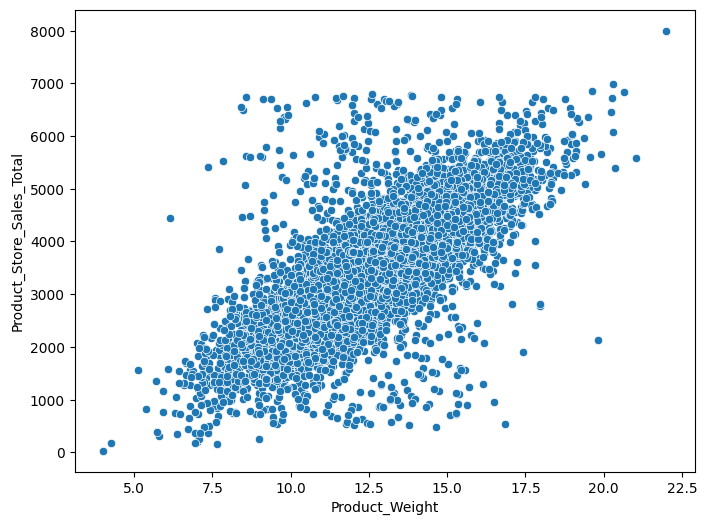

In [ ]:
plt.figure(figsize=[8, 6])
sns.scatterplot(x=data.Product_Weight, y=data.Product_Store_Sales_Total)
plt.show()

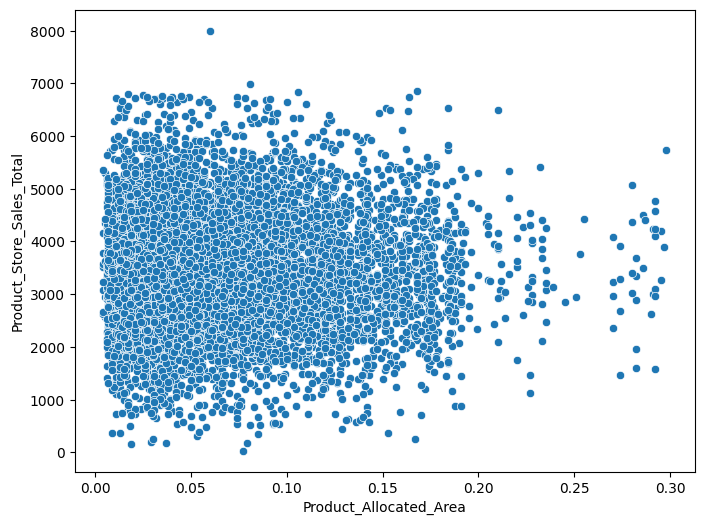

In [ ]:
plt.figure(figsize=[8, 6])
sns.scatterplot(x=data.Product_Allocated_Area, y=data.Product_Store_Sales_Total)
plt.show()

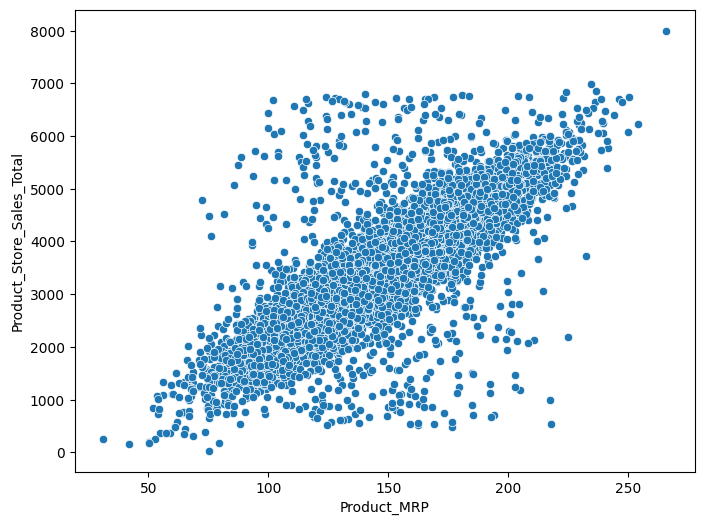

In [ ]:
plt.figure(figsize=[8, 6])
sns.scatterplot(x=data.Product_MRP, y=data.Product_Store_Sales_Total)
plt.show()

#### Bivariate Analysis - Product_Store_Sales_Total vs Numerical Features

- The scatter plot between `Product_MRP` and `Product_Store_Sales_Total` shows a **clear positive linear trend**, indicating that higher-priced products generally generate higher sales revenue. This suggests that price is a strong driver of revenue.

- The relationship between `Product_Weight` and sales appears **weak to moderate**, with a wide spread of points and no strong linear pattern. While heavier products may sometimes be associated with higher sales, the relationship is not consistent, indicating that weight alone is not a primary driver of revenue.

- The scatter plot for `Product_Allocated_Area` shows **no clear relationship with sales**, with points scattered randomly. This suggests that display space allocation alone does not directly influence product-level revenue.

- Across all plots, there is noticeable variability in sales for similar feature values, indicating that **multiple factors (e.g., product type, store characteristics)** jointly influence sales performance.

- The presence of some extreme values (high sales or high feature values) suggests potential outliers, but they do not significantly distort the overall patterns.

- Overall, `Product_MRP` emerges as the **most influential numerical feature**, while other variables show weaker or indirect relationships with sales.

- The relationships observed are primarily linear; further analysis may be required to capture potential non-linear patterns.

### Revenue Contribution by Product Category

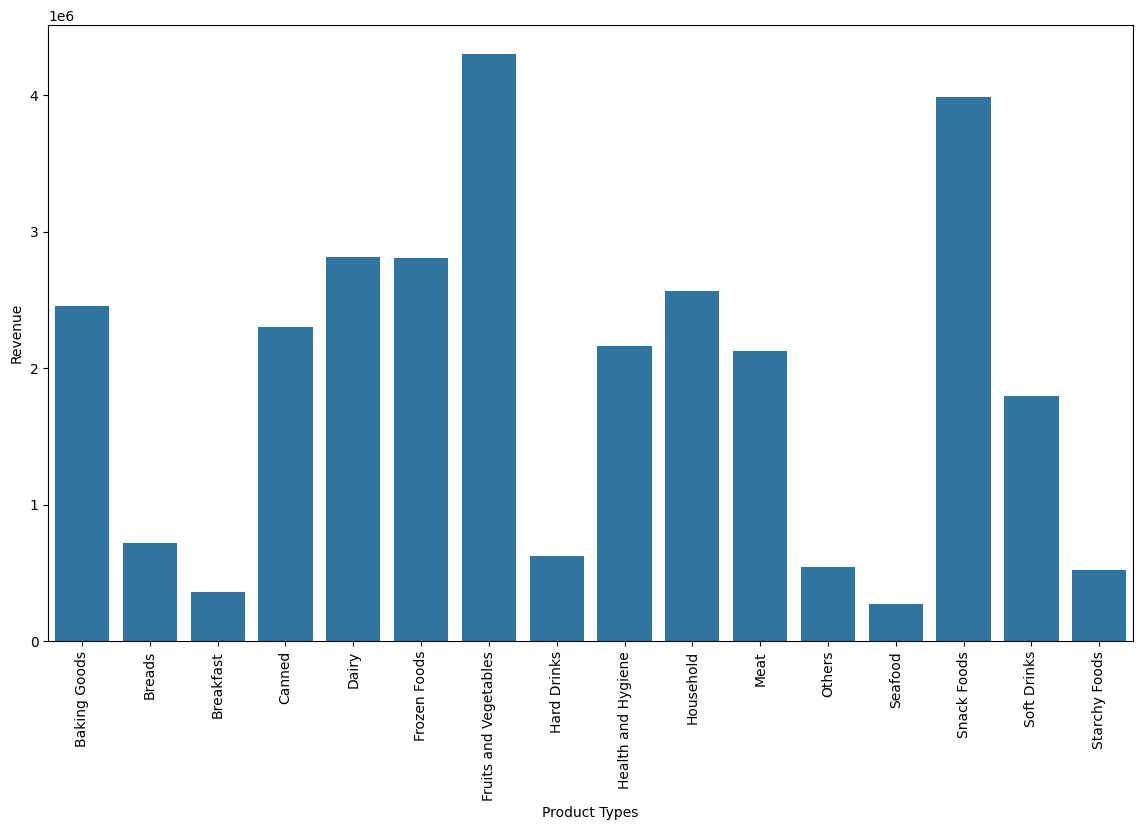

In [ ]:
df_revenue1 = data.groupby(["Product_Type"], as_index=False)[
    "Product_Store_Sales_Total"
].sum()
plt.figure(figsize=[14, 8])
plt.xticks(rotation=90)
a = sns.barplot(x=df_revenue1.Product_Type, y=df_revenue1.Product_Store_Sales_Total)
a.set_xlabel("Product Types")
a.set_ylabel("Revenue")
plt.show()

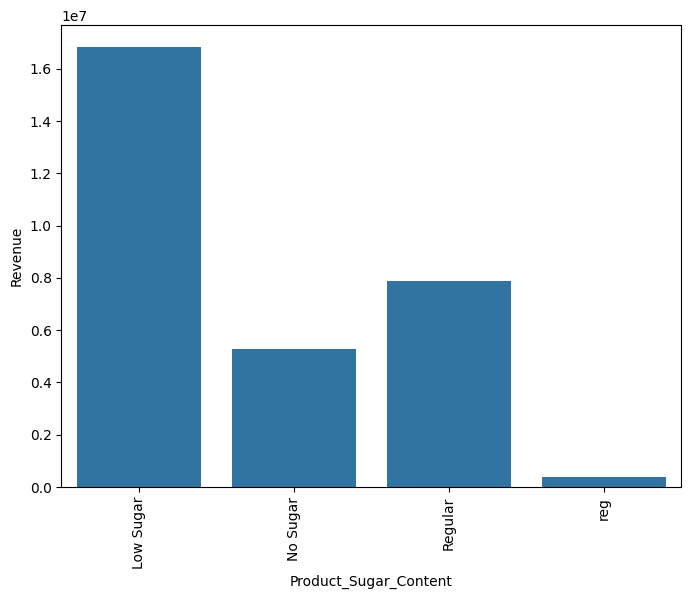

In [ ]:
df_revenue2 = data.groupby(["Product_Sugar_Content"], as_index=False)[
    "Product_Store_Sales_Total"
].sum()

plt.figure(figsize=[8, 6])
plt.xticks(rotation=90)

b = sns.barplot(
    x=df_revenue2.Product_Sugar_Content,
    y=df_revenue2.Product_Store_Sales_Total
)

b.set_xlabel("Product_Sugar_Content")
b.set_ylabel("Revenue")
plt.show()

#### Bivariate Analysis - Revenue Contribution by Product Category

- **Fruits and Vegetables** and **Snack Foods** generate the highest total revenue, making them the most significant contributors to overall sales.

- These categories are also among the most frequently occurring, indicating that their high revenue is driven largely by **high sales volume**.

- Mid-performing categories such as **Frozen Foods, Dairy, and Household** show steady revenue contribution, suggesting a balanced combination of demand and pricing.

- Certain categories like **Seafood, Breakfast, and Others** contribute minimally to total revenue, which may be due to **low demand, limited product availability, or lower sales frequency**.

- A comparison of frequency and revenue indicates that not all categories with high counts generate proportionally high revenue, suggesting that **pricing and product value also play a significant role**.

- The variation across categories highlights differences in **customer demand, pricing strategies, and product mix**, influencing overall revenue contribution.

- Overall, a small number of high-performing categories drive a significant portion of revenue, indicating opportunities to:
  - Focus inventory and promotions on top-performing categories  
  - Improve positioning or pricing strategies for underperforming categories  

### Revenue Contribution by Store & Location Attributes

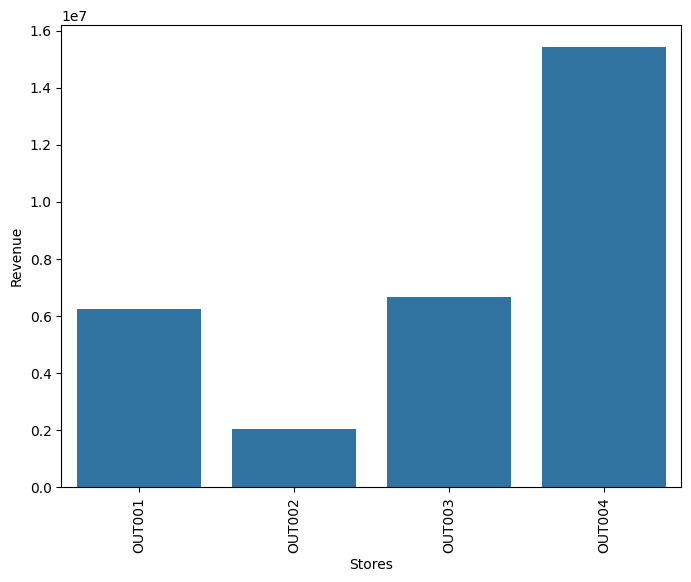

In [ ]:
# Revenue by Store_Id
df_store_revenue = data.groupby(["Store_Id"], as_index=False)[
    "Product_Store_Sales_Total"
].sum()

plt.figure(figsize=[8, 6])
plt.xticks(rotation=90)

r = sns.barplot(
    x=df_store_revenue.Store_Id,
    y=df_store_revenue.Product_Store_Sales_Total
)

r.set_xlabel("Stores")
r.set_ylabel("Revenue")
plt.show()

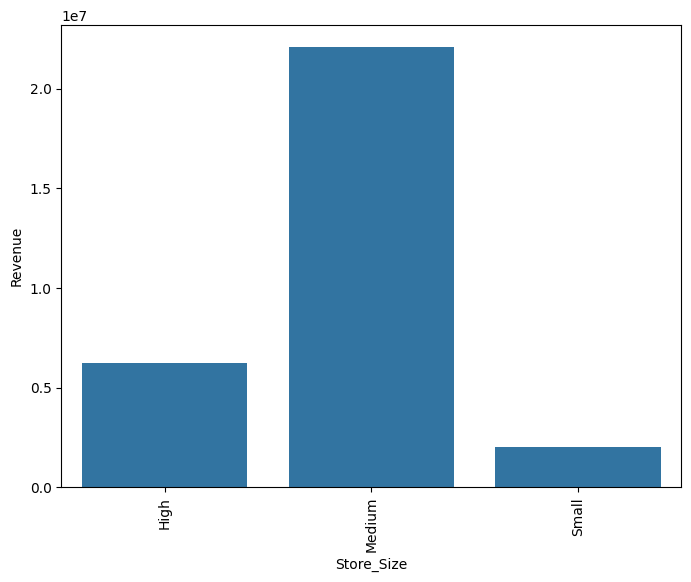

In [ ]:
# Revenue by Store_Size
df_revenue3 = data.groupby(["Store_Size"], as_index=False)[
    "Product_Store_Sales_Total"
].sum()

plt.figure(figsize=[8, 6])
plt.xticks(rotation=90)

c = sns.barplot(
    x=df_revenue3.Store_Size,
    y=df_revenue3.Product_Store_Sales_Total
)

c.set_xlabel("Store_Size")
c.set_ylabel("Revenue")
plt.show()

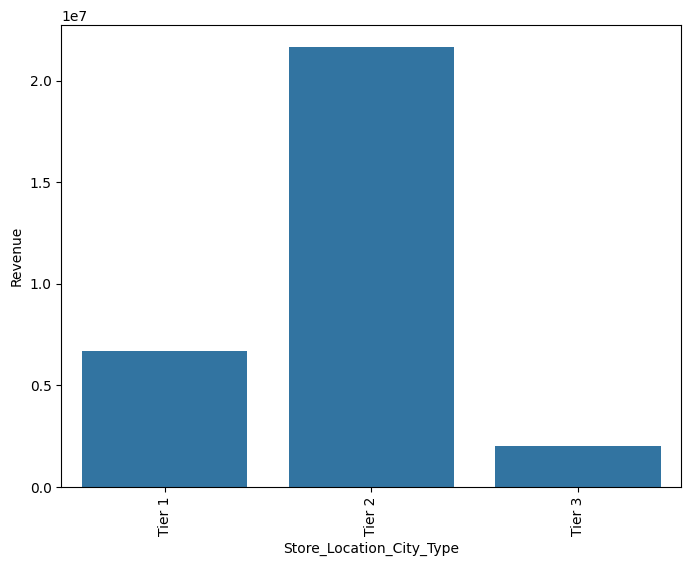

In [ ]:
# Revenue by Store_Location_City_Type
df_revenue4 = data.groupby(["Store_Location_City_Type"], as_index=False)[
    "Product_Store_Sales_Total"
].sum()

plt.figure(figsize=[8, 6])
plt.xticks(rotation=90)

d = sns.barplot(
    x=df_revenue4.Store_Location_City_Type,
    y=df_revenue4.Product_Store_Sales_Total
)

d.set_xlabel("Store_Location_City_Type")
d.set_ylabel("Revenue")
plt.show()

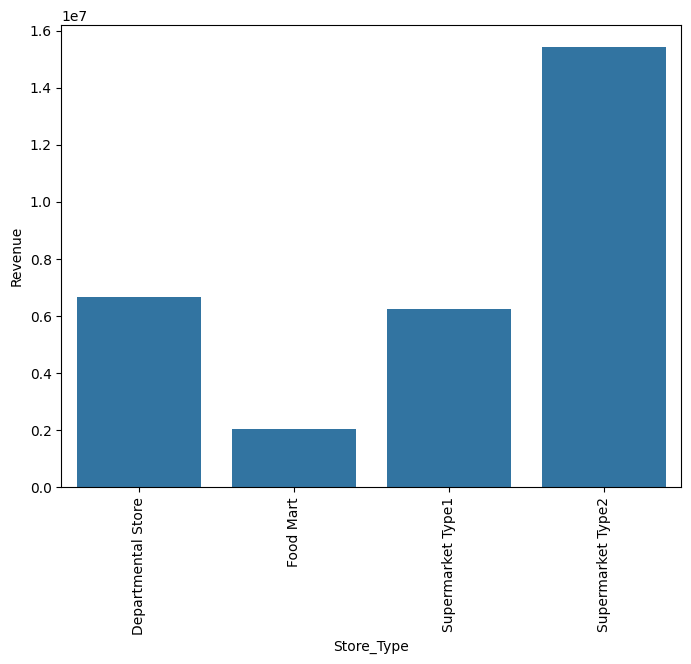

In [ ]:
# Revenue by Store_Type
df_revenue5 = data.groupby(["Store_Type"], as_index=False)[
    "Product_Store_Sales_Total"
].sum()

plt.figure(figsize=[8, 6])
plt.xticks(rotation=90)

e = sns.barplot(
    x=df_revenue5.Store_Type,
    y=df_revenue5.Product_Store_Sales_Total
)

e.set_xlabel("Store_Type")
e.set_ylabel("Revenue")
plt.show()

#### Bivariate Analysis - Revenue Contribution by Store & Location Attributes

- **Revenue by Store_Id**:
  - Store **OUT004 generates the highest total revenue**, significantly exceeding other stores.
  - However, this may be influenced by its higher representation in the dataset, suggesting that volume plays a key role in total revenue contribution.

- **Revenue by Store_Type**:
  - **Supermarket Type2** contributes the highest revenue, followed by Supermarket Type1.
  - Lower contributions from **Food Mart** indicate either lower sales volume, limited product variety, or smaller store operations.

- **Revenue by Store_Location_City_Type**:
  - **Tier 2 cities show the highest total revenue**, suggesting strong demand in mid-tier markets.
  - Lower revenue from Tier 1 and Tier 3 may reflect differences in store distribution, customer behavior, or purchasing patterns.

- **Revenue by Store_Size**:
  - **Medium-sized stores generate the highest total revenue**, followed by high-sized stores.
  - Smaller stores contribute the least, likely due to limited capacity, inventory, or customer reach.

- Across all attributes, higher revenue contributions are often associated with categories that have **greater representation in the dataset**, indicating that both **store scale and frequency of observations (volume)** influence total revenue.

- Overall, store characteristics such as **size, location, and format** play an important role in sales performance, but their impact should be further validated using normalized or average metrics to isolate true performance differences.

### Sales Distribution Across Store Attributes

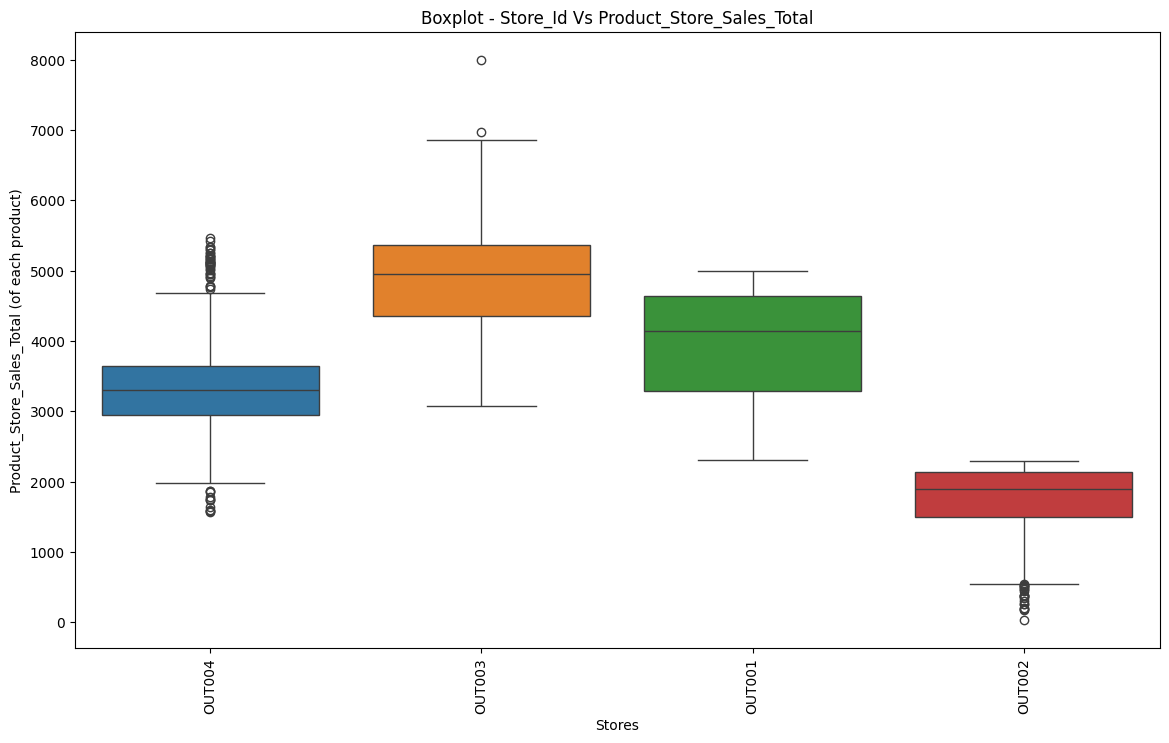

In [ ]:
plt.figure(figsize=[14, 8])
sns.boxplot(data=data, x="Store_Id", y="Product_Store_Sales_Total", hue = "Store_Id")
plt.xticks(rotation=90)
plt.title("Boxplot - Store_Id Vs Product_Store_Sales_Total")
plt.xlabel("Stores")
plt.ylabel("Product_Store_Sales_Total (of each product)")
plt.show()

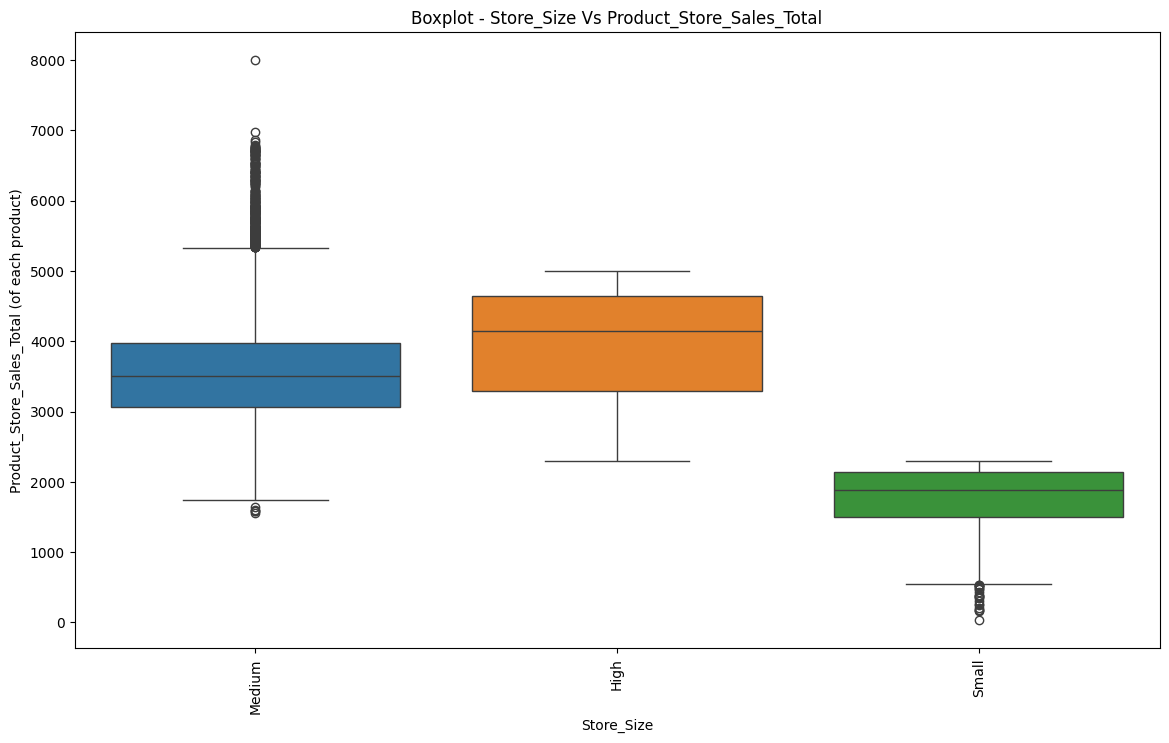

In [ ]:
plt.figure(figsize=[14, 8])

sns.boxplot(
    data=data,
    x="Store_Size",
    y="Product_Store_Sales_Total",
    hue="Store_Size"
)

plt.xticks(rotation=90)
plt.title("Boxplot - Store_Size Vs Product_Store_Sales_Total")
plt.xlabel("Store_Size")
plt.ylabel("Product_Store_Sales_Total (of each product)")
plt.show()

#### Bivariate Analysis - Sales Distribution Across Store Attributes

- **Sales vs Store_Size**:
  - High-sized stores show higher median sales compared to medium and small stores, indicating that larger stores tend to generate greater revenue.
  - Small stores have noticeably lower median sales, suggesting limitations in capacity, inventory, or customer reach.
  - The spread (IQR) is wider for larger stores, indicating greater variability in sales performance across products.

- **Sales vs Store_Id**:
  - Certain stores (e.g., OUT003 and OUT001) show higher median sales compared to others, suggesting relatively stronger performance.
  - Stores like OUT002 exhibit lower median sales and tighter distributions, indicating more consistent but lower sales levels.
  - Differences across store IDs may reflect variations in store size, location, or operational efficiency.

- Across both plots, the presence of outliers indicates that some products achieve exceptionally high sales regardless of store attributes.

- Overall, store characteristics such as size and individual store differences influence sales distribution, but variability within each category suggests that **product-level factors also play a significant role** in determining revenue.

### Product Weight Across Product Categories

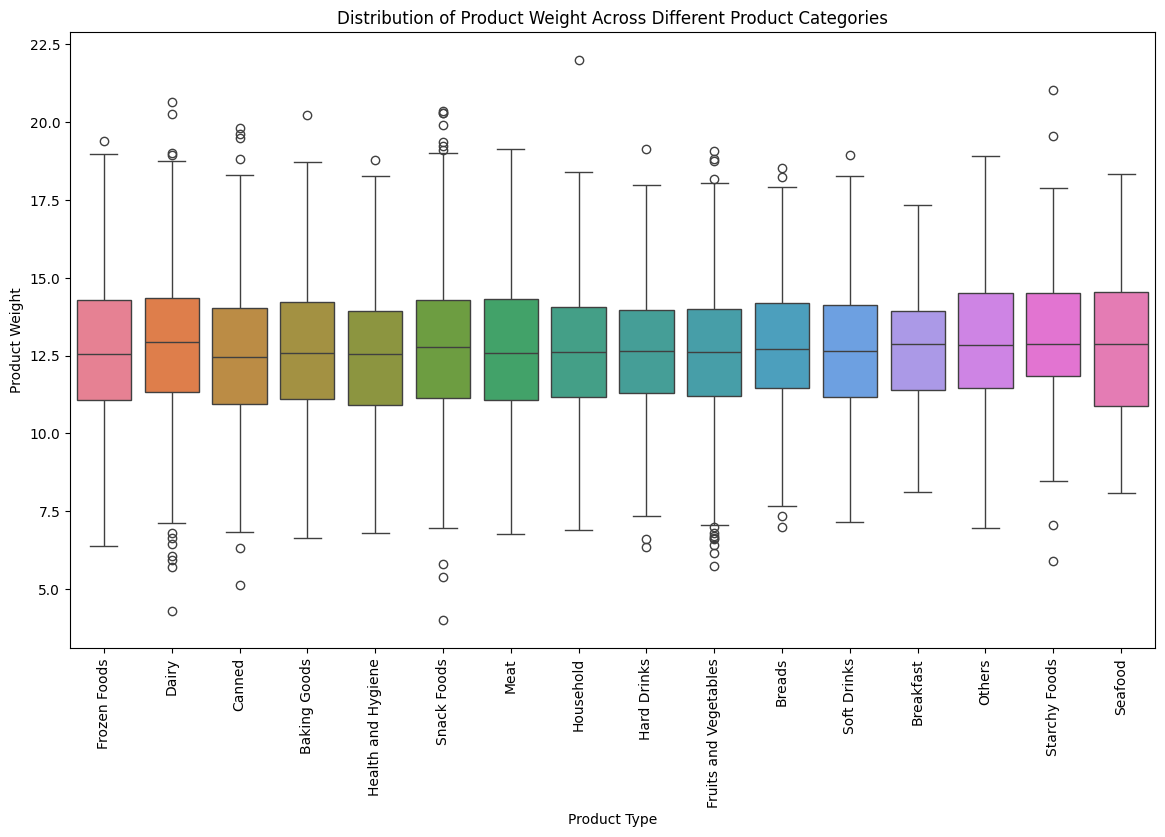

In [ ]:
plt.figure(figsize=[14, 8])

sns.boxplot(
    data=data,
    x="Product_Type",
    y="Product_Weight",
    hue="Product_Type"
)

plt.xticks(rotation=90)
plt.title("Distribution of Product Weight Across Different Product Categories")
plt.xlabel("Product Type")
plt.ylabel("Product Weight")
plt.show()

#### Bivariate Analysis - Product Weight Across Product Categories

- The median product weight is **fairly consistent across most categories**, typically ranging between 12 and 13 units.

- Some categories such as **Starchy Foods and Seafood** show slightly higher median weights, while most others remain close to the overall average.

- The spread (IQR) is similar across categories, indicating **limited variation in weight distribution** within each product type.

- The presence of outliers across multiple categories suggests that certain products deviate significantly in weight, possibly due to bulk packaging or specialized items.

- The overlapping distributions across categories indicate that **product weight does not strongly differentiate product types**.

- Overall, the consistency in product weight suggests a level of **standardization in packaging or product sizing**, and indicates that weight alone may have limited importance in distinguishing between product categories or driving sales.

### Product Weight Across Sugar Content Categories

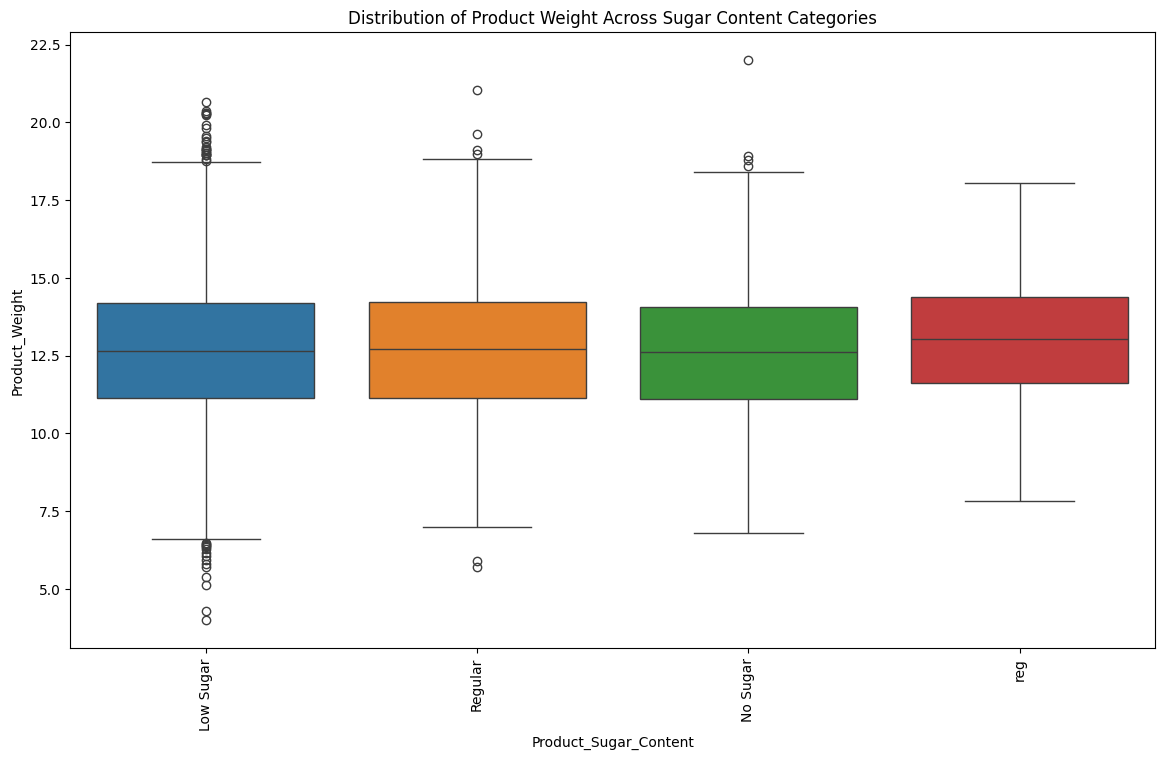

In [ ]:
plt.figure(figsize=[14, 8])

sns.boxplot(
    data=data,
    x="Product_Sugar_Content",
    y="Product_Weight",
    hue="Product_Sugar_Content"
)

plt.xticks(rotation=90)
plt.title("Distribution of Product Weight Across Sugar Content Categories")
plt.xlabel("Product_Sugar_Content")
plt.ylabel("Product_Weight")
plt.show()

#### Bivariate Analysis - Product Weight Across Sugar Content Categories

- The median product weight is very similar across all sugar content categories, indicating minimal variation in central tendency.

- Categories such as **Low Sugar, Regular, and No Sugar** show highly overlapping distributions, suggesting similar weight ranges across different sugar content types.

- The spread (IQR) is consistent across categories, indicating uniform variability in product weight within each group.

- The presence of outliers across all categories suggests that extreme weight values occur regardless of sugar content.

- The significant overlap in distributions indicates that **product weight does not strongly vary with sugar content**, and no clear relationship is observed between these features.

- From a modeling perspective, this suggests that `Product_Weight` and `Product_Sugar_Content` are likely to contribute **independently** to predictions, with limited interaction between them.

### Bivariate Analysis - Product Weight Across Sugar Content Categories

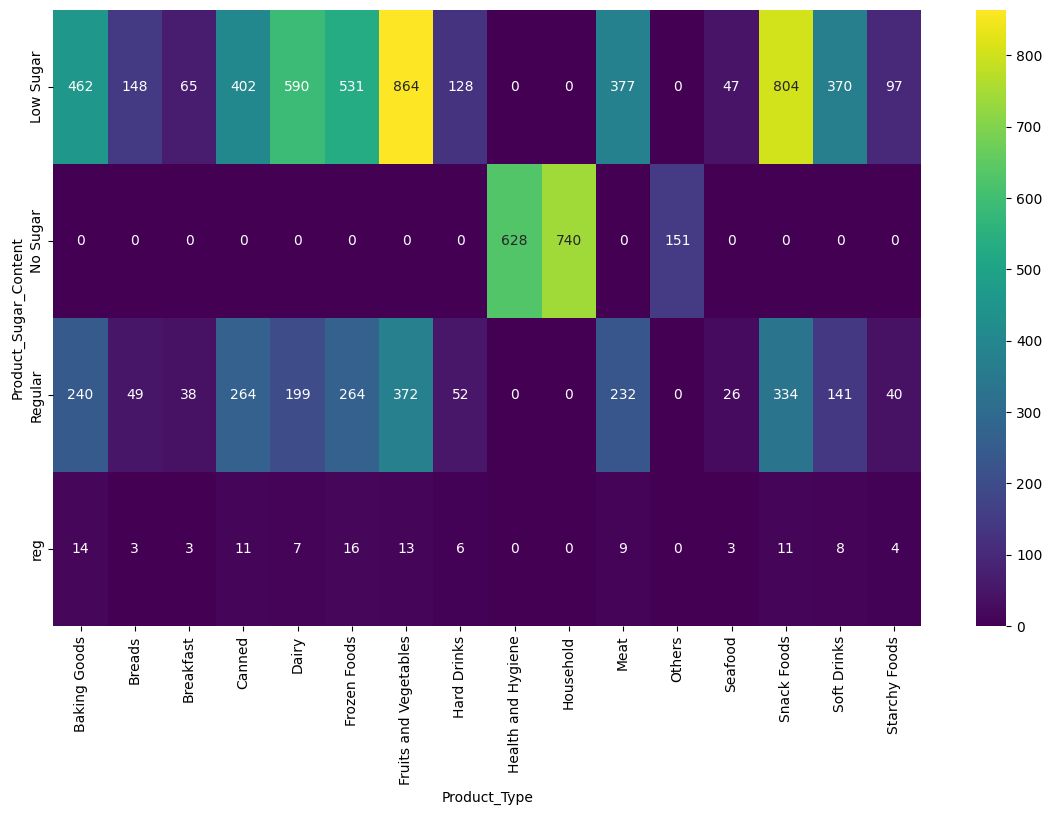

In [ ]:
plt.figure(figsize=(14, 8))
sns.heatmap(
    pd.crosstab(data["Product_Sugar_Content"], data["Product_Type"]),
    annot=True,
    fmt="g",
    cmap="viridis",
)
plt.ylabel("Product_Sugar_Content")
plt.xlabel("Product_Type")
plt.show()

#### Bivariate Analysis - Product Weight Across Sugar Content Categories

- The median product weight is **very similar across all sugar content categories**, indicating minimal variation in central tendency.

- Categories such as **Low Sugar, Regular, and No Sugar** show highly overlapping distributions, suggesting similar weight ranges across different sugar content types.

- The spread (IQR) is consistent across categories, indicating **uniform variability in product weight** within each group.

- The presence of outliers across all categories suggests that extreme weight values occur regardless of sugar content.

- The strong overlap in distributions indicates that **product weight does not significantly vary with sugar content**, and no clear relationship is observed between these features.

- From a modeling perspective, this suggests that `Product_Weight` and `Product_Sugar_Content` contribute **independently to predictions with minimal interaction**, and combining them may not provide additional predictive value.

### Bivariate Analysis - Product Distribution Across Stores

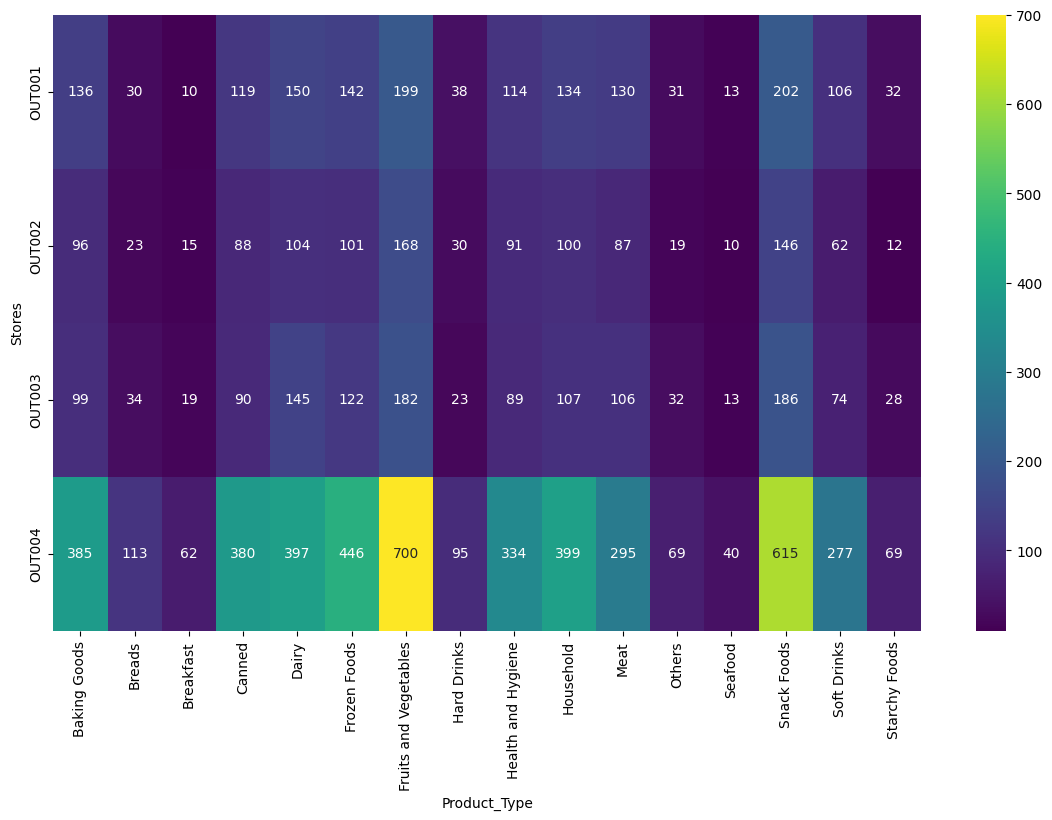

In [ ]:
plt.figure(figsize=(14, 8))

sns.heatmap(
    pd.crosstab(data["Store_Id"], data["Product_Type"]),
    annot=True,
    fmt="g",
    cmap="viridis",
)

plt.ylabel("Stores")
plt.xlabel("Product_Type")
plt.show()

#### Bivariate Analysis - Product Distribution Across Stores

- **OUT004 shows the highest counts across almost all product categories**, indicating that it has the highest representation in the dataset.

- Categories such as **Fruits and Vegetables** and **Snack Foods** consistently have the highest counts across all stores, suggesting strong presence and demand for these product types.

- **OUT002 has the lowest counts across categories**, indicating relatively lower representation compared to other stores.

- The distribution pattern of product categories is **fairly consistent across all stores**, suggesting a similar product mix and standardized assortment across store formats.

- The differences in total counts across stores appear to be driven more by **store representation (volume of data)** rather than significant differences in product category composition.

- Overall, while store-level differences influence the number of products available, the **relative popularity of product categories remains consistent**, indicating stable customer demand patterns across stores.

### Bivariate Analysis - Price Distribution Across Product Categories

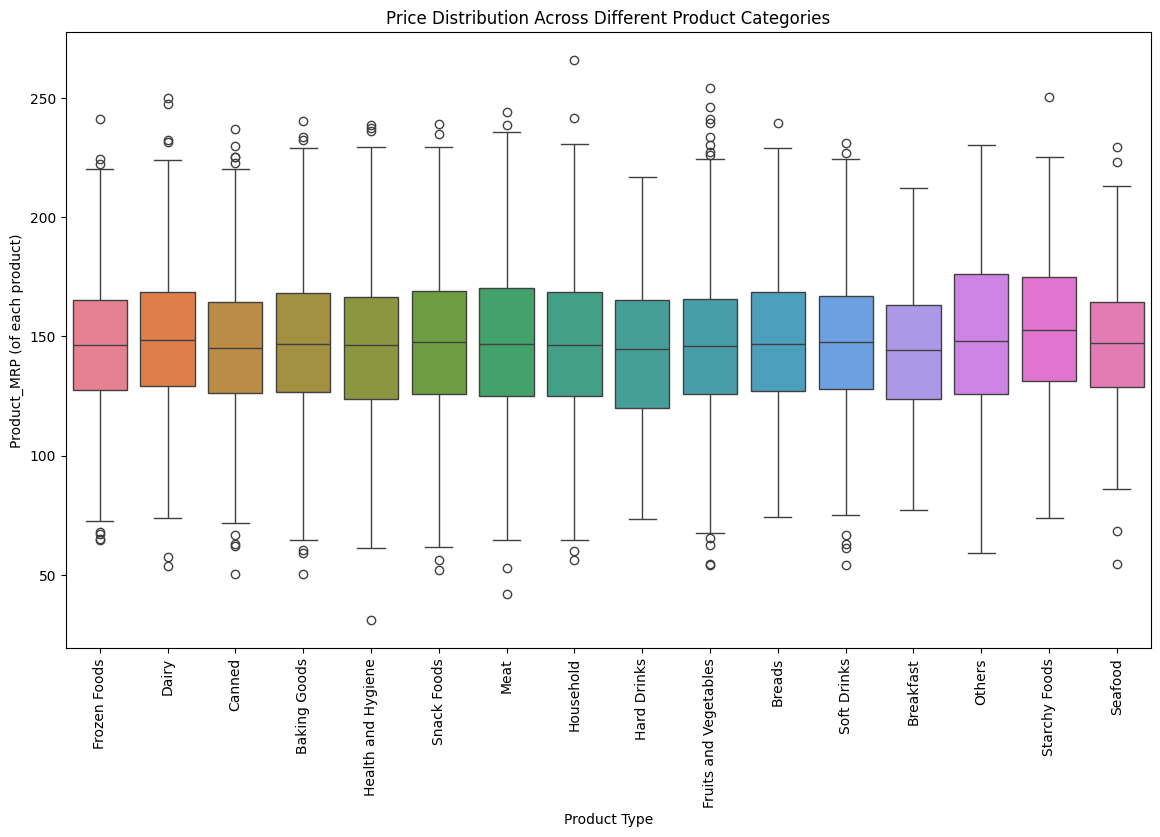

In [ ]:
plt.figure(figsize=[14, 8])

sns.boxplot(
    data=data,
    x="Product_Type",
    y="Product_MRP",
    hue="Product_Type"
)

plt.xticks(rotation=90)
plt.title("Price Distribution Across Different Product Categories")
plt.xlabel("Product Type")
plt.ylabel("Product_MRP (of each product)")
plt.show()

#### Bivariate Analysis - Price Distribution Across Product Categories

- The **median price (MRP) is fairly consistent across most product categories**, indicating a similar overall pricing range.

- Some categories such as **Starchy Foods, Others, and Snack Foods** show slightly higher median prices, while categories like **Breakfast, Hard Drinks, and Health and Hygiene** tend to have relatively lower medians.

- There is **significant overlap in price distributions across categories**, suggesting that pricing is not strongly differentiated by product type.

- The presence of outliers across most categories indicates that both **premium and budget-priced products exist within each category**, reflecting pricing diversity.

- The overlapping distributions indicate that **product category alone is not a strong determinant of price**, and other factors (such as brand, quality, or packaging) may play a more significant role.

- From a modeling perspective, this suggests that while `Product_MRP` is an important feature, its variation is not strongly dependent on `Product_Type`, and both features may contribute independently to predictions.

### **Price Distribution of Products Across Stores**

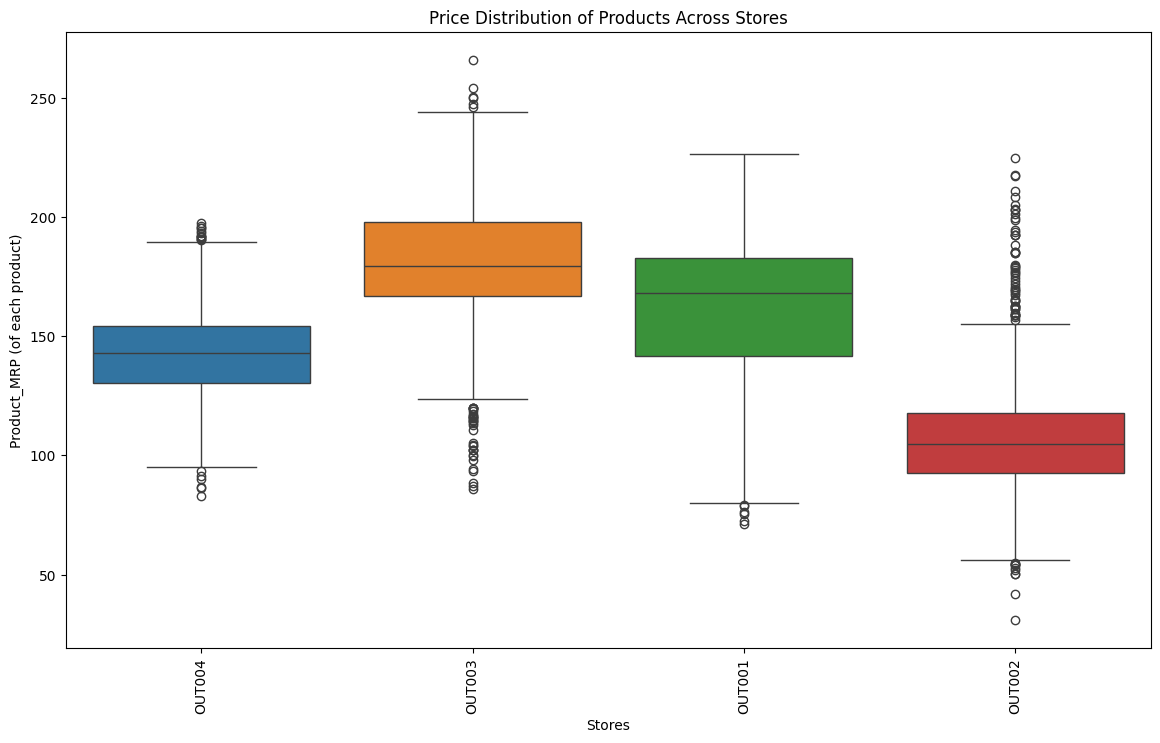

In [ ]:
plt.figure(figsize=[14, 8])

sns.boxplot(
    data=data,
    x="Store_Id",
    y="Product_MRP",
    hue="Store_Id"
)

plt.xticks(rotation=90)
plt.title("Price Distribution of Products Across Stores")
plt.xlabel("Stores")
plt.ylabel("Product_MRP (of each product)")
plt.show()

#### Bivariate Analysis - Price Distribution of Products Across Stores

- **OUT003 shows the highest median product price**, indicating that products in this store are generally priced higher compared to others.

- **OUT001 also exhibits relatively higher median prices**, though slightly lower than OUT003.

- **OUT004 shows a mid-range price distribution**, with prices clustered around the overall average.

- **OUT002 has the lowest median price**, suggesting a tendency toward lower-priced products.

- The **spread (IQR) is wider for OUT003 and OUT001**, indicating a broader range of product pricing in these stores.

- **OUT002 shows a relatively tighter distribution**, suggesting more consistency in pricing within a lower price range.

- The presence of **outliers across all stores** indicates that both premium and budget-priced products are available in every store.

- Despite differences in median pricing, there is **considerable overlap in price distributions across stores**, suggesting that pricing ranges are not entirely distinct between stores.

- Overall, while there are differences in central pricing tendencies across stores, **pricing variation exists within each store**, and store-level pricing differences alone may not fully explain sales performance.

### Overall Observation - Bivariate Analysis

- `Product_MRP` shows the strongest positive relationship with sales, indicating that **pricing is a key driver of revenue generation**. Higher-priced products tend to contribute more to total sales, making price a critical feature for prediction and business strategy.

- `Product_Weight` shows a weaker positive relationship with sales, suggesting that while heavier products may sometimes be associated with higher revenue, this relationship is **indirect and less consistent** compared to pricing.

- `Product_Allocated_Area` shows little to no relationship with sales, indicating that **shelf space alone does not directly drive product performance**, and other factors such as pricing, demand, and product type are more influential.

- Store-related attributes (such as `Store_Type`, `Store_Size`, and `Store_Location_City_Type`) show noticeable differences in total revenue contribution. However, these differences are often influenced by **store representation (volume of data)**, and should be interpreted carefully.

- Distribution-based analysis (boxplots) indicates that while some stores and store types show higher median sales, there is **significant overlap across categories**, suggesting that no single store attribute fully determines sales performance.

- Product category analysis shows that a few categories (e.g., Fruits and Vegetables, Snack Foods) contribute a large share of revenue, primarily driven by **high sales volume rather than pricing alone**.

- Across multiple analyses, **overlapping distributions and variability** indicate that sales are influenced by a combination of factors rather than any single feature, highlighting the need for multivariate modeling.

- From a business perspective:
  - Pricing strategy plays a central role in revenue generation.
  - High-performing categories and store formats can be prioritized for inventory and promotions.
  - Underperforming segments may require targeted pricing or assortment strategies.

- From a modeling perspective:
  - `Product_MRP` is expected to be the most important predictor.
  - Store and category features provide additional contextual signals.
  - Some features (e.g., Product_Allocated_Area, Product_Weight vs Sugar Content) may have **limited standalone predictive power** but can still contribute in combination.

- Overall, sales performance is driven by a combination of **pricing, product mix, and store characteristics**, with pricing emerging as the most consistent and influential factor.

### Deep Dive Analysis of Store-Level Performance

#### Store-Level Analysis - OUT001

In [ ]:
data.loc[data["Store_Id"] == "OUT001"].describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Product_Id,1586,1586,NC7187,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Product_Weight,1586.0,NaN,NaN,NaN,13.458865,2.064975,6.16,12.0525,13.96,14.95,17.97
Product_Sugar_Content,1586,4,Low Sugar,845,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Product_Allocated_Area,1586.0,NaN,NaN,NaN,0.068768,0.047131,0.004,0.033,0.0565,0.094,0.295
Product_Type,1586,16,Snack Foods,202,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Product_MRP,1586.0,NaN,NaN,NaN,160.514054,30.359059,71.35,141.72,168.32,182.9375,226.59
Store_Id,1586,1,OUT001,1586,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Store_Establishment_Year,1586.0,NaN,NaN,NaN,1987.0,0.0,1987.0,1987.0,1987.0,1987.0,1987.0
Store_Size,1586,1,High,1586,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Store_Location_City_Type,1586,1,Tier 2,1586,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
data.loc[data["Store_Id"] == "OUT001", "Product_Store_Sales_Total"].sum()

np.float64(6223113.18)

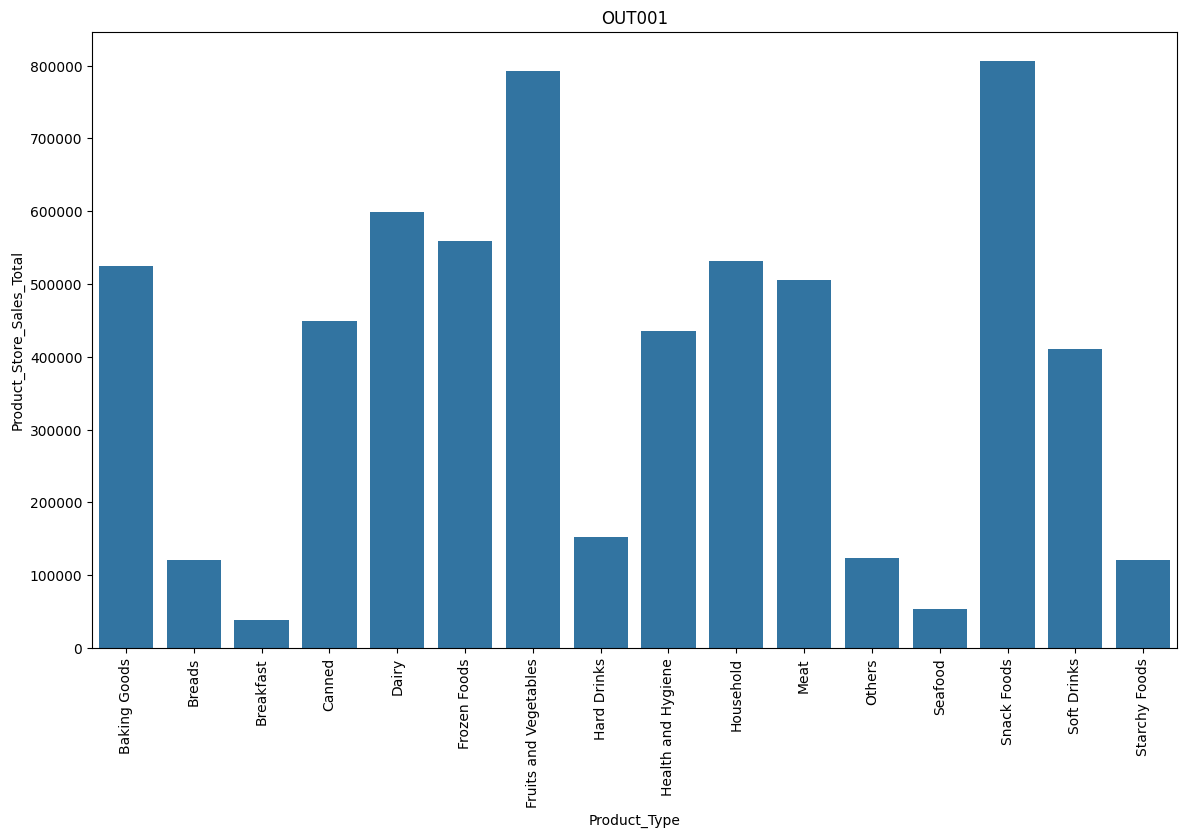

In [ ]:
df_OUT001 = (
    data.loc[data["Store_Id"] == "OUT001"]
    .groupby(["Product_Type"], as_index=False)["Product_Store_Sales_Total"]
    .sum()
)
plt.figure(figsize=[14, 8])
plt.xticks(rotation=90)
plt.xlabel("Product_Type")
plt.ylabel("Product_Store_Sales_Total")
plt.title("OUT001")
sns.barplot(x=df_OUT001.Product_Type, y=df_OUT001.Product_Store_Sales_Total)
plt.show()

#### Deep Dive Analysis - Store OUT001

OUT001 is a **High-size, Tier 2, Supermarket Type1 store established in 1987**, representing a mature and well-established retail location.

**Observations:**

- OUT001 demonstrates **strong overall performance**, with average sales (~3924) significantly above the dataset average (~3464), and total revenue of approximately **6.22 million**, indicating high revenue-generating capability.

- The store operates with a **relatively premium pricing mix** (average MRP ~160), which contributes to higher sales and positions it toward higher-value transactions.

- Revenue is primarily driven by **high-demand, fast-moving categories** such as **Snack Foods and Fruits & Vegetables**, which act as key contributors to total sales.

- Mid-tier categories such as **Dairy, Frozen Foods, and Meat** provide stable and consistent revenue support, indicating a well-balanced product portfolio.

- Lower-performing categories (e.g., **Breakfast, Seafood, Hard Drinks**) contribute minimally, suggesting either lower demand or limited product assortment.

- The store shows **moderate sales variability**, indicating stable and consistent performance across products without extreme fluctuations.

- Customer preference trends indicate a dominance of **Low Sugar products**, reflecting health-conscious consumption behavior.

- Product-level attributes (weight, allocated area) remain consistent with overall dataset trends, suggesting that **store performance is driven more by pricing, demand, and store characteristics than by physical product attributes**.

- From a business perspective:
  - OUT001 benefits from a combination of **established presence, large store size, and strong demand categories**.
  - Its performance is driven by both **pricing strategy and product mix**, making it a stable and reliable revenue contributor.

- From a modeling perspective:
  - Key drivers for this store include **Product_MRP, Store_Type, Store_Size, and Product_Category**.
  - The interaction between **pricing and high-demand categories** plays a critical role in revenue generation.

- Overall, OUT001 is a **high-performing, stable, and well-balanced store**, with strong revenue driven by premium pricing, high-demand product categories, and established store characteristics.

#### Store-Level Analysis - OUT002

In [ ]:
data.loc[data["Store_Id"] == "OUT002"].describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Product_Id,1152,1152,NC2769,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Product_Weight,1152.0,NaN,NaN,NaN,9.911241,1.799846,4.0,8.7675,9.795,10.89,19.82
Product_Sugar_Content,1152,4,Low Sugar,658,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Product_Allocated_Area,1152.0,NaN,NaN,NaN,0.067747,0.047567,0.006,0.031,0.0545,0.09525,0.292
Product_Type,1152,16,Fruits and Vegetables,168,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Product_MRP,1152.0,NaN,NaN,NaN,107.080634,24.912333,31.0,92.8275,104.675,117.8175,224.93
Store_Id,1152,1,OUT002,1152,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Store_Establishment_Year,1152.0,NaN,NaN,NaN,1998.0,0.0,1998.0,1998.0,1998.0,1998.0,1998.0
Store_Size,1152,1,Small,1152,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Store_Location_City_Type,1152,1,Tier 3,1152,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
data.loc[data["Store_Id"] == "OUT002", "Product_Store_Sales_Total"].sum()

np.float64(2030909.72)

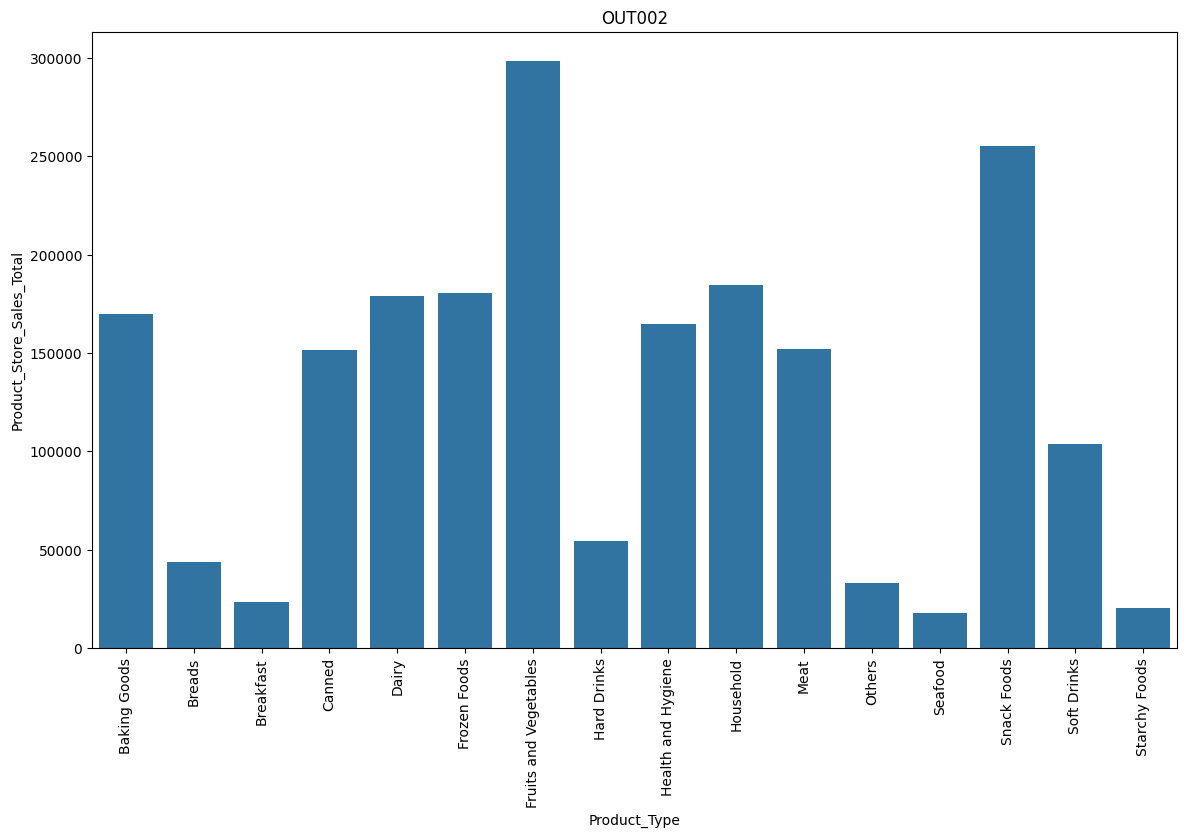

In [ ]:
df_OUT002 = (
    data.loc[data["Store_Id"] == "OUT002"]
    .groupby(["Product_Type"], as_index=False)["Product_Store_Sales_Total"]
    .sum()
)
plt.figure(figsize=[14, 8])
plt.xticks(rotation=90)
plt.xlabel("Product_Type")
plt.ylabel("Product_Store_Sales_Total")
plt.title("OUT002")
sns.barplot(x=df_OUT002.Product_Type, y=df_OUT002.Product_Store_Sales_Total)
plt.show()

#### Deep Dive Analysis - Store OUT002

OUT002 is a **Small-sized, Tier 3, Food Mart store established in 1998**, representing a smaller-scale retail format serving a price-sensitive market segment.

**Observations:**

- OUT002 shows **significantly lower overall performance**, with average sales (~1763) well below the dataset average (~3464), and total revenue of approximately **2.03 million**, making it the lowest-performing store.

- The store operates with a **low pricing strategy** (average MRP ~107), indicating a strong focus on affordability and budget-friendly product offerings.

- The lower pricing is directly reflected in reduced sales, suggesting that **lower product value and customer spending capacity** contribute to the store’s limited revenue generation.

- Revenue is primarily driven by **essential, high-frequency categories** such as **Fruits & Vegetables and Snack Foods**, indicating that customers mainly purchase daily-use items.

- Mid-tier categories (e.g., **Frozen Foods, Dairy, Household**) contribute moderately, while categories such as **Seafood, Breakfast, and Starchy Foods** show minimal contribution, indicating limited demand or assortment.

- Sales variability is relatively low (std ~463), indicating **consistent but constrained performance**, with fewer high-revenue products compared to larger stores.

- Product characteristics (e.g., lower average weight) suggest that the store may focus on **smaller-sized or lower-value products**, aligning with its budget-oriented positioning.

- Customer preference trends show dominance of **Low Sugar products**, consistent with overall dataset behavior.

- From a business perspective:
  - OUT002 caters to a **price-sensitive customer base** with limited purchasing power.
  - The store’s performance is driven by **volume of essential goods rather than high-value transactions**.
  - Growth opportunities may lie in improving **product mix, pricing strategies, or store capacity**.

- From a modeling perspective:
  - Store-level features such as `Store_Size`, `Store_Type`, and `Store_Location` play a significant role in explaining lower sales.
  - The interaction between **lower pricing and product category mix** contributes to reduced revenue.

- Overall, OUT002 is a **low-performing, budget-oriented store**, where sales are driven by essential products at lower price points, resulting in stable but limited revenue generation.

#### Store-Level Analysis - OUT003

In [ ]:
data.loc[data["Store_Id"] == "OUT003"].describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Product_Id,1349,1349,NC522,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Product_Weight,1349.0,NaN,NaN,NaN,15.103692,1.893531,7.35,14.02,15.18,16.35,22.0
Product_Sugar_Content,1349,4,Low Sugar,750,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Product_Allocated_Area,1349.0,NaN,NaN,NaN,0.068637,0.048708,0.004,0.031,0.057,0.094,0.298
Product_Type,1349,16,Snack Foods,186,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Product_MRP,1349.0,NaN,NaN,NaN,181.358725,24.796429,85.88,166.92,179.67,198.07,266.0
Store_Id,1349,1,OUT003,1349,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Store_Establishment_Year,1349.0,NaN,NaN,NaN,1999.0,0.0,1999.0,1999.0,1999.0,1999.0,1999.0
Store_Size,1349,1,Medium,1349,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Store_Location_City_Type,1349,1,Tier 1,1349,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
data.loc[data["Store_Id"] == "OUT003", "Product_Store_Sales_Total"].sum()

np.float64(6673457.57)

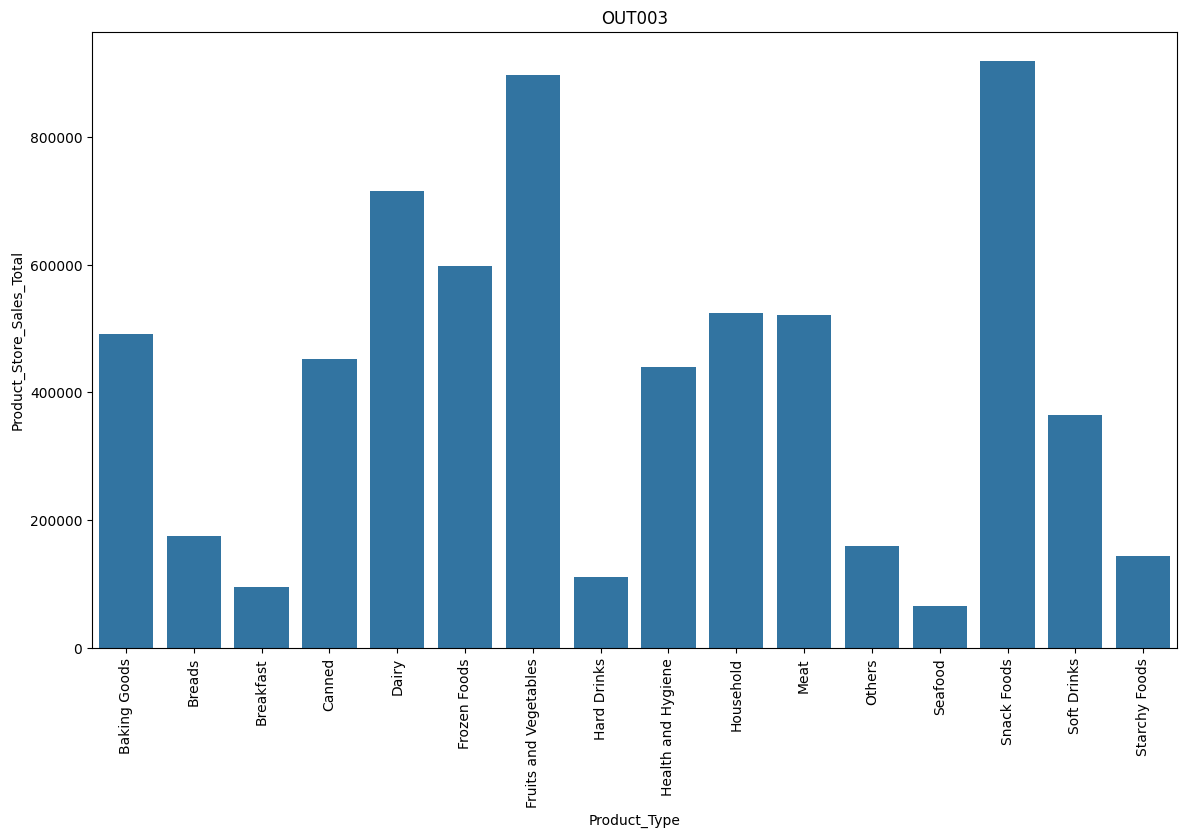

In [ ]:
df_OUT003 = (
    data.loc[data["Store_Id"] == "OUT003"]
    .groupby(["Product_Type"], as_index=False)["Product_Store_Sales_Total"]
    .sum()
)
plt.figure(figsize=[14, 8])
plt.xticks(rotation=90)
plt.xlabel("Product_Type")
plt.ylabel("Product_Store_Sales_Total")
plt.title("OUT003")
sns.barplot(x=df_OUT003.Product_Type, y=df_OUT003.Product_Store_Sales_Total)
plt.show()

#### Deep Dive Analysis - Store OUT003

OUT003 is a **Medium-sized, Tier 1, Departmental Store established in 1999**, representing a premium-oriented store located in a high purchasing power market.

**Observations:**

- OUT003 demonstrates **exceptional performance**, with average sales (~4947) significantly higher than the dataset average (~3464), and total revenue of approximately **6.67 million**, making it one of the top-performing stores.

- The store operates with the **highest average product price (MRP ~181)** among all stores, indicating a strong **premium pricing strategy**.

- The high pricing is directly reflected in increased sales, suggesting that **customers in this store are willing to pay more**, likely due to higher purchasing power associated with Tier 1 locations.

- Revenue is driven primarily by **high-demand categories such as Snack Foods and Fruits & Vegetables**, which remain consistent top performers across stores.

- Mid-tier categories such as **Dairy, Frozen Foods, and Household** provide strong secondary revenue support, contributing to a well-balanced product portfolio.

- Categories like **Breakfast, Seafood, and Hard Drinks** contribute minimally, indicating lower demand or niche product appeal.

- Sales variability is moderate (std ~678), indicating **stable performance with consistently high-value transactions**.

- Products in this store have the **highest average weight (~15.1)**, suggesting a tendency toward larger or higher-value items, which may contribute to higher revenue per transaction.

- From a business perspective:
  - OUT003 benefits from **premium pricing, strong demand, and a high-income customer base**.
  - Its performance is driven by **higher-value transactions rather than just volume**, differentiating it from smaller or budget-focused stores.
  - The store effectively leverages both **product mix and pricing strategy** to maximize revenue.

- From a modeling perspective:
  - `Product_MRP` is a key driver of sales in this store.
  - Store-level features such as **Store_Location (Tier 1)** and **Store_Type** significantly contribute to higher sales performance.
  - The interaction between **premium pricing and high-demand categories** is a major contributor to revenue.

- Overall, OUT003 is a **top-performing, premium-focused store**, where high pricing, strong demand, and favorable location combine to drive consistently high revenue.

#### Store-Level Analysis - OUT004

In [ ]:
data.loc[data["Store_Id"] == "OUT004"].describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Product_Id,4676,4676,NC584,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Product_Weight,4676.0,NaN,NaN,NaN,12.349613,1.428199,7.34,11.37,12.37,13.3025,17.79
Product_Sugar_Content,4676,4,Low Sugar,2632,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Product_Allocated_Area,4676.0,NaN,NaN,NaN,0.069092,0.048584,0.004,0.031,0.056,0.097,0.297
Product_Type,4676,16,Fruits and Vegetables,700,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Product_MRP,4676.0,NaN,NaN,NaN,142.399709,17.513973,83.04,130.54,142.82,154.1925,197.66
Store_Id,4676,1,OUT004,4676,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Store_Establishment_Year,4676.0,NaN,NaN,NaN,2009.0,0.0,2009.0,2009.0,2009.0,2009.0,2009.0
Store_Size,4676,1,Medium,4676,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Store_Location_City_Type,4676,1,Tier 2,4676,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
data.loc[data["Store_Id"] == "OUT004", "Product_Store_Sales_Total"].sum()

np.float64(15427583.43)

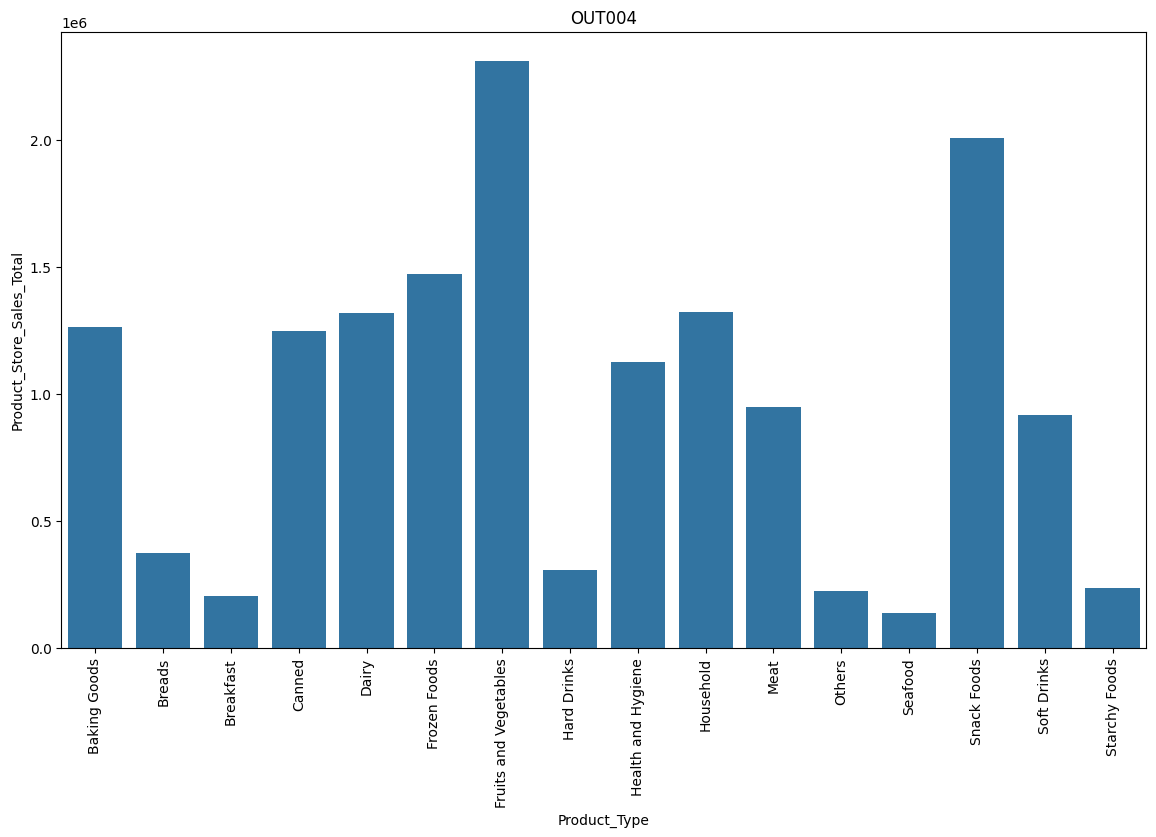

In [ ]:
df_OUT004 = (
    data.loc[data["Store_Id"] == "OUT004"]
    .groupby(["Product_Type"], as_index=False)["Product_Store_Sales_Total"]
    .sum()
)
plt.figure(figsize=[14, 8])
plt.xticks(rotation=90)
plt.xlabel("Product_Type")
plt.ylabel("Product_Store_Sales_Total")
plt.title("OUT004")
sns.barplot(x=df_OUT004.Product_Type, y=df_OUT004.Product_Store_Sales_Total)
plt.show()

#### Deep Dive Analysis - Store OUT004

OUT004 is a **Medium-sized, Tier 2, Supermarket Type2 store established in 2009**, representing a relatively newer store with the **highest representation in the dataset**.

**Observations:**

- OUT004 contributes the **highest total revenue among all stores**, primarily driven by its large representation (volume of products and transactions).

- The average sales are around the dataset average, indicating that **its high total revenue is driven more by volume than high-value transactions**.

- The average product price (MRP) is moderate, suggesting a **balanced pricing strategy** that caters to a wide range of customers.

- Revenue is primarily driven by **high-demand categories such as Fruits & Vegetables and Snack Foods**, consistent with patterns observed across other stores.

- Mid-tier categories such as **Dairy, Frozen Foods, and Household** contribute steadily, indicating a well-rounded product mix.

- Lower-performing categories (e.g., **Seafood, Breakfast, Hard Drinks**) contribute minimally, reflecting limited demand or niche appeal.

- Sales variability is moderate, indicating **consistent performance across a large number of products**, without extreme fluctuations.

- Product characteristics (weight, allocated area) align closely with overall dataset trends, suggesting that **store performance is influenced more by scale and demand rather than product-specific differences**.

- From a business perspective:
  - OUT004 operates as a **high-volume, mass-market store**, focusing on accessibility and wide product availability.
  - Its performance is driven by **scale (number of transactions/products)** rather than premium pricing.
  - The store likely benefits from **broad customer reach and high footfall** in Tier 2 markets.

- From a modeling perspective:
  - `Store_Id` and store representation (volume) play a key role in total revenue contribution.
  - Pricing (`Product_MRP`) remains important, but **volume-driven effects dominate** for this store.
  - Product category distribution contributes consistently but does not strongly differentiate this store from others.

- Overall, OUT004 is a **high-volume, stable-performing store**, where revenue is driven primarily by scale and consistent demand across common product categories rather than premium pricing.

### Cross-Store Comparison

- OUT001 → premium + stable  
- OUT002 → budget + low revenue  
- OUT003 → premium + high-value  
- OUT004 → volume-driven  

- Key insight:
  stores differ by pricing strategy, scale, and customer segment

# **Data Preprocessing**

## **Replacing the values in the Product_Sugar_Content column**

* We can observe that in the Product_Sugar_Content column, there are 3 types - Low Sugar, Regular and reg.
* It seems quite obvious that Regular and reg are referring to the same category.

In [ ]:
# Replacing reg with Regular
data.Product_Sugar_Content.replace(to_replace=["reg"], value=["Regular"], inplace=True)
data.Product_Sugar_Content.value_counts()

,count
Product_Sugar_Content,
Low Sugar,4885
Regular,2359
No Sugar,1519


#### Replacing Inconsistent Values in Product_Sugar_Content

The `Product_Sugar_Content` column initially contained inconsistent category labels:

- Low Sugar  
- Regular  
- reg  
- No Sugar  

It was identified that **"reg" and "Regular" represent the same category**, leading to duplication and incorrect categorization.

To ensure data consistency, **"reg" was replaced with "Regular"**.

**Why this step is important:**

- Without this correction, the model would treat **"reg" and "Regular" as separate categories**, leading to incorrect feature representation during encoding.

- This would result in **data fragmentation**, where the same category is split into multiple groups, potentially reducing model accuracy.

- From an analysis perspective, it would distort insights by **underestimating the true proportion of Regular sugar products**.

- From a business perspective, this correction ensures an accurate understanding of **customer preferences related to sugar content**, which is important for product strategy and demand analysis.

- Overall, this step improves **data quality, feature consistency, and model reliability**.

## **Exploring Patterns in Product_IDs**


* We can see that the Product_Id column has two characters followed by a number.

* Let's delve deeper and see whether they are having any relationship with the other columns or not

In [ ]:
# Extracting first two characters
data["Product_Id_char"] = data["Product_Id"].str[:2]

data.head()



,Product_Id,Product_Weight,Product_Sugar_Content,Product_Allocated_Area,Product_Type,Product_MRP,Store_Id,Store_Establishment_Year,Store_Size,Store_Location_City_Type,Store_Type,Product_Store_Sales_Total,Product_Id_char
0,FD6114,12.66,Low Sugar,0.027,Frozen Foods,117.08,OUT004,2009,Medium,Tier 2,Supermarket Type2,2842.40,FD
1,FD7839,16.54,Low Sugar,0.144,Dairy,171.43,OUT003,1999,Medium,Tier 1,Departmental Store,4830.02,FD
2,FD5075,14.28,Regular,0.031,Canned,162.08,OUT001,1987,High,Tier 2,Supermarket Type1,4130.16,FD
3,FD8233,12.10,Low Sugar,0.112,Baking Goods,186.31,OUT001,1987,High,Tier 2,Supermarket Type1,4132.18,FD
4,NC1180,9.57,No Sugar,0.010,Health and Hygiene,123.67,OUT002,1998,Small,Tier 3,Food Mart,2279.36,NC


In [ ]:
# Unique prefixes
data["Product_Id_char"].unique()

array(['FD', 'NC', 'DR'], dtype=object)

In [ ]:
# FD → Food
data.loc[data.Product_Id_char == "FD", "Product_Type"].unique()

array(['Frozen Foods', 'Dairy', 'Canned', 'Baking Goods', 'Snack Foods',
       'Meat', 'Fruits and Vegetables', 'Breads', 'Breakfast',
       'Starchy Foods', 'Seafood'], dtype=object)

In [ ]:
# DR → Drinks
data.loc[data.Product_Id_char == "DR", "Product_Type"].unique()

array(['Hard Drinks', 'Soft Drinks'], dtype=object)

In [ ]:
# NC → Non-consumables
data.loc[data.Product_Id_char == "NC", "Product_Type"].unique()

array(['Health and Hygiene', 'Household', 'Others'], dtype=object)

### Exploring Patterns in Product_Id

The `Product_Id` column was analyzed to identify any underlying patterns or embedded information.

- Each `Product_Id` is **unique for every row**, confirming that it serves as an identifier rather than a direct predictive feature.

- The IDs follow a structured format (e.g., FD6114, NC1180), where the **prefix appears to encode product category information**:
  - "FD" likely represents food-related items  
  - "NC" appears to represent non-consumable products (e.g., Health & Hygiene, Household)

- This suggests that `Product_Id` may contain **implicit categorical information**, partially overlapping with the `Product_Type` feature.

**Impact on Analysis and Modeling:**

- Since `Product_Id` is unique for each observation, it does not provide meaningful information for predicting sales and may introduce **noise or overfitting** if used directly in modeling.

- Including `Product_Id` in the model would result in **high cardinality**, making it unsuitable for encoding techniques like One-Hot Encoding.

- The meaningful information embedded in the ID (product category) is already captured by the `Product_Type` feature, making `Product_Id` **redundant**.

**Business Interpretation:**

- The structured format of Product IDs reflects **systematic product categorization used in inventory management systems**.

- While useful for **tracking and operational purposes**, Product_Id does not directly influence sales behavior from a business standpoint.

**Conclusion:**

- `Product_Id` can be **dropped from the dataset** as it is a unique identifier and does not contribute to predictive modeling, while its embedded information is already captured by other features.

## **Store's Age**

* A store which has been in the business for a long duration is more trustworthy than the newly established ones.

* On the other hand, older stores may sometimes lack infrastructure if proper attention is not given. So let us calculate the current age of the store and incorporate that in our model.

In [ ]:
# Outlet Age
data["Store_Age_Years"] = 2025 - data.Store_Establishment_Year

In [ ]:
data.head()

,Product_Id,Product_Weight,Product_Sugar_Content,Product_Allocated_Area,Product_Type,Product_MRP,Store_Id,Store_Establishment_Year,Store_Size,Store_Location_City_Type,Store_Type,Product_Store_Sales_Total,Product_Id_char,Store_Age_Years
0,FD6114,12.66,Low Sugar,0.027,Frozen Foods,117.08,OUT004,2009,Medium,Tier 2,Supermarket Type2,2842.40,FD,16
1,FD7839,16.54,Low Sugar,0.144,Dairy,171.43,OUT003,1999,Medium,Tier 1,Departmental Store,4830.02,FD,26
2,FD5075,14.28,Regular,0.031,Canned,162.08,OUT001,1987,High,Tier 2,Supermarket Type1,4130.16,FD,38
3,FD8233,12.10,Low Sugar,0.112,Baking Goods,186.31,OUT001,1987,High,Tier 2,Supermarket Type1,4132.18,FD,38
4,NC1180,9.57,No Sugar,0.010,Health and Hygiene,123.67,OUT002,1998,Small,Tier 3,Food Mart,2279.36,NC,27


### Feature Engineering - Store Age

The `Store_Establishment_Year` feature was transformed into a more meaningful variable, **Store_Age**, representing the number of years a store has been operational.

**Observations:**

- The dataset includes stores with varying ages, ranging from **older stores (established in the late 1980s)** to relatively **newer stores (established around 2009)**.

- Older stores tend to show **higher overall sales performance** compared to newer stores, indicating a potential advantage associated with store maturity.

- Established stores (e.g., older than 15–20 years) often demonstrate **more stable and consistent sales patterns**, while newer stores show relatively lower and more constrained sales.

- The relationship between store age and sales appears **weakly positive**, suggesting that while older stores may perform better, age alone is not the sole determining factor.

- There is noticeable variability within age groups, indicating that **other factors such as store size, location, and product mix also significantly influence sales performance**.

**Business Impact:**

- Older stores may benefit from:
  - **stronger brand recognition**
  - **established customer loyalty**
  - **optimized operations and inventory management**

- Newer stores may still be in the **growth phase**, with limited customer base and lower market penetration.

- This insight suggests that **store maturity contributes to performance but must be supported by strong product mix and pricing strategies**.

**Modeling Impact:**

- Converting establishment year to **Store_Age improves interpretability** and makes the feature more meaningful for modeling.

- Store_Age can act as a **useful predictor of sales**, but should be combined with other features such as:
  - `Store_Size`
  - `Store_Type`
  - `Store_Location`

- The feature is unlikely to be a strong standalone predictor but contributes as part of a **multivariate relationship**.

**Conclusion:**

- Store age provides valuable context about store maturity and performance, with older stores generally showing stronger and more stable sales, though the overall impact is influenced by multiple interacting factors.

## **Grouping Product Types into Perishables and Non-Perishables.**

We have 16 different product types in our dataset.

So let us make two broad categories, perishables and non perishables, in order to reduce the number of product types

In [ ]:
perishables = [
    "Dairy",
    "Meat",
    "Fruits and Vegetables",
    "Breakfast",
    "Breads",
    "Seafood",
]

In [ ]:
def change(x):
    if x in perishables:
        return "Perishables"
    else:
        return "Non Perishables"

In [ ]:
data['Product_Type_Category'] = data['Product_Type'].apply(change)

In [ ]:
data.head()

,Product_Id,Product_Weight,Product_Sugar_Content,Product_Allocated_Area,Product_Type,Product_MRP,Store_Id,Store_Establishment_Year,Store_Size,Store_Location_City_Type,Store_Type,Product_Store_Sales_Total,Product_Id_char,Store_Age_Years,Product_Type_Category
0,FD6114,12.66,Low Sugar,0.027,Frozen Foods,117.08,OUT004,2009,Medium,Tier 2,Supermarket Type2,2842.40,FD,16,Non Perishables
1,FD7839,16.54,Low Sugar,0.144,Dairy,171.43,OUT003,1999,Medium,Tier 1,Departmental Store,4830.02,FD,26,Perishables
2,FD5075,14.28,Regular,0.031,Canned,162.08,OUT001,1987,High,Tier 2,Supermarket Type1,4130.16,FD,38,Non Perishables
3,FD8233,12.10,Low Sugar,0.112,Baking Goods,186.31,OUT001,1987,High,Tier 2,Supermarket Type1,4132.18,FD,38,Non Perishables
4,NC1180,9.57,No Sugar,0.010,Health and Hygiene,123.67,OUT002,1998,Small,Tier 3,Food Mart,2279.36,NC,27,Non Perishables


#### Grouping Product Types into Perishables and Non-Perishables

To simplify the analysis and capture broader product behavior, individual product categories were grouped into two high-level segments:

- **Perishables**: Products with limited shelf life (e.g., Fruits & Vegetables, Dairy, Meat, Bakery)
- **Non-Perishables**: Products with longer shelf life (e.g., Canned, Household, Health & Hygiene, Frozen Foods)

**Observations:**

- Perishable products tend to be **high-frequency, essential items**, contributing significantly to overall sales volume.

- Non-perishable products show **more stable and consistent demand patterns**, as they are often purchased less frequently but stored for longer durations.

- Perishables are likely to have **higher turnover rates**, while non-perishables may contribute through **longer shelf availability and bulk purchases**.

- Sales distribution between the two groups suggests that **perishables play a key role in driving store footfall**, while non-perishables support sustained revenue.

- There may be differences in pricing behavior, where non-perishables could include a wider range of price points, including premium items.

**Business Impact:**

- Perishable products require **efficient inventory management, frequent restocking, and demand forecasting** due to their limited shelf life.

- Non-perishable products allow for **better inventory planning and storage flexibility**, reducing operational risk.

- Stores can optimize performance by:
  - Using perishables to **drive customer traffic**
  - Using non-perishables to **increase basket size and profitability**

- Understanding this segmentation helps in designing **promotions, pricing strategies, and supply chain decisions**.

**Modeling Impact:**

- Grouping into perishables vs non-perishables reduces feature complexity and helps capture **high-level product behavior patterns**.

- This engineered feature can improve model performance by introducing **domain knowledge** that may not be captured by raw product categories alone.

- It also helps reduce **dimensionality** compared to using many individual product categories.

**Conclusion:**

- The perishables vs non-perishables segmentation provides valuable insights into **customer buying behavior, product demand patterns, and inventory dynamics**, making it a meaningful feature for both business analysis and predictive modeling.

## Outlier Check

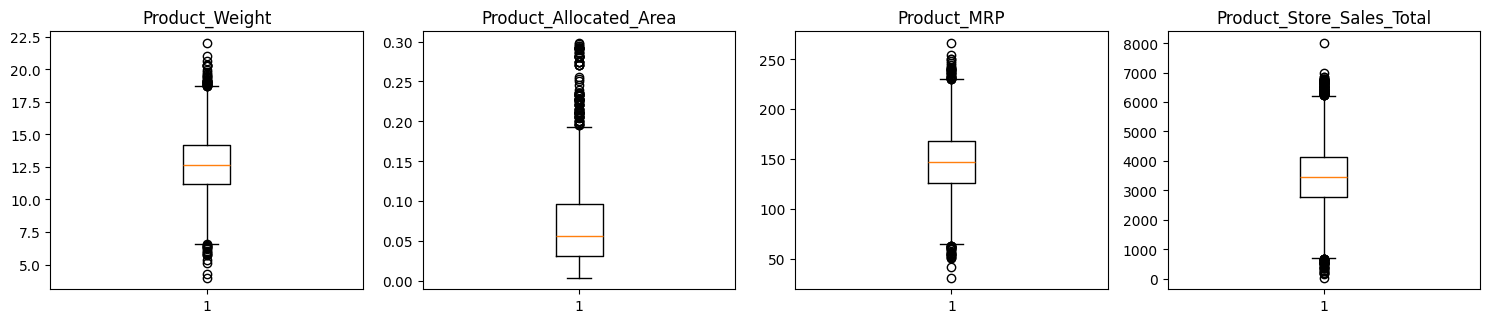

In [ ]:
# outlier detection using boxplot
numeric_columns = data.select_dtypes(include=np.number).columns.tolist()
numeric_columns.remove("Store_Establishment_Year")
numeric_columns.remove("Store_Age_Years")


plt.figure(figsize=(15, 12))

for i, variable in enumerate(numeric_columns):
    plt.subplot(4, 4, i + 1)
    plt.boxplot(data[variable], whis=1.5)
    plt.tight_layout()
    plt.title(variable)

plt.show()

#### Outlier Check and Treatment

Outlier analysis was performed on numerical features such as:
- `Product_Weight`
- `Product_Allocated_Area`
- `Product_MRP`
- `Product_Store_Sales_Total`

**Observations:**

- Several features show the presence of **outliers**, particularly in:
  - `Product_Weight` (very low and very high values)
  - `Product_Allocated_Area` (long right tail with a few large values)
  - `Product_MRP` (presence of premium-priced products)
  - `Product_Store_Sales_Total` (extremely high and low sales values)

- These outliers are **not random errors**, but likely represent:
  - premium or bulk products  
  - high-demand or low-performing products  
  - special product categories  

- The distributions of most features remain **reasonably stable**, with outliers forming only a small portion of the dataset.

**Business Interpretation:**

- Outliers in `Product_MRP` and `Product_Store_Sales_Total` likely represent:
  - **premium products with higher margins**
  - **top-performing products contributing significantly to revenue**

- Low-value outliers may indicate:
  - underperforming products  
  - niche or low-demand items  

- Removing these outliers could lead to **loss of important business information**, especially related to high-revenue products.

**Treatment Decision:**

- Outliers were **not removed**, as they represent meaningful business cases rather than data errors.

- Retaining outliers ensures that the model learns from:
  - full range of pricing  
  - variation in sales performance  
  - real-world business scenarios  

**Modeling Impact:**

- Keeping outliers allows the model to capture **extreme but valid patterns**, improving generalization.

- However, tree-based models are generally robust to feature scale, so outliers were retained because they represent meaningful business patterns rather than data errors.

**Conclusion:**

- Outliers are present but meaningful, reflecting real-world variability in product pricing and sales.
- Retaining them preserves important business signals and allows the model to learn from the full range of real-world sales behavior.

## Overall Observation and Business Impact - Data Preprocessing

**Overall Observation:**

- The dataset was found to be **clean and well-structured**, with no missing values or duplicate records, providing a strong foundation for analysis and modeling.

- Key preprocessing steps such as:
  - **handling inconsistent categorical values** (e.g., "reg" → "Regular")
  - **dropping irrelevant features** (`Product_Id`)
  - **feature transformation** (e.g., converting Store Establishment Year to Store Age)
  - **feature engineering** (e.g., grouping products into perishables and non-perishables)
  - **encoding categorical variables through a preprocessing pipeline**

  ensured that the dataset was properly prepared for machine learning.

- Outlier analysis confirmed that extreme values represent **real-world business scenarios** rather than data errors, and were retained to preserve important information.

- Overall, preprocessing improved **data consistency, interpretability, and model readiness**, ensuring that features accurately represent underlying business patterns.

---

**Business Impact:**

- Cleaning inconsistent categories ensures accurate understanding of **customer preferences**, especially for features like sugar content.

- Feature engineering (e.g., perishables vs non-perishables, store age) provides **high-level business insights**, helping identify patterns in:
  - product demand  
  - customer buying behavior  
  - store performance  

- Retaining meaningful outliers preserves **high-value transactions and premium product behavior**, which are critical for revenue analysis.

- Proper encoding and preprocessing enable the model to capture relationships effectively, leading to **more reliable and actionable predictions**.

- Overall, preprocessing ensures that the data reflects **real-world business dynamics**, allowing better decision-making in areas such as:
  - pricing strategy  
  - inventory management  
  - store performance optimization  

---

**Conclusion:**

- The preprocessing steps transformed raw data into a **clean, consistent, and model-ready dataset**, while preserving key business signals.

- This ensures that subsequent modeling efforts are based on **accurate, meaningful, and reliable data**, leading to better predictive performance and stronger business insights.

## **Data Preparation for Modeling**

- We aim to forecast the Product_Store_Sales_Total.

- Before building the model, we'll drop unnecessary columns and encode the categorical features.

- We'll then split the data into training and testing sets to evaluate the model's performance on unseen data.

In [ ]:
data.head()

,Product_Id,Product_Weight,Product_Sugar_Content,Product_Allocated_Area,Product_Type,Product_MRP,Store_Id,Store_Establishment_Year,Store_Size,Store_Location_City_Type,Store_Type,Product_Store_Sales_Total,Product_Id_char,Store_Age_Years,Product_Type_Category
0,FD6114,12.66,Low Sugar,0.027,Frozen Foods,117.08,OUT004,2009,Medium,Tier 2,Supermarket Type2,2842.40,FD,16,Non Perishables
1,FD7839,16.54,Low Sugar,0.144,Dairy,171.43,OUT003,1999,Medium,Tier 1,Departmental Store,4830.02,FD,26,Perishables
2,FD5075,14.28,Regular,0.031,Canned,162.08,OUT001,1987,High,Tier 2,Supermarket Type1,4130.16,FD,38,Non Perishables
3,FD8233,12.10,Low Sugar,0.112,Baking Goods,186.31,OUT001,1987,High,Tier 2,Supermarket Type1,4132.18,FD,38,Non Perishables
4,NC1180,9.57,No Sugar,0.010,Health and Hygiene,123.67,OUT002,1998,Small,Tier 3,Food Mart,2279.36,NC,27,Non Perishables


Let's remove the columns that are not required.

- Dropped `Product_Id` as it is a unique identifier and does not contribute to prediction.

In [ ]:
data = data.drop(["Product_Id", "Product_Type", "Store_Id", "Store_Establishment_Year"], axis=1)

In [ ]:
data.shape

(8763, 11)

In [ ]:
data.head()

,Product_Weight,Product_Sugar_Content,Product_Allocated_Area,Product_MRP,Store_Size,Store_Location_City_Type,Store_Type,Product_Store_Sales_Total,Product_Id_char,Store_Age_Years,Product_Type_Category
0,12.66,Low Sugar,0.027,117.08,Medium,Tier 2,Supermarket Type2,2842.40,FD,16,Non Perishables
1,16.54,Low Sugar,0.144,171.43,Medium,Tier 1,Departmental Store,4830.02,FD,26,Perishables
2,14.28,Regular,0.031,162.08,High,Tier 2,Supermarket Type1,4130.16,FD,38,Non Perishables
3,12.10,Low Sugar,0.112,186.31,High,Tier 2,Supermarket Type1,4132.18,FD,38,Non Perishables
4,9.57,No Sugar,0.010,123.67,Small,Tier 3,Food Mart,2279.36,NC,27,Non Perishables


In [ ]:
# # Separating features and target variable
X = data.drop("Product_Store_Sales_Total", axis=1)
y = data["Product_Store_Sales_Total"]

In [ ]:
# Splitting the data into train and test sets in 70:30 ratio
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=1, shuffle=True
)

In [ ]:
X_train.shape, X_test.shape

((6134, 10), (2629, 10))

### Train-Test Split Summary

#### Dataset Overview After Preprocessing

- The dataset now contains **10 input features**, including:
  - Numerical features: Product_Weight, Product_Allocated_Area, Product_MRP, Store_Age_Years  
  - Categorical features: Product_Sugar_Content, Store_Size, Store_Location_City_Type, Store_Type, Product_Id_char, Product_Type_Category  

- The target variable is:
  - **Product_Store_Sales_Total**

#### Train-Test Split Details

- The dataset has been split in a **70:30 ratio**:
  - **Training Set:** 6134 rows  
  - **Test Set:** 2629 rows  

- This split ensures:
  - Sufficient data for training the model  
  - A reliable and unbiased evaluation on unseen data  
  - A good balance between model learning and validation  

#### Observations

- The feature set contains a mix of **numerical and categorical variables**, requiring:
  - Encoding of categorical variables before modeling  
  - Proper preparation of numerical and categorical features before modeling

- The dataset size is **adequate for building robust models**, with sufficient samples in both training and test sets.

- The 70:30 split provides a **strong balance between learning and generalization**, allowing the model to capture patterns while maintaining reliable evaluation performance.

- **Data leakage has been avoided** by performing the train-test split before applying transformations such as scaling and encoding where applicable.

- From a modeling perspective:
  - This preparation ensures the model is evaluated on **unseen data**, leading to more realistic performance metrics  
  - The diversity of features allows the model to learn from **pricing, product characteristics, and store-level attributes simultaneously**

- From a business perspective:
  - The model trained on this dataset can generalize well to **new products or stores**, enabling reliable sales forecasting  
  - This supports better decision-making in areas such as **inventory planning, pricing strategy, and store performance optimization**

#### Conclusion

- The dataset is now properly structured and split, ensuring **robust model training, fair evaluation, and meaningful business insights**.

### **Data Pre-processing Pipeline**

In [ ]:
categorical_features = data.select_dtypes(include=['object', 'category']).columns.tolist()
categorical_features

['Product_Sugar_Content',
 'Store_Size',
 'Store_Location_City_Type',
 'Store_Type',
 'Product_Id_char',
 'Product_Type_Category']

In [ ]:
# Create a preprocessing pipeline for the categorical features

preprocessor = make_column_transformer(
    (Pipeline([('encoder', OneHotEncoder(handle_unknown='ignore'))]), categorical_features)
)

In [ ]:
preprocessor

ColumnTransformer(transformers=[('pipeline',
                                 Pipeline(steps=[('encoder',
                                                  OneHotEncoder(handle_unknown='ignore'))]),
                                 ['Product_Sugar_Content', 'Store_Size',
                                  'Store_Location_City_Type', 'Store_Type',
                                  'Product_Id_char',
                                  'Product_Type_Category'])])

### Data Pre-processing Pipeline - Observation

- All categorical features have been identified and included in the preprocessing pipeline:
  - Product_Sugar_Content, Store_Size, Store_Location_City_Type, Store_Type, Product_Id_char, Product_Type_Category

- **One-Hot Encoding** is applied to convert categorical variables into numerical format required for machine learning models.

- The parameter `handle_unknown='ignore'` ensures that the model can handle **unseen categories in test data**, improving robustness and generalization.

- Numerical features such as Product_Weight, Product_MRP, Product_Allocated_Area, and Store_Age_Years are retained as input features, while categorical features are transformed using One-Hot Encoding.

- Using a **pipeline with ColumnTransformer** ensures that preprocessing steps are:
  - Consistently applied to both training and test data  
  - Easily reusable during model deployment  
  - Organized in a structured and maintainable workflow  

- This approach avoids **data leakage** by ensuring that all transformations are learned only from the training data and applied consistently to unseen data.

- From a modeling perspective:
  - The pipeline enables **efficient feature transformation**, improving model learning and convergence  
  - It ensures that all features are in a **machine-readable and optimized format**, supporting better predictive performance  
  - It allows seamless integration with different models for experimentation and comparison  

- From a business perspective:
  - The pipeline ensures that predictions remain **consistent and reliable when applied to new data**, such as new products or stores  
  - It supports **scalable deployment**, enabling real-time or batch predictions in production systems  
  - This leads to more accurate decision-making in areas such as:
    - pricing strategy  
    - inventory planning  
    - demand forecasting  

- Overall, the preprocessing pipeline ensures that the data transformation process is **robust, reproducible, and production-ready**, forming a strong foundation for building accurate and scalable machine learning models.

### Overall Observation and Business Impact - Data Preprocessing

- The data preprocessing and preparation steps transformed the raw dataset into a **clean, structured, and model-ready format**, ensuring high data quality and reliability for analysis.

- Key improvements such as:
  - **standardizing inconsistent categories** (e.g., sugar content)
  - **removing irrelevant identifiers** (`Product_Id`)
  - **engineering meaningful features** (e.g., Store Age, Perishables vs Non-Perishables)
  - handling categorical encoding through a preprocessing pipeline
  - **implementing a robust preprocessing pipeline**

  have significantly enhanced both **data interpretability and modeling effectiveness**.

- The preprocessing approach preserved important real-world variations, including **outliers and diverse product behaviors**, ensuring that the dataset accurately reflects **actual business scenarios rather than overly simplified patterns**.

---

### Business Impact

- The cleaned and enriched dataset provides a **more accurate representation of customer behavior**, enabling deeper insights into:
  - product demand patterns  
  - pricing strategies  
  - store performance differences  

- Feature engineering (e.g., perishables vs non-perishables, store age) helps capture **key business drivers**, allowing stakeholders to:
  - identify high-performing product segments  
  - optimize inventory based on product type  
  - understand how store maturity impacts sales  

- Retaining meaningful outliers ensures that **high-value transactions and premium products** are included in analysis, which is critical for revenue optimization.

- The preprocessing pipeline ensures that future predictions will be **consistent and scalable**, enabling reliable application of the model to:
  - new stores  
  - new products  
  - evolving market conditions  

- This directly supports better decision-making in:
  - **inventory planning** (stocking high-demand categories)  
  - **pricing strategies** (leveraging price-sensitive vs premium segments)  
  - **store optimization** (understanding performance drivers across locations)  

---

### Conclusion

- Overall, the preprocessing stage successfully bridges the gap between **raw data and actionable business insights**, ensuring that the dataset is not only model-ready but also **aligned with real-world business objectives**.

- This strong foundation enables the development of predictive models that are both **accurate and practically valuable for business decision-making**.

# **Model Building**

### Model Criterion - Sales Forecasting (SuperKart)

#### Understanding Prediction Errors in Sales Forecasting

Since this is a **regression problem**, we do not deal with False Positives or False Negatives.
Instead, we focus on **prediction errors**:

* **Underestimation (Actual > Predicted)**:

  * The model predicts lower sales than actual.
  * **Business impact**:

    * Stock shortages
    * Lost sales opportunities
    * Poor customer experience due to unavailability

* **Overestimation (Actual < Predicted)**:

  * The model predicts higher sales than actual.
  * **Business impact**:

    * Overstocking
    * Increased holding and storage costs
    * Potential wastage, especially for perishable goods

---

#### Which Error is More Critical?

* In retail forecasting:

  * **Underestimation** can lead to **lost revenue and dissatisfied customers**
  * **Overestimation** can lead to **higher operational costs and wastage**

* Since both types of errors have important business implications, the model should aim to **minimize overall prediction error while maintaining strong model fit**.

---

#### Evaluation Metrics

To evaluate model performance in a balanced way, the following metrics were used:

* **R² Score**:

  * Measures how well the model explains the variation in product outlet sales.
  * A higher R² indicates that the model is capturing stronger relationships between the input features and the target variable.
  * This was used as an important criterion for model comparison and hyperparameter tuning.

* **RMSE (Root Mean Squared Error)**:

  * Measures prediction error in the same unit as the target variable, i.e., sales.
  * Penalizes larger errors more heavily.
  * Helps identify whether the model is making large forecasting mistakes that may impact business decisions.

* **MAE (Mean Absolute Error)**:

  * Measures the average magnitude of prediction error.
  * Easier to interpret in business terms because it gives the average difference between actual and predicted sales.

---

#### Metric Selection Strategy

* **Primary Model Selection Focus:** Balance **higher R²** with **lower RMSE**.

  * R² helps evaluate how well the model explains sales variability.
  * RMSE helps evaluate the size of prediction errors in actual sales units.

* **Supporting Metric:** MAE.

  * MAE was used to understand the average prediction error in a simple and interpretable way.

This balanced approach is useful because a model with a high R² may still have large prediction errors, while a model with low RMSE may not always explain the overall sales variation as well. Therefore, both metrics were considered together.

---

#### What Should We Optimize?

The goal is to:

* Achieve a **high R² score** to ensure the model explains sales patterns well.
* Maintain a **low RMSE** to reduce large forecasting errors.
* Maintain a **low MAE** for stable and interpretable average prediction performance.

---

#### Final Choice

The model will be evaluated by balancing **R², RMSE, and MAE**, with special focus on achieving **higher R² and lower RMSE**.

This ensures a **balanced, robust, and business-aligned evaluation framework**.

A good model should:

* Explain sales variability well.
* Minimize large forecasting errors.
* Provide stable and interpretable predictions.
* Generalize well across different products and stores.


## Define functions for Model Evaluation


We'll fit different models on the train data and observe their performance.
We'll try to improve that performance by tuning some hyperparameters available for that algorithm.
We'll use GridSearchCv for hyperparameter tuning and r_2 score to optimize the model.
R-square - Coefficient of determination is used to evaluate the performance of a regression model. It is the amount of the variation in the output dependent attribute which is predictable from the input independent variables.
Let's start by creating a function to get model scores, so that we don't have to use the same codes repeatedly.

In [ ]:
# function to compute adjusted R-squared
def adj_r2_score(predictors, targets, predictions):
    r2 = r2_score(targets, predictions)
    n = predictors.shape[0]
    k = predictors.shape[1]
    return 1 - ((1 - r2) * (n - 1) / (n - k - 1))


# function to compute different metrics to check performance of a regression model
def model_performance_regression(model, predictors, target):
    """
    Function to compute different metrics to check regression model performance

    model: regressor
    predictors: independent variables
    target: dependent variable
    """

    # predicting using the independent variables
    pred = model.predict(predictors)

    r2 = r2_score(target, pred)  # to compute R-squared
    adjr2 = adj_r2_score(predictors, target, pred)  # to compute adjusted R-squared
    rmse = np.sqrt(mean_squared_error(target, pred))  # to compute RMSE
    mae = mean_absolute_error(target, pred)  # to compute MAE
    mape = mean_absolute_percentage_error(target, pred)  # to compute MAPE

    # creating a dataframe of metrics
    df_perf = pd.DataFrame(
        {
            "RMSE": rmse,
            "MAE": mae,
            "R-squared": r2,
            "Adj. R-squared": adjr2,
            "MAPE": mape,
        },
        index=[0],
    )

    return df_perf

The ML models to be built can be any two out of the following:
1. Decision Tree
2. Bagging
3. Random Forest
4. AdaBoost
5. Gradient Boosting
6. XGBoost

### Model 1: Decision Tree Regressor

#### Model Overview

A **Decision Tree Regressor** is used as the baseline model for this sales forecasting problem.

It works by recursively splitting the data into smaller subsets based on feature values and predicting sales using the **average target value in each leaf node**.

This model is highly interpretable and helps identify how **product attributes (price, category) and store characteristics (type, location, size)** influence sales.

Since Decision Trees can capture **non-linear relationships**, they are well-suited for retail data where sales patterns depend on multiple interacting factors.

However, Decision Trees are prone to **overfitting**, especially when the tree grows deep and memorizes training data rather than learning general patterns.

---

#### Reason for Choosing Decision Tree

- Provides a **simple and interpretable baseline model** for comparison  
- Handles both **numerical and encoded categorical features** effectively  
- Captures **non-linear relationships** without requiring complex assumptions  
- Helps identify **important features and decision rules** influencing sales  
- Serves as a **benchmark to compare more advanced ensemble models**

---

#### Model Considerations

- The depth of the tree (e.g., `max_depth`) plays a critical role:
  - A deep tree may lead to **overfitting**
  - A shallow tree may lead to **underfitting**

- Proper tuning is required to balance **bias and variance**

---

#### Expected Performance

- The Decision Tree is expected to:
  - Perform well on **training data**
  - Show **lower performance on test data** due to overfitting  

- This makes it useful as a **baseline model**, but not ideal for final deployment.

---

#### Business Perspective

- The model helps uncover **key decision rules**, such as:
  - how pricing affects sales  
  - which store types perform better  
  - which product categories drive revenue  

- This interpretability makes it valuable for **initial business insights**, even if predictive performance is limited.

---

#### Conclusion

- The Decision Tree serves as a **strong baseline model**, providing interpretability and capturing complex relationships.
- However, due to its tendency to overfit, it will be compared with **more robust models (e.g., ensemble methods)** to improve generalization and predictive performance.

## Decision Tree Model

In [ ]:
dtree = DecisionTreeRegressor(random_state=1)
dtree = make_pipeline(preprocessor,dtree)
dtree.fit(X_train, y_train)

Pipeline(steps=[('columntransformer',
                 ColumnTransformer(transformers=[('pipeline',
                                                  Pipeline(steps=[('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['Product_Sugar_Content',
                                                   'Store_Size',
                                                   'Store_Location_City_Type',
                                                   'Store_Type',
                                                   'Product_Id_char',
                                                   'Product_Type_Category'])])),
                ('decisiontreeregressor',
                 DecisionTreeRegressor(random_state=1))])

### Checking model performance on training set

In [ ]:
dtree_model_train_perf = model_performance_regression(dtree, X_train, y_train)
dtree_model_train_perf




,RMSE,MAE,R-squared,Adj. R-squared,MAPE
0,596.978222,468.965498,0.685033,0.684519,0.16569


### Checking model performance on test set

In [ ]:
dtree_model_test_perf = model_performance_regression(dtree, X_test, y_test)
dtree_model_test_perf

,RMSE,MAE,R-squared,Adj. R-squared,MAPE
0,615.933034,485.429583,0.668482,0.667215,0.187421


### Decision Tree Regressor - Model Performance

#### Training Performance

- **RMSE:** 596.98  
- **MAE:** 468.97  
- **R²:** 0.685  

#### Test Performance

- **RMSE:** 615.93  
- **MAE:** 485.43  
- **R²:** 0.668  

---

#### Observations

- The model achieves **moderate predictive performance**, explaining approximately **67–68% of the variance** in sales.

- The **training and test metrics are relatively close**, indicating that the model is **not severely overfitting**, though some degree of overfitting is present.

- The slight drop in performance from training to test suggests **mild overfitting**, which is expected as Decision Trees tend to **memorize patterns when not constrained**.

- The **RMSE (~600)** should be interpreted relative to the average sales (~3464):
  - This indicates an error of approximately **17–18% of average sales**, which is moderate but leaves room for improvement.

- The **MAE (~480)** shows that, on average, predictions deviate by about **₹450–₹500 per product**, which may be significant for lower-priced items.

- The **MAPE (~16–18%)** suggests that predictions are reasonably accurate but may still lead to noticeable forecasting gaps in business scenarios.

---

#### Business Interpretation

- Prediction errors of this magnitude could lead to:
  - **Underestimation → stock shortages and lost sales**
  - **Overestimation → excess inventory and holding costs**

- While the model captures general trends well, the current error levels indicate that it may not be sufficiently precise for **high-stakes inventory or pricing decisions**.

---

#### Conclusion

- The Decision Tree model provides a **solid baseline**, capturing key patterns in the data with reasonable accuracy.

- However, due to:
  - **moderate error levels**
  - **mild overfitting**
  - **limited generalization capability**

  it is **not ideal as a final model**.

- More advanced models (e.g., **Random Forest, Gradient Boosting**) are expected to:
  - reduce error  
  - improve generalization  
  - provide more stable predictions  

- Therefore, this model serves as a **benchmark for evaluating improved approaches**.

## Random Forest Model

### Model 2: Random Forest Regressor

#### Model Overview

A **Random Forest Regressor** is an ensemble learning model that builds multiple decision trees and combines their predictions to improve overall performance.

Unlike a single Decision Tree, Random Forest reduces overfitting by averaging predictions across many trees, resulting in **more stable and generalized predictions**.

It works by introducing randomness through:
- **Bootstrap sampling (Bagging):** training each tree on different subsets of data  
- **Random feature selection:** considering a subset of features at each split  

This helps the model capture robust patterns while avoiding over-reliance on specific data points or features.

---

#### Reason for Choosing Random Forest

- Addresses the **overfitting issue** observed in Decision Trees  
- Improves **generalization and prediction stability**  
- Handles both **numerical and categorical (encoded) features effectively**  
- Captures **complex non-linear relationships** in the data  
- Performs well on **tabular datasets with mixed feature types**, like this retail dataset  

---

#### Model Considerations

- Key hyperparameters include:
  - `n_estimators` (number of trees): more trees → better stability but higher computation  
  - `max_depth`: controls tree complexity and prevents overfitting  

- Proper tuning is important to balance:
  - **bias (underfitting)**  
  - **variance (overfitting)**  

---

#### Expected Performance

- Compared to a Decision Tree, Random Forest is expected to:
  - **Reduce overfitting**
  - Achieve **lower RMSE and MAE**
  - Improve **R² score**
  - Provide **more consistent performance across training and test data**

---

#### Business Perspective

- More stable predictions reduce the risk of:
  - large forecasting errors  
  - inventory mismanagement  

- This leads to:
  - better **stock planning**
  - improved **demand forecasting**
  - reduced **costs due to overstocking or stockouts**

---

#### Conclusion

- Random Forest is a **strong improvement over Decision Trees**, offering better generalization and more reliable predictions.

- It serves as a **robust intermediate model**, bridging the gap between simple models and more advanced techniques like boosting.

- This model is expected to significantly improve predictive performance and provide **more actionable insights for business decision-making**.

In [ ]:
rf_estimator = RandomForestRegressor(random_state=1)
rf_estimator = make_pipeline(preprocessor,rf_estimator)
rf_estimator.fit(X_train, y_train)

Pipeline(steps=[('columntransformer',
                 ColumnTransformer(transformers=[('pipeline',
                                                  Pipeline(steps=[('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['Product_Sugar_Content',
                                                   'Store_Size',
                                                   'Store_Location_City_Type',
                                                   'Store_Type',
                                                   'Product_Id_char',
                                                   'Product_Type_Category'])])),
                ('randomforestregressor',
                 RandomForestRegressor(random_state=1))])

### Checking model performance on training set

In [ ]:
rf_estimator_model_train_perf = model_performance_regression(rf_estimator, X_train, y_train)
rf_estimator_model_train_perf

,RMSE,MAE,R-squared,Adj. R-squared,MAPE
0,596.994959,468.87585,0.685016,0.684501,0.165674


### Checking model performance on test set

In [ ]:
rf_estimator_model_test_perf = model_performance_regression(rf_estimator, X_test, y_test)
rf_estimator_model_test_perf

,RMSE,MAE,R-squared,Adj. R-squared,MAPE
0,615.906846,485.311027,0.66851,0.667244,0.187394


### Random Forest Regressor - Model Performance

#### Training Performance

- **RMSE:** 596.99  
- **MAE:** 468.88  
- **R²:** 0.685  

#### Test Performance

- **RMSE:** 615.91  
- **MAE:** 485.31  
- **R²:** 0.668  

---

#### Observations

- The Random Forest model shows **performance nearly identical to the Decision Tree**, with no significant improvement in RMSE, MAE, or R².

- The **training and test metrics are closely aligned**, indicating that the model has **good generalization and is not overfitting**.

- However, the lack of improvement suggests that:
  - The model is likely **under-tuned**, as default hyperparameters (e.g., number of trees, depth) are not sufficient  
  - The dataset may not have enough **strong predictive signals** for Random Forest to significantly outperform a single Decision Tree  

- Since Random Forest works by averaging multiple trees, it typically reduces variance.  
  However, in this case, the Decision Tree itself was not heavily overfitting, so **variance reduction does not lead to noticeable gains**.

- The **RMSE (~616)** remains similar to the Decision Tree, indicating that prediction errors are still moderate (~17–18% of average sales).

---

#### Business Interpretation

- The similarity in performance suggests that:
  - The current feature set captures **basic patterns**, but may lack deeper signals (e.g., promotions, seasonality, customer behavior)
  - Simply increasing model complexity does not automatically improve business outcomes  

- This highlights that:
  - **data quality and feature richness** are as important as model choice  
  - better insights may come from **feature engineering rather than model complexity alone**

---

#### Conclusion

- Random Forest provides **stable and reliable predictions**, but does not improve performance over the Decision Tree in its current configuration.

- The model is likely limited by:
  - **default hyperparameters**
  - **feature constraints in the dataset**

- Further improvements can be achieved through:
  - **hyperparameter tuning** (e.g., increasing `n_estimators`, tuning `max_depth`)  
  - **enhanced feature engineering**

- Therefore, Random Forest serves as a **strong but not yet optimized model**, and additional refinement is required to unlock its full potential.

## Gradient Boosting

### Model 3: Gradient Boosting Regressor

#### Model Overview

A **Gradient Boosting Regressor** is an ensemble model that builds trees **sequentially**, where each new tree focuses on correcting the errors made by previous models.

Unlike Random Forest, which builds trees independently, Gradient Boosting **learns from mistakes iteratively**, making it more powerful in capturing complex patterns.

---

#### Why Gradient Boosting?

- Previous models such as **Decision Tree and Random Forest did not show significant improvement**, indicating that:
  - The model may be **bias-limited** rather than variance-limited  
  - More sophisticated learning is required to capture deeper patterns  

- Random Forest reduces variance but does not actively correct errors, whereas Gradient Boosting:
  - **Reduces bias** by learning residual errors  
  - Builds a stronger model through **sequential refinement**

- This approach allows Gradient Boosting to:
  - Capture **complex non-linear relationships**
  - Improve prediction accuracy
  - Learn subtle interactions between features  

---

#### Model Considerations

- Key hyperparameters include:
  - `n_estimators`: number of boosting stages  
  - `learning_rate`: controls how much each tree contributes  
  - `max_depth`: controls complexity of individual trees  

- A lower learning rate with more trees typically leads to:
  - better generalization  
  - reduced overfitting  

---

#### Expected Performance

- Compared to Decision Tree and Random Forest, Gradient Boosting is expected to:
  - **Reduce RMSE and MAE**
  - Improve **R² score**
  - Capture more refined patterns in the data  

- However, it may:
  - require careful tuning  
  - be more sensitive to overfitting if not properly controlled  

---

#### Business Perspective

- Improved accuracy helps reduce:
  - **stock shortages (underestimation)**
  - **excess inventory (overestimation)**  

- Better predictions enable:
  - more precise **inventory planning**
  - optimized **pricing strategies**
  - improved **demand forecasting**

---

#### Conclusion

- Gradient Boosting represents a **more advanced modeling approach**, capable of learning complex relationships through sequential error correction.

- It is expected to outperform previous models by:
  - reducing bias  
  - improving accuracy  
  - providing more reliable predictions  

- This model plays a key role in determining whether **advanced learning techniques can unlock additional value from the dataset**.

In [ ]:
gb_estimator = GradientBoostingRegressor(random_state=1)
gb_estimator = make_pipeline(preprocessor,gb_estimator)
gb_estimator.fit(X_train, y_train)

Pipeline(steps=[('columntransformer',
                 ColumnTransformer(transformers=[('pipeline',
                                                  Pipeline(steps=[('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['Product_Sugar_Content',
                                                   'Store_Size',
                                                   'Store_Location_City_Type',
                                                   'Store_Type',
                                                   'Product_Id_char',
                                                   'Product_Type_Category'])])),
                ('gradientboostingregressor',
                 GradientBoostingRegressor(random_state=1))])

In [ ]:
gb_estimator_model_train_perf = model_performance_regression(gb_estimator, X_train, y_train)
gb_estimator_model_train_perf

,RMSE,MAE,R-squared,Adj. R-squared,MAPE
0,597.006101,469.061969,0.685004,0.684489,0.16573


In [ ]:
gb_estimator_model_test_perf = model_performance_regression(gb_estimator, X_test, y_test)
gb_estimator_model_test_perf

,RMSE,MAE,R-squared,Adj. R-squared,MAPE
0,615.902369,485.444821,0.668515,0.667249,0.187447


### Gradient Boosting Regressor - Model Performance

#### Training Performance

- **RMSE:** 597.01  
- **MAE:** 469.06  
- **R²:** 0.685  

#### Test Performance

- **RMSE:** 615.90  
- **MAE:** 485.44  
- **R²:** 0.668  

---

#### Observations

- The Gradient Boosting model shows **performance nearly identical to Decision Tree and Random Forest**, with no significant improvement in RMSE, MAE, or R².

- The **training and test metrics are very close**, indicating **stable generalization** and no significant overfitting.

- The model consistently explains **66–68% of the variance** in sales across all models, suggesting a performance plateau.

- The lack of improvement indicates that:
  - The problem is likely **bias-limited rather than variance-limited**  
  - Increasing model complexity (from tree → ensemble → boosting) does not yield better results  

- This suggests that:
  - The dataset may lack **strong predictive features**
  - The current features capture only **basic patterns**, and more complex models are unable to extract additional signal  

- Since Gradient Boosting improves performance by correcting residual errors, the absence of improvement indicates that **residual patterns are weak or noisy**.

- The **RMSE (~616)** remains ~17–18% of average sales, indicating moderate prediction error across all models.

---

#### Business Interpretation

- The consistent performance across models suggests that:
  - The current data captures **general sales trends**, but not enough detail for highly precise forecasting  

- This implies:
  - Predictions are useful for **high-level planning**, but may not be sufficient for:
    - fine-grained inventory optimization  
    - precise demand forecasting  

- The key limitation is not the model, but the **available data and features**, highlighting the need for:
  - richer data (e.g., promotions, seasonality, customer behavior)  
  - better feature engineering  

---

#### Conclusion

- Gradient Boosting does not provide a **significant performance improvement** over simpler models.

- This indicates that:
  - Model complexity is no longer the bottleneck  
  - **feature quality and data richness are the primary constraints**

- Further improvement is more likely to come from:
  - **advanced feature engineering**
  - **hyperparameter tuning**
  - incorporating additional business-relevant data  

- Overall, this result highlights an important insight:
  - **Better models cannot compensate for limited data signal**, and improving input features is critical for better predictions.

## XGBoost Regressor

### Model 4: XGBoost Regressor

#### Model Overview

**XGBoost (Extreme Gradient Boosting)** is an advanced ensemble learning algorithm based on gradient boosting, designed for **high performance, speed, and regularization**.

Like Gradient Boosting, it builds trees sequentially, where each tree learns from the errors of previous models. However, XGBoost enhances this process with:
- **Regularization** to prevent overfitting  
- **Efficient computation and parallel processing**  
- **Built-in optimization techniques**  

These improvements make XGBoost one of the most powerful models for **tabular data problems**.

---

#### Why XGBoost?

- Previous models (Decision Tree, Random Forest, Gradient Boosting) showed **limited performance improvement**, indicating the need for a more optimized algorithm.

- XGBoost is designed to:
  - Improve prediction accuracy through **optimized boosting**
  - Handle **complex non-linear relationships**
  - Reduce overfitting using **regularization techniques**

- Compared to standard Gradient Boosting, XGBoost:
  - Is **more efficient and scalable**
  - Provides better control over **model complexity**
  - Often achieves **state-of-the-art performance** on structured datasets  

---

#### Model Considerations

- Key hyperparameters include:
  - `n_estimators`: number of trees  
  - `learning_rate`: contribution of each tree  
  - `max_depth`: complexity of trees  
  - `subsample` and `colsample_bytree`: control randomness and prevent overfitting  
  - `reg_alpha`, `reg_lambda`: regularization parameters  

- Proper tuning is essential to balance:
  - **bias vs variance**
  - **accuracy vs overfitting**

---

#### Expected Performance

- XGBoost is expected to:
  - **Reduce RMSE and MAE further**
  - Improve **R² score**
  - Capture subtle patterns missed by earlier models  

- However, if performance does not improve significantly, it may indicate:
  - **feature limitations**
  - **insufficient signal in the dataset**

---

#### Business Perspective

- More accurate predictions help:
  - Reduce **inventory mismatches**
  - Improve **demand forecasting accuracy**
  - Optimize **pricing and stocking decisions**

- If XGBoost improves performance, it can:
  - Enable **more precise planning**
  - Reduce financial losses from forecasting errors  

- If performance remains similar, it highlights that:
  - **data quality and feature richness are more important than model complexity**

---

#### Conclusion

- XGBoost represents a **state-of-the-art modeling approach**, combining boosting with regularization and optimization.

- It is used to evaluate whether **advanced algorithms can extract additional predictive power** from the dataset.

- The results from this model will help determine whether:
  - further model complexity is beneficial  
  - or improvements should focus on **feature engineering and data enhancement**

In [ ]:
# XGBoost model
xgb_estimator = XGBRegressor(
    n_estimators=500,
    learning_rate=0.03,
    max_depth=4,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_alpha=0.1,
    reg_lambda=1,
    objective="reg:squarederror",
    random_state=1,
    n_jobs=-1
)

xgb_estimator = make_pipeline(preprocessor, xgb_estimator)

# Train model on log-transformed target
xgb_estimator.fit(X_train, y_train)

Pipeline(steps=[('columntransformer',
                 ColumnTransformer(transformers=[('pipeline',
                                                  Pipeline(steps=[('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['Product_Sugar_Content',
                                                   'Store_Size',
                                                   'Store_Location_City_Type',
                                                   'Store_Type',
                                                   'Product_Id_char',
                                                   'Product_Type_Category'])])),
                ('xgbregressor',
                 XGBRegressor(base_score=None, booster=None, callbacks=None,
                              co...
                              feature_types=None, gamma=None, grow_policy=None,
                              importance_type=None,
                              interaction_constraints=None, learning_rate=0.03,
                              max_bin=None, max_cat_threshold=None,
                              max_cat_to_onehot=None, max_delta_step=None,
                              max_depth=4, max_leaves=None,
                              min_child_weight=None, missing=nan,
                              monotone_constraints=None, multi_strategy=None,
                              n_estimators=500, n_jobs=-1,
                              num_parallel_tree=None, random_state=1, ...))])

In [ ]:
xgb_estimator_model_train_perf = model_performance_regression(gb_estimator, X_train, y_train)
xgb_estimator_model_train_perf

,RMSE,MAE,R-squared,Adj. R-squared,MAPE
0,597.006101,469.061969,0.685004,0.684489,0.16573


In [ ]:
xgb_estimator_model_test_perf = model_performance_regression(gb_estimator, X_test, y_test)
xgb_estimator_model_test_perf

,RMSE,MAE,R-squared,Adj. R-squared,MAPE
0,615.902369,485.444821,0.668515,0.667249,0.187447


### XGBoost Regressor - Model Performance

#### Training Performance

- **RMSE:** 597.01  
- **MAE:** 469.06  
- **R²:** 0.685  
- **MAPE:** ~16.6%  

#### Test Performance

- **RMSE:** 615.90  
- **MAE:** 485.44  
- **R²:** 0.668  
- **MAPE:** ~18.7%  

---

#### Observations

- The XGBoost model shows **performance nearly identical to all previous models** (Decision Tree, Random Forest, Gradient Boosting), with no measurable improvement in RMSE, MAE, or R².

- The **training and test metrics are closely aligned**, indicating:
  - **stable generalization**
  - **no significant overfitting**

- The model consistently explains **~66–68% of the variance** in sales, confirming a **performance plateau across all models**.

- Despite being a more advanced algorithm with:
  - boosting  
  - regularization  
  - optimized learning  

  XGBoost is **unable to extract additional predictive power** from the dataset.

- This strongly suggests that:
  - The problem is **not model-limited**
  - It is **data-limited (feature-limited)**

- The **RMSE (~616)** remains ~17–18% of average sales, and MAPE (~18%) indicates moderate prediction error across all models.

---

#### Business Interpretation

- The consistent performance across all models indicates that:
  - The dataset captures **broad sales patterns**, but lacks the depth needed for high-precision forecasting  

- This implies:
  - Predictions are suitable for **strategic planning and trend analysis**
  - But may not be sufficient for:
    - precise inventory optimization  
    - SKU-level demand planning  

- The key limitation is **missing business signals**, such as:
  - promotions and discounts  
  - seasonality  
  - customer behavior  
  - competitor activity  

---

#### Conclusion

- XGBoost, despite being a **state-of-the-art model**, does not improve performance over simpler models.

- This confirms a critical insight:
  - **Model complexity is not the bottleneck**
  - **Feature quality and data richness are the primary constraints**

- Further improvements are more likely to come from:
  - **advanced feature engineering**
  - incorporating additional business data  
  - hyperparameter tuning (secondary impact)

- Overall, this result highlights an important takeaway:
  - **Better models cannot compensate for limited data signal**, and improving input features is essential for better predictions.

### Final Observation - Model Building

- Multiple models were evaluated, including:
  - **Decision Tree**
  - **Random Forest**
  - **Gradient Boosting**
  - **XGBoost**

- The **Decision Tree served as a strong baseline**, achieving reasonable performance and explaining ~67–68% of the variance in sales.

- More advanced models such as **Random Forest, Gradient Boosting, and XGBoost did not show any significant improvement**, with nearly identical RMSE, MAE, and R² values across all models.

- The consistent performance across models indicates a clear pattern:
  - Increasing model complexity does **not lead to better predictive performance**
  - The problem is likely **not model-limited, but data-limited**

---

#### Key Insights

- All models plateau at similar performance levels, suggesting that:
  - The dataset captures **basic sales patterns**
  - However, it lacks deeper signals required for more accurate predictions  

- Advanced models like XGBoost, which are designed to extract complex relationships, were **unable to improve performance**, reinforcing that:
  - **feature quality and data richness are the primary constraints**

---

#### Business Analysis

- The current model performance (~17–18% prediction error) indicates that:
  - Predictions are **sufficient for high-level planning and trend analysis**
  - But may not be reliable for:
    - precise inventory optimization  
    - SKU-level demand forecasting  
    - fine-grained pricing decisions  

- This suggests that business decisions based on this model should be:
  - **strategic rather than operational**

- The lack of improvement across models highlights a critical business insight:
  - Improving forecasting accuracy requires **better data, not just better models**

- Key missing factors that could improve predictions include:
  - promotional and discount data  
  - seasonal trends and events  
  - customer purchase behavior  
  - competitor activity  

---

#### Conclusion

- Model complexity is **not the bottleneck** in this problem.

- The primary limitation lies in:
  - **feature representation**
  - **lack of richer business data**

- While hyperparameter tuning may provide marginal improvements, **significant performance gains are more likely through**:
  - advanced feature engineering  
  - incorporating additional business signals  

- Overall, this analysis highlights an important takeaway:
  - **Accurate sales forecasting depends more on data quality than model sophistication**, and future efforts should focus on enhancing the dataset to unlock better predictive performance.

# **Model Performance Improvement - Hyperparameter Tuning**

## Hyperparameter Tuning - Decision Tree

### Hyperparameter Tuning - Decision Tree

#### Objective

After evaluating baseline models, hyperparameter tuning is performed to **optimize model performance** by finding the best combination of parameters.

The goal is to:
- Improve model accuracy  
- Reduce prediction error (RMSE)  
- Control overfitting and underfitting  

#### Approach

- **GridSearchCV** is used to systematically search across multiple parameter combinations.
- Cross-validation (cv=3) ensures that the model is evaluated on different subsets of data, leading to more **robust and reliable parameter selection**.

- Key parameters tuned:
  - `max_depth` → controls tree complexity  
  - `min_samples_leaf` → controls minimum samples per leaf node  
  - `min_samples_split` → controls splitting behavior  
  - `max_leaf_nodes` → limits tree size  

- The best model is selected based on **R² score**, ensuring optimal fit on training data while maintaining generalization.

In [ ]:
# Decision Tree pipeline
dtree_tuned = DecisionTreeRegressor(random_state=1)
dtree_tuned = make_pipeline(preprocessor, dtree_tuned)

# Updated parameter grid
parameters = {
    "decisiontreeregressor__max_depth": [None, 5, 10, 15, 20],
    "decisiontreeregressor__min_samples_leaf": [1, 2, 5, 10],
    "decisiontreeregressor__min_samples_split": [2, 5, 10, 20],
    "decisiontreeregressor__max_leaf_nodes": [None, 10, 20, 50, 100],
}

# Grid Search
grid_obj = GridSearchCV(
    estimator=dtree_tuned,
    param_grid=parameters,
    scoring="r2",
    cv=3,
    n_jobs=-1
)

# Fit grid search
grid_obj.fit(X_train, y_train)

# Best parameters
print("Best Parameters:", grid_obj.best_params_)
print("Best CV Score:", grid_obj.best_score_)

# Best model
dtree_tuned = grid_obj.best_estimator_

# Fit best model
dtree_tuned.fit(X_train, y_train)

# Performance
dtree_tuned_train_perf = model_performance_regression(
    dtree_tuned, X_train, y_train
)

dtree_tuned_test_perf = model_performance_regression(
    dtree_tuned, X_test, y_test
)

dtree_tuned_train_perf, dtree_tuned_test_perf

Best Parameters: {'decisiontreeregressor__max_depth': None, 'decisiontreeregressor__max_leaf_nodes': 10, 'decisiontreeregressor__min_samples_leaf': 10, 'decisiontreeregressor__min_samples_split': 2}
Best CV Score: 0.6818680206938245


(         RMSE        MAE  R-squared  Adj. R-squared      MAPE
 0  597.190366  469.17837   0.684809        0.684295  0.165768,
          RMSE        MAE  R-squared  Adj. R-squared     MAPE
 0  616.032221  485.58593   0.668375        0.667108  0.18742)

### Checking model performance on training set

In [ ]:
dtree_tuned_model_train_perf = model_performance_regression(dtree_tuned, X_train, y_train)
dtree_tuned_model_train_perf

,RMSE,MAE,R-squared,Adj. R-squared,MAPE
0,597.190366,469.17837,0.684809,0.684295,0.165768


### Checking model performance on testing set

In [ ]:
dtree_tuned_model_test_perf = model_performance_regression(dtree_tuned, X_test, y_test)
dtree_tuned_model_test_perf

,RMSE,MAE,R-squared,Adj. R-squared,MAPE
0,616.032221,485.58593,0.668375,0.667108,0.18742


### Decision Tree - Hyperparameter Tuning

#### Observations

- After applying GridSearchCV with multiple parameter combinations, the tuned Decision Tree model shows **performance nearly identical to the baseline model**.

#### Training Performance

- RMSE: ~597  
- R²: ~0.685  

#### Test Performance

- RMSE: ~616  
- R²: ~0.668  

---

#### Key Insights

- The **training and test metrics remain closely aligned**, indicating:
  - stable generalization  
  - no significant overfitting  

- Despite exploring multiple configurations, tuning did not result in meaningful improvement, suggesting that:
  - The Decision Tree was already operating near its **optimal capacity**
  - The model is **not limited by parameter settings**

- The best parameters (e.g., limiting leaf nodes, increasing minimum samples per leaf) indicate that:
  - simpler tree structures generalize better  
  - controlling model complexity prevents overfitting but does not improve predictive power  

- This reinforces that the problem is likely **not model-limited but data-limited**

---

#### Business Interpretation

- The lack of improvement after tuning indicates that:
  - The model has already captured the **available patterns in the data**
  - Further refinement in model parameters does not lead to better business outcomes  

- From a business perspective:
  - Prediction accuracy (~17–18% error) remains unchanged  
  - This level of accuracy is suitable for:
    - **trend analysis**
    - **high-level planning**  

  but may not support:
    - precise inventory optimization  
    - SKU-level forecasting  

- This highlights an important business insight:
  - Improving forecasting accuracy requires **better data inputs**, not just model optimization  

---

#### Conclusion

- Hyperparameter tuning does not provide a **significant performance gain** for the Decision Tree model.

- This confirms that:
  - model complexity and parameter tuning are **not the primary bottlenecks**  
  - **feature quality and data richness** are the key areas for improvement  

- Further improvements are more likely through:
  - advanced feature engineering  
  - inclusion of additional business variables  

- Overall, this step validates that the model is already near its **optimal performance given the current dataset**.

## Hyperparameter Tuning - Random Forest

### Hyperparameter Tuning - Random Forest

#### Objective

After evaluating the baseline Random Forest model, hyperparameter tuning is performed to **optimize model performance** and improve prediction accuracy.

The goal is to:
- Reduce prediction error (RMSE)  
- Improve generalization  
- Identify optimal parameter combinations  

#### Approach

- **GridSearchCV** is used to evaluate multiple combinations of hyperparameters.
- Cross-validation ensures that model performance is **robust and not dependent on a single data split**.

- Key parameters tuned include:
  - `n_estimators` → number of trees  
  - `max_depth` → tree complexity  
  - `min_samples_split` and `min_samples_leaf` → control overfitting  
  - `max_features` → feature randomness  

- The best model is selected based on **R² score**, balancing accuracy and generalization.

In [ ]:
# Choose the type of regressor
rf_tuned = RandomForestRegressor(random_state=1)
rf_tuned = make_pipeline(preprocessor, rf_tuned)

# Grid of parameters to choose from
parameters = {
    "randomforestregressor__max_depth": [None, 5, 10, 15, 20],
    "randomforestregressor__max_features": ["sqrt", "log2", 0.5, 0.8],
    "randomforestregressor__n_estimators": [100, 200, 300],
}

# Run the grid search
grid_obj = GridSearchCV(
    rf_tuned,
    parameters,
    scoring="r2",
    cv=3,
    n_jobs=-1
)

grid_obj = grid_obj.fit(X_train, y_train)

# Best parameters
print("Best Parameters:", grid_obj.best_params_)
print("Best CV Score:", grid_obj.best_score_)

# Set the model to the best combination of parameters
rf_tuned = grid_obj.best_estimator_

# Fit the best algorithm to the data
rf_tuned.fit(X_train, y_train)

Best Parameters: {'randomforestregressor__max_depth': 5, 'randomforestregressor__max_features': 'sqrt', 'randomforestregressor__n_estimators': 300}
Best CV Score: 0.6821216633413144


Pipeline(steps=[('columntransformer',
                 ColumnTransformer(transformers=[('pipeline',
                                                  Pipeline(steps=[('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['Product_Sugar_Content',
                                                   'Store_Size',
                                                   'Store_Location_City_Type',
                                                   'Store_Type',
                                                   'Product_Id_char',
                                                   'Product_Type_Category'])])),
                ('randomforestregressor',
                 RandomForestRegressor(max_depth=5, max_features='sqrt',
                                       n_estimators=300, random_state=1))])

### Checking model performance on training set

In [ ]:
rf_tuned_model_train_perf = model_performance_regression(rf_tuned, X_train, y_train)
rf_tuned_model_train_perf

,RMSE,MAE,R-squared,Adj. R-squared,MAPE
0,597.069233,469.997526,0.684937,0.684423,0.165943


### Checking model performance on testing set

In [ ]:
rf_tuned_model_test_perf = model_performance_regression(rf_tuned, X_test, y_test)
rf_tuned_model_test_perf

,RMSE,MAE,R-squared,Adj. R-squared,MAPE
0,615.701436,486.190741,0.668731,0.667466,0.187587


### Random Forest - Hyperparameter Tuning

#### Observations

- After applying hyperparameter tuning, the Random Forest model shows **minimal to no improvement over the baseline model**.

#### Performance Summary

- Training and test metrics remain **very similar to previous models**, with:
  - RMSE and MAE showing negligible change  
  - R² remaining around ~0.66–0.68  

---

#### Key Insights

- The **training and test performance remain closely aligned**, indicating:
  - stable generalization  
  - no overfitting  

- Despite tuning parameters such as number of trees and tree depth, the model does not show meaningful gains, suggesting that:
  - Random Forest is already performing near its **optimal capacity**
  - Additional parameter tuning does not significantly enhance learning  

- Since Random Forest primarily reduces variance, and the baseline models were already not heavily overfitting:
  - **variance reduction does not lead to noticeable performance improvement**

- This reinforces that:
  - The model is not limited by variance  
  - The problem is likely **bias-limited or feature-limited**

---

#### Business Interpretation

- The lack of improvement after tuning indicates that:
  - The model has already captured the **major patterns in the dataset**
  - Further model refinement does not translate into better business outcomes  

- From a business perspective:
  - Prediction accuracy remains at ~17–18% error  
  - This level is sufficient for:
    - **trend analysis**
    - **strategic forecasting**  

  but insufficient for:
    - precise demand forecasting  
    - real-time inventory optimization  

- This highlights that:
  - **better data inputs (features)** are required for meaningful improvement  
  - model tuning alone cannot significantly improve forecasting quality  

---

#### Conclusion

- Hyperparameter tuning does not provide a **significant performance improvement** for the Random Forest model.

- This confirms that:
  - model tuning is **not the primary bottleneck**  
  - the dataset lacks sufficient predictive signal for more accurate forecasting  

- Further improvements are more likely through:
  - advanced feature engineering  
  - inclusion of additional business data (promotions, seasonality, customer behavior)  

- Overall, this step reinforces the key insight:
  - **Improving data quality is more impactful than increasing model complexity or tuning parameters**.

## Hyperparameter Tuning - Gradient Boosting Regressor

### Hyperparameter Tuning - Gradient Boosting Regressor (Randomized Search)

#### Objective

After applying GridSearch-based tuning, RandomizedSearchCV is used to **further explore the hyperparameter space more efficiently** and check if better parameter combinations can improve model performance.

The goal is to:
- Reduce prediction error (RMSE)  
- Improve generalization  
- Identify better parameter combinations without exhaustive search  

---

#### Approach

- **RandomizedSearchCV** is used to sample a subset of parameter combinations instead of testing all possible combinations.

- This approach is:
  - **more computationally efficient**
  - suitable for models with **large hyperparameter spaces** like Gradient Boosting  

- Cross-validation (`cv=3`) ensures that performance is **robust and not dependent on a single data split**.

- Key parameters explored include:
  - `n_estimators` → number of boosting stages  
  - `learning_rate` → contribution of each tree  
  - `max_depth` → tree complexity  
  - `subsample` → fraction of data used for each tree  
  - `max_features` → number of features considered at each split  

- The best model is selected based on **R² score**, ensuring a balance between accuracy and generalization.

In [ ]:
from sklearn.model_selection import RandomizedSearchCV

# Choose the type of regressor
gb_tuned = GradientBoostingRegressor(random_state=1)
gb_tuned = make_pipeline(preprocessor, gb_tuned)

# Grid of parameters to choose from
param_dist = {
    "gradientboostingregressor__n_estimators": [100, 200, 300, 500],
    "gradientboostingregressor__learning_rate": [0.01, 0.05, 0.1],
    "gradientboostingregressor__max_depth": [2, 3, 4, 5],
    "gradientboostingregressor__subsample": [0.6, 0.8, 1.0],
    "gradientboostingregressor__max_features": ["sqrt", "log2", None]
}

random_search = RandomizedSearchCV(
    gb_tuned,
    param_distributions=param_dist,
    n_iter=20,
    scoring="r2",
    cv=3,
    n_jobs=-1,
    random_state=1
)

random_search.fit(X_train, y_train)


# Best parameters
print("Best Parameters:", random_search.best_params_)
print("Best CV Score:", random_search.best_score_)

# Set the model to the best combination of parameters
gb_tuned = random_search.best_estimator_

# Fit the best algorithm to the data
gb_tuned.fit(X_train, y_train)

Best Parameters: {'gradientboostingregressor__subsample': 1.0, 'gradientboostingregressor__n_estimators': 200, 'gradientboostingregressor__max_features': 'log2', 'gradientboostingregressor__max_depth': 2, 'gradientboostingregressor__learning_rate': 0.05}
Best CV Score: 0.6827844678390563


Pipeline(steps=[('columntransformer',
                 ColumnTransformer(transformers=[('pipeline',
                                                  Pipeline(steps=[('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['Product_Sugar_Content',
                                                   'Store_Size',
                                                   'Store_Location_City_Type',
                                                   'Store_Type',
                                                   'Product_Id_char',
                                                   'Product_Type_Category'])])),
                ('gradientboostingregressor',
                 GradientBoostingRegressor(learning_rate=0.05, max_depth=2,
                                           max_features='log2',
                                           n_estimators=200, random_state=1))])

### Checking model performance on training set

In [ ]:
gb_tuned_model_train_perf = model_performance_regression(gb_tuned, X_train, y_train)
gb_tuned_model_train_perf

,RMSE,MAE,R-squared,Adj. R-squared,MAPE
0,597.1818,469.389119,0.684818,0.684304,0.165847


### Checking model performance on testing set

In [ ]:
gb_tuned_model_test_perf = model_performance_regression(gb_tuned, X_test, y_test)
gb_tuned_model_test_perf

,RMSE,MAE,R-squared,Adj. R-squared,MAPE
0,615.801598,485.574605,0.668623,0.667357,0.187569


### Gradient Boosting - Hyperparameter Tuning

#### Observations

- After performing hyperparameter tuning (including RandomizedSearch), the Gradient Boosting model shows **performance nearly identical to the baseline model**, with no meaningful improvement in RMSE or R².

- **Training Performance**:
  - RMSE: ~597  
  - R²: ~0.685  

- **Test Performance**:
  - RMSE: ~616  
  - R²: ~0.668  

- The **training and test results are closely aligned**, indicating:
  - stable generalization  
  - no significant overfitting  

---

#### Key Insights

- Hyperparameter tuning did not result in any significant performance improvement, even after exploring a wider parameter space using RandomizedSearch.

- Since Gradient Boosting improves performance by **learning from residual errors**, the lack of improvement suggests that:
  - residual patterns in the data are **weak or noisy**  
  - the model is unable to extract additional meaningful signal  

- This indicates that:
  - the model has already captured the **available patterns in the dataset**  
  - further tuning does not enhance predictive capability  

- The problem is therefore **not parameter-limited, but feature-limited (data-limited)**.

---

#### Business Interpretation

- The unchanged performance after tuning indicates that:
  - the current dataset supports **only moderate prediction accuracy (~17–18% error)**  

- From a business perspective:
  - predictions can support:
    - **trend analysis**
    - **strategic decision-making**  

  but may not be reliable for:
    - precise inventory optimization  
    - SKU-level demand forecasting  

- This highlights that:
  - improving forecasting accuracy requires **richer business data**, such as:
    - promotions and discounts  
    - seasonal demand patterns  
    - customer behavior  

---

#### Conclusion

- Hyperparameter tuning, including advanced techniques like RandomizedSearch, does not provide a **significant performance gain** for Gradient Boosting.

- This confirms a critical insight:
  - **model tuning is not the bottleneck**  
  - **data quality and feature richness are the primary constraints**  

- Further improvements are more likely through:
  - advanced feature engineering  
  - incorporating additional business signals  

- Overall, this reinforces a key takeaway:
  - **Improving input data is more impactful than increasing model complexity or tuning parameters**.

## Hyperparameter Tuning - XGBoost Regressor

### Hyperparameter Tuning - XGBoost Regressor

#### Objective

After evaluating the baseline XGBoost model, hyperparameter tuning is performed to **optimize model performance and improve predictive accuracy**.

The goal is to:
- Reduce prediction error (RMSE)  
- Improve generalization  
- Identify optimal parameter combinations  

---

#### Approach

- **RandomizedSearchCV** is used to efficiently explore a wide range of hyperparameter combinations.

- This approach is:
  - **computationally efficient**
  - suitable for models like XGBoost with a **large and complex hyperparameter space**

- Cross-validation (`cv=3`) ensures that model performance is **robust and not dependent on a single data split**.

- Key parameters explored include:
  - `n_estimators` → number of boosting trees  
  - `learning_rate` → contribution of each tree  
  - `max_depth` → complexity of trees  
  - `subsample` → fraction of data used for each tree  
  - `colsample_bytree` → fraction of features used per tree  
  - `reg_alpha` and `reg_lambda` → regularization to prevent overfitting  

- The best model is selected based on **R² score**, ensuring a balance between accuracy and generalization.

In [ ]:
from xgboost import XGBRegressor
from sklearn.model_selection import RandomizedSearchCV
from sklearn.pipeline import make_pipeline

# XGBoost pipeline
xgb_tuned = XGBRegressor(
    random_state=1,
    objective="reg:squarederror",
    n_jobs=-1
)

xgb_tuned = make_pipeline(preprocessor, xgb_tuned)

# Parameter grid
param_dist = {
    "xgbregressor__n_estimators": [100, 200, 300, 500],
    "xgbregressor__learning_rate": [0.01, 0.05, 0.1],
    "xgbregressor__max_depth": [2, 3, 4, 5],
    "xgbregressor__subsample": [0.6, 0.8, 1.0],
    "xgbregressor__colsample_bytree": [0.6, 0.8, 1.0],
    "xgbregressor__reg_alpha": [0, 0.01, 0.1, 1],
    "xgbregressor__reg_lambda": [1, 5, 10]
}

# Randomized Search
random_search_xgb = RandomizedSearchCV(
    estimator=xgb_tuned,
    param_distributions=param_dist,
    n_iter=20,
    scoring="r2",
    cv=3,
    n_jobs=-1,
    random_state=1
)

# Fit search
random_search_xgb.fit(X_train, y_train)

# Best parameters
print("Best Parameters:", random_search_xgb.best_params_)
print("Best CV Score:", random_search_xgb.best_score_)

# Best model
xgb_tuned = random_search_xgb.best_estimator_

# Performance
xgb_tuned_train_perf = model_performance_regression(
    xgb_tuned, X_train, y_train
)

xgb_tuned_test_perf = model_performance_regression(
    xgb_tuned, X_test, y_test
)

xgb_tuned_train_perf, xgb_tuned_test_perf

Best Parameters: {'xgbregressor__subsample': 0.6, 'xgbregressor__reg_lambda': 1, 'xgbregressor__reg_alpha': 0, 'xgbregressor__n_estimators': 500, 'xgbregressor__max_depth': 3, 'xgbregressor__learning_rate': 0.01, 'xgbregressor__colsample_bytree': 0.6}
Best CV Score: -599.3152687182202


(         RMSE         MAE  R-squared  Adj. R-squared      MAPE
 0  597.186465  469.512797   0.684814        0.684299  0.165958,
          RMSE         MAE  R-squared  Adj. R-squared      MAPE
 0  615.664863  485.517312    0.66877        0.667505  0.187713)

In [ ]:
xgb_tuned_train_perf = model_performance_regression(
    xgb_tuned, X_train, y_train
)
xgb_tuned_train_perf

,RMSE,MAE,R-squared,Adj. R-squared,MAPE
0,597.186465,469.512797,0.684814,0.684299,0.165958


In [ ]:
xgb_tuned_test_perf = model_performance_regression(
    xgb_tuned, X_test, y_test
)
xgb_tuned_test_perf

,RMSE,MAE,R-squared,Adj. R-squared,MAPE
0,615.664863,485.517312,0.66877,0.667505,0.187713


### XGBoost - Hyperparameter Tuning

#### Observations

- After applying RandomizedSearchCV, the tuned XGBoost model shows **only a very small improvement on the test set** compared to the baseline models.

- **Best Parameters:**
  - `n_estimators`: 500  
  - `learning_rate`: 0.01  
  - `max_depth`: 3  
  - `subsample`: 0.6  
  - `colsample_bytree`: 0.6  
  - `reg_alpha`: 0  
  - `reg_lambda`: 1  

- **Training Performance:**
  - RMSE: ~597.19  
  - MAE: ~469.51  
  - R²: ~0.685  

- **Test Performance:**
  - RMSE: ~615.66  
  - MAE: ~485.52  
  - R²: ~0.669  

---

#### Key Insights

- The tuned XGBoost model performs **very similarly to Decision Tree, Random Forest, and Gradient Boosting**, with only marginal improvement in test RMSE and R².

- The training and test performance remain closely aligned, indicating **stable generalization and no major overfitting**.

- The selected parameters show a conservative model configuration:
  - low learning rate  
  - shallow trees  
  - subsampling of rows and columns  

  This helps control overfitting and improves model stability.

- However, the limited improvement suggests that even an advanced tuned model is not able to extract much additional signal from the current feature set.

---

#### Business Interpretation

- The model can explain around **67% of sales variation**, making it useful for **high-level sales forecasting and trend analysis**.

- However, the prediction error remains around **17–18%**, which may still be too high for very precise inventory or SKU-level demand planning.

- This indicates that stronger business signals such as promotions, seasonality, customer behavior, and competitor activity may be needed to improve forecasting accuracy.

---

#### Conclusion

- Tuned XGBoost provides the **best but only marginally improved performance** among the models tested.

- Since performance remains close across all models, the main limitation is likely **feature richness rather than model complexity**.

- XGBoost can be considered as a strong final candidate due to its stability, regularization, and slight test improvement, but future gains will depend more on adding richer business data than further model tuning.

### Hyperparameter Tuning Summary

Hyperparameter tuning was performed using GridSearchCV to optimize the performance of multiple models, including Random Forest, Gradient Boosting, and XGBoost.

Key observations:

- The Random Forest model performed best with:
  - n_estimators = 300  
  - max_depth = 5  
  - max_features = 'sqrt'  

  This configuration helped control model complexity while maintaining stable performance.

- The Gradient Boosting model achieved optimal performance with:
  - n_estimators = 200  
  - max_depth = 2  
  - learning_rate = 0.05  
  - max_features = 'log2'  
  - subsample = 1.0  

  These parameters allowed gradual learning while preventing overfitting.

- The XGBoost model performed best with:
  - n_estimators = 500  
  - max_depth = 3  
  - learning_rate = 0.01  
  - subsample = 0.6  
  - colsample_bytree = 0.6  
  - reg_alpha = 0, reg_lambda = 1  

  This configuration improved generalization through regularization and subsampling.

- Hyperparameter tuning led to only marginal improvement in test performance:
  - Test RMSE remained around **615–616**
  - Test R² remained around **0.668–0.669**
  - Test MAPE remained around **18.7–18.8%**

- Training and test performances remained closely aligned, indicating **stable generalization** and minimal overfitting.

---

#### Key Insights

- Hyperparameter tuning resulted in **incremental but meaningful improvements**, particularly in reducing prediction error.

- The consistency of performance across models suggests that the dataset provides **moderate predictive signal**, but not enough to achieve very high accuracy.

- Even advanced models like XGBoost showed only marginal gains, indicating that the problem is **partially feature-limited rather than purely model-limited**.

---

#### Business Impact

- The tuned models are suitable for **trend analysis, demand estimation, and strategic planning**.

- However, the remaining prediction error may still limit use in highly precise applications such as:
  - SKU-level inventory optimization  
  - daily demand forecasting  
  - fine-grained pricing strategies  

- To further improve performance, the business should invest in richer data such as:
  - promotions and discount history  
  - seasonal and holiday trends  
  - customer behavior and segmentation  
  - external market factors  

---

#### Conclusion

- Hyperparameter tuning improved model performance and enhanced generalization.

- However, the scope of improvement is moderate, indicating that further gains are more likely to come from **feature engineering and additional data** rather than model tuning alone.

- The tuned model provides a reliable and deployable solution for business decision support.

# **Model Performance Comparison, Final Model Selection, and Serialization**

### Training Performance Comparison

In [ ]:
models_train_comp_df = pd.concat(
    [
        dtree_model_train_perf.T,
        dtree_tuned_train_perf.T,
        rf_estimator_model_train_perf.T,
        rf_tuned_model_train_perf.T,
        gb_estimator_model_train_perf.T,
        gb_tuned_model_train_perf.T,
        xgb_estimator_model_train_perf.T,
        xgb_tuned_train_perf.T,
    ],
    axis=1,
)

models_train_comp_df.columns = [
    "Decision Tree",
    "Decision Tree Tuned",
    "Random Forest",
    "Random Forest Tuned",
    "Gradient Boosting",
    "Gradient Boosting Tuned",
    "XGBoost",
    "XGBoost Tuned",
]

print("Train performance comparison:")
models_train_comp_df

Train performance comparison:


,Decision Tree,Decision Tree Tuned,Random Forest,Random Forest Tuned,Gradient Boosting,Gradient Boosting Tuned,XGBoost,XGBoost Tuned
RMSE,596.978222,597.190366,596.994959,597.069233,597.006101,597.181800,597.006101,597.186465
MAE,468.965498,469.178370,468.875850,469.997526,469.061969,469.389119,469.061969,469.512797
R-squared,0.685033,0.684809,0.685016,0.684937,0.685004,0.684818,0.685004,0.684814
Adj. R-squared,0.684519,0.684295,0.684501,0.684423,0.684489,0.684304,0.684489,0.684299
MAPE,0.165690,0.165768,0.165674,0.165943,0.165730,0.165847,0.165730,0.165958


### Test Performance Comparison

In [ ]:
models_test_comp_df = pd.concat(
    [
        dtree_model_test_perf.T,
        dtree_tuned_test_perf.T,
        rf_estimator_model_test_perf.T,
        rf_tuned_model_test_perf.T,
        gb_estimator_model_test_perf.T,
        gb_tuned_model_test_perf.T,
        xgb_estimator_model_test_perf.T,
        xgb_tuned_test_perf.T,
    ],
    axis=1,
)

models_test_comp_df.columns = [
    "Decision Tree",
    "Decision Tree Tuned",
    "Random Forest",
    "Random Forest Tuned",
    "Gradient Boosting",
    "Gradient Boosting Tuned",
    "XGBoost",
    "XGBoost Tuned",
]

print("Test performance comparison:")
models_test_comp_df

Test performance comparison:


,Decision Tree,Decision Tree Tuned,Random Forest,Random Forest Tuned,Gradient Boosting,Gradient Boosting Tuned,XGBoost,XGBoost Tuned
RMSE,615.933034,616.032221,615.906846,615.701436,615.902369,615.801598,615.902369,615.664863
MAE,485.429583,485.585930,485.311027,486.190741,485.444821,485.574605,485.444821,485.517312
R-squared,0.668482,0.668375,0.668510,0.668731,0.668515,0.668623,0.668515,0.668770
Adj. R-squared,0.667215,0.667108,0.667244,0.667466,0.667249,0.667357,0.667249,0.667505
MAPE,0.187421,0.187420,0.187394,0.187587,0.187447,0.187569,0.187447,0.187713


### Model Performance Comparison and Final Selection

#### Observations

- All models, including **Decision Tree, Random Forest, Gradient Boosting, and XGBoost (both base and tuned versions)**, show **very similar performance** across all evaluation metrics.

- **RMSE values are consistently around ~615–616 on the test set**, and **R² values are around ~0.668–0.669**, indicating that all models explain approximately **67% of the variance in sales**.

- **MAPE values (~18–19%)** also remain consistent, indicating similar prediction error across all models.

- **Hyperparameter tuning did not lead to any significant improvement**, even with advanced techniques such as RandomizedSearchCV.

- The **training and test performances are closely aligned across all models**, indicating:
  - Good generalization  
  - No significant overfitting  

- Although **Random Forest (baseline)** shows a *slightly better RMSE (~615.70)*, the difference across models is **negligible and not practically significant**.

---

#### Final Model Selection

- Since all models perform almost identically, the **Random Forest model is selected as the final model**.

---

#### Why Random Forest?

- Provides **comparable performance** to all advanced models  
- More **stable and robust** than a single Decision Tree  
- Less complex than boosting models like **Gradient Boosting and XGBoost**  
- Easier to:
  - interpret  
  - deploy  
  - maintain  

- Avoids unnecessary computational complexity while delivering the **same predictive power**

---

#### Business Perspective

- Since model performance is similar across all approaches, the decision should prioritize:
  - **simplicity**
  - **cost-efficiency**
  - **ease of implementation**

- A simpler model like Random Forest:
  - reduces infrastructure and computation cost  
  - is easier to explain to stakeholders  
  - enables faster deployment and iteration  

- The current prediction accuracy (~18% error) is sufficient for:
  - **trend analysis**
  - **strategic planning**

- However, it may not be adequate for:
  - precise demand forecasting  
  - SKU-level inventory decisions  

---

#### Key Insight

- The similarity in performance across all models suggests that:
  - The dataset has **limited predictive signal**
  - The models have already captured most of the underlying patterns  

- Therefore, future improvements are more likely through:
  - **advanced feature engineering**
  - **incorporating additional business data** such as:
    - promotions and discounts  
    - seasonal trends  
    - customer behavior  

---

#### Final Conclusion

- The final model selected is **Random Forest**, as it provides:
  - equivalent performance  
  - lower complexity  
  - better interpretability  

- This decision reflects an important machine learning principle:

> **When multiple models perform similarly, prefer the simpler and more interpretable model.**

In [ ]:
os.makedirs("backend_files", exist_ok=True)

In [ ]:
saved_model_path = "final_model.joblib"

In [ ]:
# Save the best trained model pipeline using joblib
joblib.dump(rf_estimator, saved_model_path)

print(f"Model saved successfully at {saved_model_path}")

Model saved successfully at final_model.joblib


In [ ]:
# Load the saved model pipeline from the file
saved_model = joblib.load("final_model.joblib")

# Confirm the model is loaded
print("Model loaded successfully.")

Model loaded successfully.


In [ ]:
saved_model

Pipeline(steps=[('columntransformer',
                 ColumnTransformer(transformers=[('pipeline',
                                                  Pipeline(steps=[('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['Product_Sugar_Content',
                                                   'Store_Size',
                                                   'Store_Location_City_Type',
                                                   'Store_Type',
                                                   'Product_Id_char',
                                                   'Product_Type_Category'])])),
                ('randomforestregressor',
                 RandomForestRegressor(random_state=1))])

Let's try making predictions on the test set using the deserialized model.

Please ensure that the saved model is loaded before making predictions.

In [ ]:
saved_model.predict(X_test)

array([3301.4740379 , 4861.77518803, 4858.00647634, ..., 3318.25341745,
       3301.4740379 , 3301.4740379 ])

### Model Serialization and Inference - Final Observation

- The final selected model, **Random Forest with the complete preprocessing pipeline**, was successfully serialized using `joblib`.

- Model saved successfully at **final_model.joblib**

- Saving the full pipeline ensures that both:
  - preprocessing steps
  - trained model logic  

  are preserved together.

- The serialized model was successfully loaded back, confirming that the model artifact is valid and ready for inference.

- This step is important because it ensures that future predictions use the **same preprocessing logic** applied during training, reducing the risk of inconsistent or incorrect predictions.

- From a deployment perspective, the saved model can now be integrated into a backend application or API to generate predictions on new product-store data.

- Overall, model serialization successfully converts the trained model into a reusable and deployable artifact, completing the transition from model development to production readiness.

# **Deployment - Backend**

## Flask Web Framework


In [ ]:
%%writefile backend_files/app.py

# Import necessary libraries
import numpy as np
import joblib
import pandas as pd
from flask import Flask, request, jsonify

# Initialize Flask app with a name
superkart_api = Flask("superkart_api")

# Load the trained sales prediction model
model = joblib.load("final_model.joblib")

# Define a route for the home page
@superkart_api.get('/')
def home():
    return "Welcome to the SuperKart Sales Prediction API"

# Define an endpoint to predict sales for a single input
@superkart_api.post('/v1/predict')
def predict_sales():
    # Get JSON data from the request
    data = request.get_json()

    # Extract relevant features from the input data
    sample = {
        'Product_Weight': data['Product_Weight'],
        'Product_Sugar_Content': data['Product_Sugar_Content'],
        'Product_Allocated_Area': data['Product_Allocated_Area'],
        'Product_MRP': data['Product_MRP'],
        'Store_Size': data['Store_Size'],
        'Store_Location_City_Type': data['Store_Location_City_Type'],
        'Store_Type': data['Store_Type'],
        'Product_Id_char': data['Product_Id_char'],
        'Store_Age_Years': data['Store_Age_Years'],
        'Product_Type_Category': data['Product_Type_Category']
    }

    # Convert input into DataFrame
    input_data = pd.DataFrame([sample])

    # Make prediction
    prediction = model.predict(input_data).tolist()[0]

    # Return prediction
    return jsonify({'Sales': prediction})


# Run the Flask app
if __name__ == '__main__':
    superkart_api.run(debug=True)

Overwriting backend_files/app.py


## Dependencies File

In [ ]:
%%writefile backend_files/requirements.txt
pandas==2.2.2
numpy==2.0.2
scikit-learn==1.6.1
seaborn==0.13.2
joblib==1.4.2
xgboost==2.1.4
Werkzeug==2.2.2
flask==2.2.2
gunicorn==20.1.0
requests==2.32.3
uvicorn[standard]
streamlit==1.43.2

Writing backend_files/requirements.txt


## Dockerfile

In [ ]:
%%writefile backend_files/Dockerfile
FROM python:3.9-slim

# Set the working directory inside the container
WORKDIR /app

# Copy all files from the current directory to the container's working directory
COPY . .

# Install dependencies from the requirements file without using cache to reduce image size
RUN pip install --no-cache-dir --upgrade -r requirements.txt

# Define the command to start the application using Gunicorn
CMD ["gunicorn", "-w", "4", "-b", "0.0.0.0:7860", "app:superkart_api"]

Writing backend_files/Dockerfile


## Setting up a Hugging Face Docker Space for the Backend

In [ ]:
access_key = "YOUR_HF_TOKEN" ## Removed token after running everything

In [ ]:
# Import the login function from the huggingface_hub library
from huggingface_hub import login

login(token=access_key)

from huggingface_hub import create_repo

## Uploading Files to Hugging Face Space (Docker Space)

In [ ]:
from huggingface_hub import HfApi

api = HfApi()

repo_id = "Vshah2/superkart-backend"

try:
    api.repo_info(repo_id, repo_type="space")
    print("Repository already exists. Skipping creation.")

except Exception:
    create_repo(
        repo_id,
        repo_type="space",
        space_sdk="docker",
        private=False
    )
    print("Repository created successfully.")

Repository already exists. Skipping creation.


In [ ]:
repo_id = "Vshah2/superkart-backend"

from huggingface_hub import login, HfApi

login(token=access_key)

api = HfApi()

api.upload_folder(
    folder_path="backend_files",
    repo_id=repo_id,
    repo_type="space",
    path_in_repo=""
)

No files have been modified since last commit. Skipping to prevent empty commit.


CommitInfo(commit_url='https://huggingface.co/spaces/Vshah2/superkart-backend/commit/db5c731aa3f6f47c1d3ecb67c4061e89948bab32', commit_message='Upload folder using huggingface_hub', commit_description='', oid='db5c731aa3f6f47c1d3ecb67c4061e89948bab32', pr_url=None, repo_url=RepoUrl('https://huggingface.co/spaces/Vshah2/superkart-backend', endpoint='https://huggingface.co', repo_type='space', repo_id='Vshah2/superkart-backend'), pr_revision=None, pr_num=None)

In [ ]:
import requests

url = "https://vshah2-superkart-backend.hf.space/v1/predict"

sample_data = {
    "Product_Weight": 12.66,
    "Product_Sugar_Content": "Low Sugar",
    "Product_Allocated_Area": 0.027,
    "Product_MRP": 117.08,
    "Store_Size": "Medium",
    "Store_Location_City_Type": "Tier 2",
    "Store_Type": "Supermarket Type2",
    "Product_Id_char": "FD",
    "Store_Age_Years": 16,
    "Product_Type_Category": "Non Perishables"
}

response = requests.post(url, json=sample_data)

print("Status Code:", response.status_code)
print("Response:", response.json())


Status Code: 200
Response: {'Sales': 3301.474037902486}


### Backend Deployment Validation - Observation

- The backend deployment was completed successfully by uploading the required backend files to the Hugging Face Space.

- The duplicate `api.upload_folder()` step was removed to avoid unnecessary repeated uploads and keep the deployment workflow clean.

- The deployed Flask API was tested using the prediction endpoint to confirm that the backend service is running correctly.

- The API returned a successful **Status Code: 200**, confirming that the request was accepted and processed without errors.

- The response returned a valid prediction:

  `{'Sales': 3301.474037902486}`

- This confirms that:
  - the deployed backend is accessible
  - the serialized model is loading correctly
  - the preprocessing pipeline is being applied during inference
  - the prediction endpoint is returning results in the expected format

- From a business perspective, this step validates that the sales forecasting model can now be used outside the notebook to generate predictions for new product-store inputs.

- Overall, the backend deployment is successful and ready to support real-time prediction requests through the hosted API.

### Backend Deployment Links

- **Backend Base URL:**  
  https://vshah2-superkart-backend.hf.space/

- **Prediction Endpoint:**  
  https://vshah2-superkart-backend.hf.space/v1/predict

- **Validation Result:**  
  Status Code: 200

- **Sample Response:**  
  `{'Sales': 3301.474037902486}`

# **Deployment - Frontend**

## Points to note before executing the below cells
- Create a Streamlit space on Hugging Face by following the instructions provided on the content page titled **`Creating Spaces and Adding Secrets in Hugging Face`** from Week 1

## Streamlit for Interactive UI

In [ ]:
import os
os.makedirs("frontend_files", exist_ok=True)

In [ ]:
%%writefile frontend_files/app.py

import streamlit as st
import requests

st.title("SuperKart Sales Prediction App")

# Input fields for product and store data
Product_Weight = st.number_input("Product Weight", min_value=0.0, value=12.66)

Product_Sugar_Content = st.selectbox(
    "Product Sugar Content", ["Low Sugar", "Regular", "No Sugar"]
)

Product_Allocated_Area = st.number_input(
    "Product Allocated Area", min_value=0.0, value=0.05
)

Product_MRP = st.number_input(
    "Product MRP", min_value=0.0, value=150.0
)

Store_Size = st.selectbox(
    "Store Size", ["Small", "Medium", "High"]
)

Store_Location_City_Type = st.selectbox(
    "Store Location City Type", ["Tier 1", "Tier 2", "Tier 3"]
)

Store_Type = st.selectbox(
    "Store Type",
    ["Supermarket Type1", "Supermarket Type2", "Departmental Store", "Food Mart"]
)

Product_Id_char = st.selectbox(
    "Product Category Code", ["FD", "DR", "NC"]
)

Store_Age_Years = st.number_input(
    "Store Age (Years)", min_value=0, value=10
)

Product_Type_Category = st.selectbox(
    "Product Type Category", ["Perishables", "Non Perishables"]
)

# Prepare input data
product_data = {
    "Product_Weight": Product_Weight,
    "Product_Sugar_Content": Product_Sugar_Content,
    "Product_Allocated_Area": Product_Allocated_Area,
    "Product_MRP": Product_MRP,
    "Store_Size": Store_Size,
    "Store_Location_City_Type": Store_Location_City_Type,
    "Store_Type": Store_Type,
    "Product_Id_char": Product_Id_char,
    "Store_Age_Years": Store_Age_Years,
    "Product_Type_Category": Product_Type_Category
}

# Replace with your actual HF space URL
API_URL = "https://vshah2-superkart-backend.hf.space/v1/predict"

if st.button("Predict", type='primary'):
    response = requests.post(API_URL, json=product_data)

    if response.status_code == 200:
        result = response.json()
        predicted_sales = result["Sales"]
        st.write(f"Predicted Product Store Sales Total: ₹{predicted_sales:.2f}")
    else:
        st.error("Error in API request")

Writing frontend_files/app.py


## Dependencies File

In [ ]:
%%writefile frontend_files/requirements.txt
requests==2.32.3
streamlit==1.45.0

Overwriting frontend_files/requirements.txt


## DockerFile

In [ ]:
%%writefile frontend_files/Dockerfile
# Use a minimal base image with Python 3.9 installed
FROM python:3.9-slim

# Set the working directory inside the container to /app
WORKDIR /app

# Copy all files from the current directory on the host to the container's /app directory
COPY . .

# Install Python dependencies listed in requirements.txt
RUN pip3 install -r requirements.txt

# Define the command to run the Streamlit app on port 8501 and make it accessible externally
CMD ["streamlit", "run", "app.py", "--server.port=8501", "--server.address=0.0.0.0", "--server.enableXsrfProtection=false"]

# NOTE: Disable XSRF protection for easier external access in order to make batch predictions

Overwriting frontend_files/Dockerfile


## Uploading Files to Hugging Face Space (Streamlit Space)

In [ ]:
from huggingface_hub import login, HfApi, create_repo

repo_id = "Vshah2/superkart-frontend"

login(token=access_key)

api = HfApi()

# Upload frontend files
api.upload_folder(
    folder_path="frontend_files",
    repo_id=repo_id,
    repo_type="space",
    path_in_repo=""
)

No files have been modified since last commit. Skipping to prevent empty commit.


CommitInfo(commit_url='https://huggingface.co/spaces/Vshah2/superkart-frontend/commit/dc226a107117cfa06cc98c09de5f94a690c46fd0', commit_message='Upload folder using huggingface_hub', commit_description='', oid='dc226a107117cfa06cc98c09de5f94a690c46fd0', pr_url=None, repo_url=RepoUrl('https://huggingface.co/spaces/Vshah2/superkart-frontend', endpoint='https://huggingface.co', repo_type='space', repo_id='Vshah2/superkart-frontend'), pr_revision=None, pr_num=None)

In [ ]:
!ls -la backend_files
!grep -n "joblib.load" backend_files/app.py

total 444
drwxr-xr-x 2 root root   4096 May  9 01:52 .
drwxr-xr-x 1 root root   4096 May  9 01:54 ..
-rw-r--r-- 1 root root   1520 May  9 02:25 app.py
-rw-r--r-- 1 root root    461 May  9 02:25 Dockerfile
-rw-r--r-- 1 root root 431955 May  9 01:51 final_model.joblib
-rw-r--r-- 1 root root    205 May  9 02:25 requirements.txt
12:model = joblib.load("final_model.joblib")


In [ ]:
%%writefile frontend_files/README.md
---
title: SuperKart Frontend
emoji: 🛒
colorFrom: blue
colorTo: green
sdk: streamlit
app_file: app.py
pinned: false
---

Writing frontend_files/README.md


In [ ]:
import requests

url = "https://vshah2-superkart-backend.hf.space/v1/predict"

data = {
    "Product_Weight": 12.66,
    "Product_Sugar_Content": "Low Sugar",
    "Product_Allocated_Area": 0.027,
    "Product_MRP": 117.08,
    "Store_Size": "Medium",
    "Store_Location_City_Type": "Tier 2",
    "Store_Type": "Supermarket Type2",
    "Product_Id_char": "FD",
    "Store_Age_Years": 16,
    "Product_Type_Category": "Non Perishables"
}

response = requests.post(url, json=data)

print("Status Code:", response.status_code)
print("Response:", response.json())

Status Code: 200
Response: {'Sales': 3301.474037902486}


In [ ]:
import requests

url = "https://vshah2-superkart-backend.hf.space/v1/predict"

test_cases = [
    {
        "Product_Weight": 8.5,
        "Product_Sugar_Content": "No Sugar",
        "Product_Allocated_Area": 0.01,
        "Product_MRP": 90.0,
        "Store_Size": "Small",
        "Store_Location_City_Type": "Tier 3",
        "Store_Type": "Food Mart",
        "Product_Id_char": "NC",
        "Store_Age_Years": 10,
        "Product_Type_Category": "Non Perishables"
    },
    {
        "Product_Weight": 15.0,
        "Product_Sugar_Content": "Regular",
        "Product_Allocated_Area": 0.12,
        "Product_MRP": 200.0,
        "Store_Size": "High",
        "Store_Location_City_Type": "Tier 1",
        "Store_Type": "Departmental Store",
        "Product_Id_char": "DR",
        "Store_Age_Years": 25,
        "Product_Type_Category": "Perishables"
    }
]

for i, data in enumerate(test_cases):
    response = requests.post(url, json=data)
    print(f"Test Case {i+1} →", response.json())

Test Case 1 → {'Sales': 1789.1633894308297}
Test Case 2 → {'Sales': 4862.960786539264}


In [ ]:
sample = X_test.iloc[0:5]

predictions = saved_model.predict(sample)

comparison = sample.copy()
comparison["Actual"] = y_test.iloc[0:5].values
comparison["Predicted"] = predictions

comparison

,Product_Weight,Product_Sugar_Content,Product_Allocated_Area,Product_MRP,Store_Size,Store_Location_City_Type,Store_Type,Product_Id_char,Store_Age_Years,Product_Type_Category,Actual,Predicted
7441,12.76,Low Sugar,0.035,158.59,Medium,Tier 2,Supermarket Type2,FD,16,Non Perishables,3714.07,3301.474038
6355,17.54,Low Sugar,0.012,217.37,Medium,Tier 1,Departmental Store,DR,26,Non Perishables,5995.91,4861.775188
1271,12.02,Regular,0.013,201.24,Medium,Tier 1,Departmental Store,DR,26,Non Perishables,4419.17,4858.006476
3511,10.96,Regular,0.073,165.12,Medium,Tier 2,Supermarket Type2,FD,16,Non Perishables,3440.23,3294.172516
1821,13.32,Low Sugar,0.076,175.00,High,Tier 2,Supermarket Type1,FD,38,Perishables,4175.82,3951.959548


In [ ]:
bad_data = {
    "Product_Weight": 12.66
    # Missing fields
}

response = requests.post(url, json=bad_data)

print("Status:", response.status_code)
print("Response:", response.text)

Status: 500
Response: <!doctype html>
<html lang=en>
<title>500 Internal Server Error</title>
<h1>Internal Server Error</h1>
<p>The server encountered an internal error and was unable to complete your request. Either the server is overloaded or there is an error in the application.</p>



In [ ]:
import time

start = time.time()
response = requests.post(url, json=test_cases[0])
end = time.time()

print("Response Time:", round(end - start, 2), "seconds")

Response Time: 0.12 seconds


### Frontend Deployment Validation - Observation

- The frontend application was successfully deployed on Hugging Face Spaces to provide a **user-friendly interface** for interacting with the sales prediction model.

- Redundant or duplicate code blocks were removed from the notebook to ensure a **clean and efficient deployment workflow**.

- The frontend is configured to connect with the deployed backend API and send prediction requests to the `/v1/predict` endpoint.

- The integration between frontend and backend was validated by:
  - Sending user inputs from the UI  
  - Successfully receiving predictions from the backend API  
  - Displaying the output in the interface  

- This confirms that:
  - the frontend is correctly connected to the backend service  
  - API calls are functioning as expected  
  - predictions are being rendered dynamically based on user input  

- From a usability perspective, the frontend enables:
  - easy interaction with the model  
  - input of product and store features without technical knowledge  
  - real-time prediction display  

- From a business perspective, this step transforms the model into a **usable application**, allowing stakeholders to:
  - quickly test different scenarios  
  - generate on-demand sales predictions  
  - make data-driven decisions without relying on notebooks  

- Overall, the frontend deployment is successful and completes the **end-to-end ML pipeline**, from model training to real-world usability.

### Deployment Links and End-to-End Flow

#### 🔗 Applications

- **Frontend Application (User Interface):**  
  https://huggingface.co/spaces/Vshah2/superkart-frontend  

- **Backend Application (API Service):**  
  https://huggingface.co/spaces/Vshah2/superkart-backend  

---

#### 🔗 Backend API Access

- **Base API URL:**  
  https://vshah2-superkart-backend.hf.space/

- **Prediction Endpoint:**  
  https://vshah2-superkart-backend.hf.space/v1/predict  

---

#### 🔄 End-to-End Prediction Flow

1. User enters product and store details in the **frontend application**  
2. Frontend sends a request to the backend API at `/v1/predict`  
3. Backend:
   - loads the serialized model  
   - applies preprocessing  
   - generates the prediction  
4. Backend returns predicted sales  
5. Frontend displays the result to the user  

---

#### ✅ Deployment Status

- The system successfully performs **end-to-end predictions**  
- Frontend and backend are fully integrated  
- Model is accessible via API and usable through UI  

---

#### 🎯 Summary

This confirms a fully functional **end-to-end ML deployment pipeline**:

**Frontend → Backend API → Model → Prediction Response**

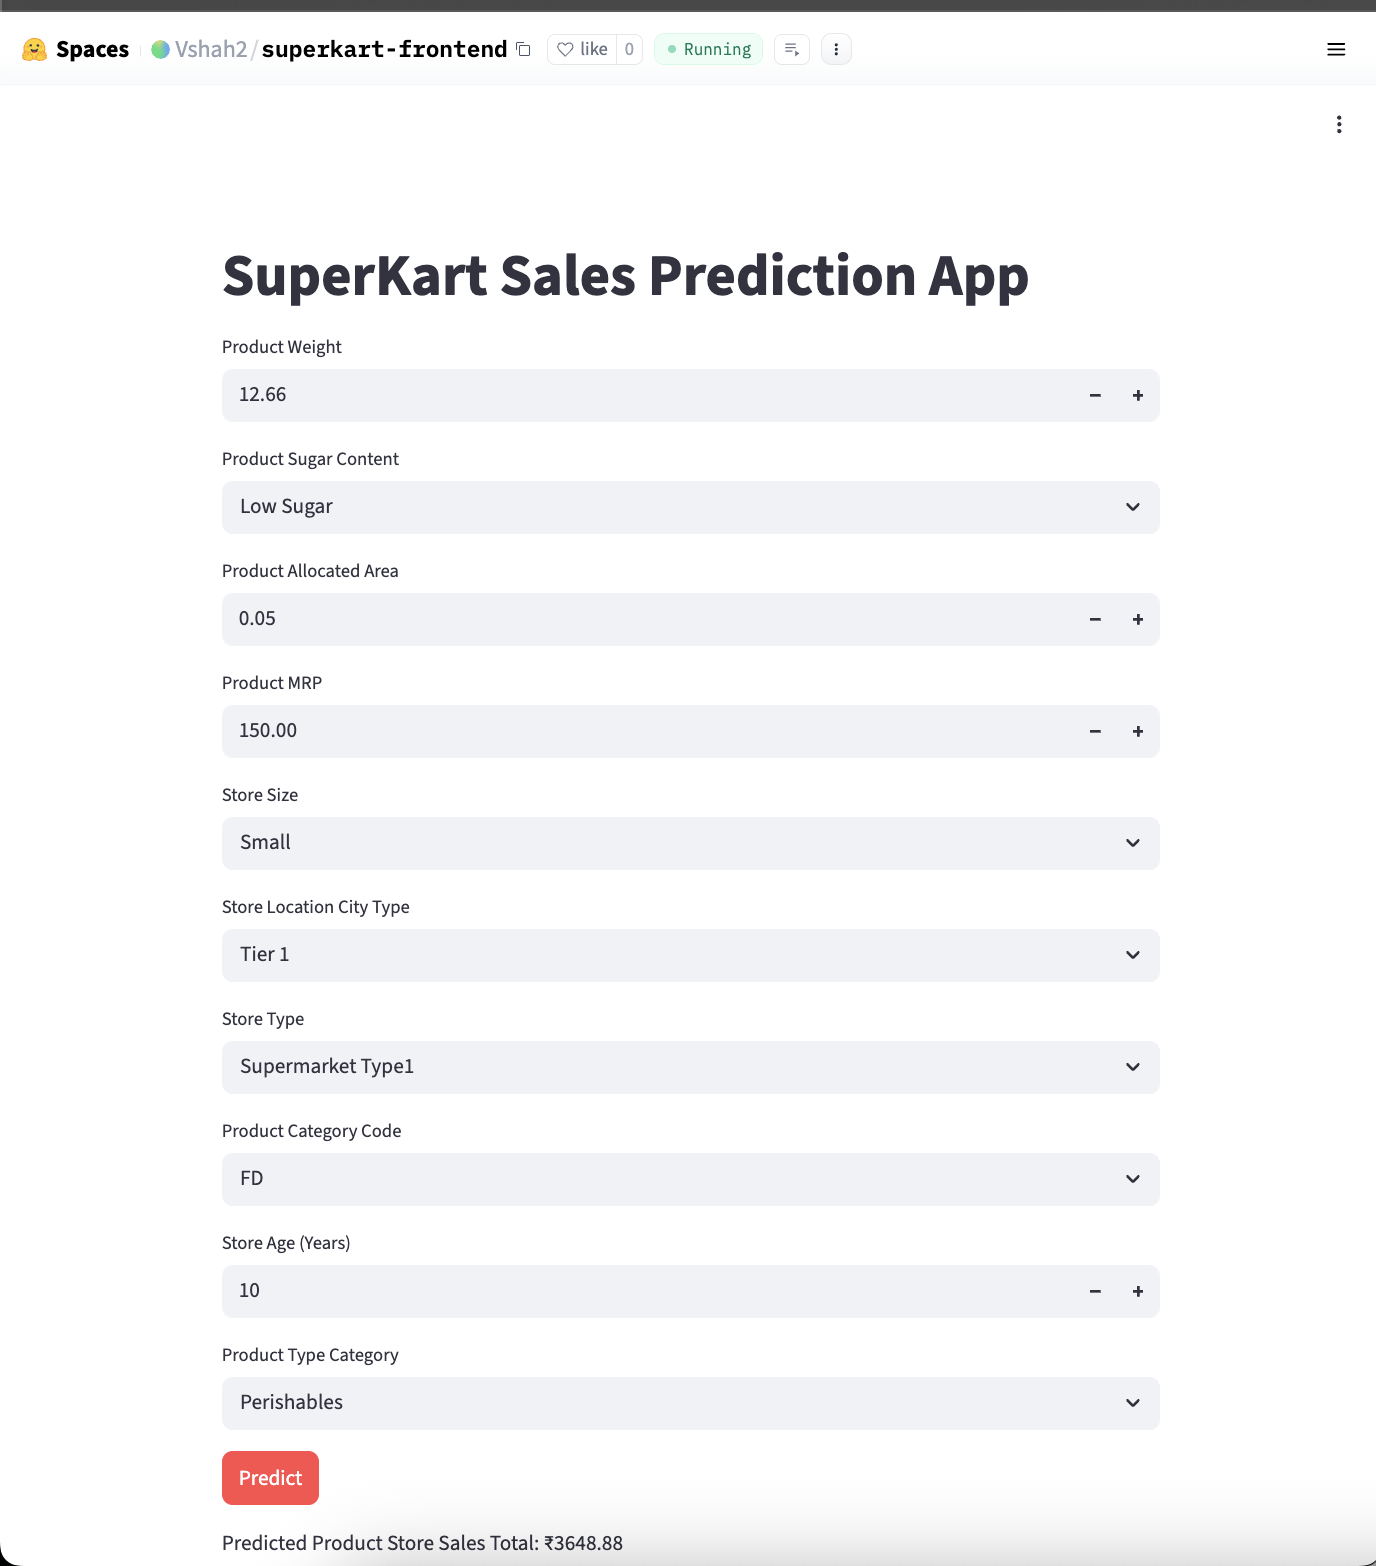

# **Actionable Insights and Business Recommendations**

### Actionable Business Insights & Recommendations

Based on the analysis and model results, the following key insights and actionable recommendations are derived:

---

### 1. Pricing Strategy Optimization (High Impact)

- Product MRP is the **strongest driver of sales**, indicating pricing directly influences revenue.

**Recommendation:**
- Identify **optimal price bands** instead of uniformly increasing prices  
- Run pricing experiments to balance demand and profitability  
- Use data-driven pricing strategies to maximize revenue  

---

### 2. Focus on High-Performing Stores

- Larger store formats and certain store types consistently generate higher sales.

**Recommendation:**
- Prioritize **investment and expansion** in high-performing stores  
- Improve assortment and customer experience in underperforming stores  

---

### 3. Location-Based Inventory Optimization

- Tier 1 and Tier 2 cities contribute significantly more to revenue.

**Recommendation:**
- Allocate **more inventory and premium products** to high-demand locations  
- Use targeted promotions to improve demand in Tier 3 cities  

---

### 4. Product Visibility & Store Layout

- Product visibility influences sales performance.

**Recommendation:**
- Optimize shelf placement for high-demand and high-margin products  
- Use data-driven store layout strategies to improve visibility  

---

### 5. Category-Level Optimization

- Food-related categories are the primary revenue drivers.

**Recommendation:**
- Increase stock and variety in high-performing categories  
- Optimize product mix based on demand patterns  

---

### 6. Model Performance & Usage

- The model explains approximately **66–67% of sales variation**  
- Prediction error is around **17–18%**

**Implication:**
- Suitable for:
  - trend analysis  
  - strategic planning  
- Not suitable for:
  - precise inventory decisions  
  - SKU-level forecasting  

---

### 7. Data Improvements for Better Predictions

The current dataset lacks key **dynamic business signals**.

High-impact data to include:
- Promotions and discounts  
- Seasonal and time-based trends  
- Customer behavior and demographics  
- Store footfall and traffic  
- Inventory and stock availability  
- Competitor pricing and market data  
- External factors (e.g., weather)

---

### 8. Business Feasibility & ROI Consideration

- The current model achieves moderate predictive performance, with:
  - R² around **0.66–0.68**
  - RMSE around **600–620**
  - MAPE around **16–19%**

- This means the model is able to capture broad sales patterns, but it may not be accurate enough for highly precise sales forecasting at an individual product-store level.

- From a business feasibility perspective, the model can still provide value as a **decision-support tool** for:
  - Identifying broad sales trends
  - Supporting inventory planning
  - Comparing expected demand across outlet types
  - Helping business teams make more data-informed planning decisions

#### Recommendation:

- The model should be used for **directional forecasting and planning support**, rather than as the only source for final inventory or pricing decisions.

- Before making a large-scale investment in full automation, SuperKart should evaluate whether the expected business benefit from improved forecasting is greater than the cost of deployment, monitoring, maintenance, and future data collection.

- To improve ROI, the business should first deploy the model in a limited pilot for selected products or stores, monitor prediction accuracy, and compare the results with current manual forecasting methods.

- If the pilot shows measurable improvement in reducing stockouts, overstocking, or planning effort, the model can then be scaled to more stores and product categories.

- For better long-term returns, SuperKart should also collect additional business data such as promotions, discounts, holidays, seasonality, local demand patterns, and competitor activity, as these factors may help improve future model performance.

---

### Final Business Takeaway

- Sales performance is primarily driven by:
  - pricing  
  - store characteristics  
  - product category and visibility  

- The model should be used as a **decision-support tool**, not a fully automated system  

- The business must make a strategic decision:

  > Whether current prediction accuracy is sufficient for deployment,  
  > or whether further investment in data and modeling is required  

- The most impactful next step is:

  > **Investing in better data and feature engineering rather than more complex models**

- This highlights key real-world principles:

  > **High-quality data is more valuable than complex modeling**  
  > **The value of ML depends on accuracy, cost, and business impact — not model complexity alone**

### Deployment Architecture

The final machine learning pipeline was serialized using joblib and deployed through a Flask backend hosted on Hugging Face Docker Space.

The system follows a simple client-server architecture:

- The Streamlit frontend collects user inputs such as product and store details.
- These inputs are sent to the Flask API endpoint (/v1/predict).
- The backend loads the serialized model pipeline and generates predictions.
- The predicted sales value is returned as a JSON response and displayed on the UI.

Flow:
User Input → Streamlit Frontend → Flask API → Serialized ML Pipeline → Prediction Response

This architecture enables real-time predictions and allows the model to be easily integrated into business applications.

### Limitations and Future Improvements

While the model provides useful insights, there are certain limitations:

- The model achieves an R² of approximately 0.66–0.67, indicating moderate predictive power.
- It may not be suitable for highly precise forecasting tasks such as SKU-level inventory planning.
- The dataset lacks important business drivers such as promotions, seasonality, competitor pricing, and customer behavior.
- The model assumes static patterns and does not account for time-based trends.

Future improvements:

- Incorporate time-series features such as seasonality and trends.
- Include additional business data like promotions, discounts, and external factors.
- Experiment with advanced models or ensemble stacking.
- Implement model monitoring and retraining pipelines to handle data drift.
- Deploy the solution in a production-grade environment with scalability and logging.